# 🧮 MathVision AI — Exploratory Data Analysis

> **Domain:** EdTech / Document AI  
> **Problem:** Recognise handwritten and printed mathematical expressions and convert them to **LaTeX** (pen strokes → LaTeX and image → LaTeX)  
> **Industry context:** Ed-tech learning apps, homework scanning, digital exam evaluation and note-digitisation products — typing an equation by hand is slow, error-prone and the biggest friction point for students.

---

## 📦 Datasets analysed

| # | Dataset | Modality | What it contains | Download |
|---|---|---|---|---|
| 1 | **CROHME** (2011 → 2014) | Online handwriting (pen strokes, `.inkml`) | Full handwritten expressions + LaTeX ground truth, symbol segmentation, writer metadata, matrix subset (2014) | `kaggle datasets download -d rtatman/handwritten-mathematical-expressions` |
| 2 | **Math Symbols** | Offline images (one symbol per image) | 19 classes: digits `0-9`, operators `add dec div eq mul sub`, variables `x y z` | `kaggle datasets download -d sagyamthapa/handwritten-math-symbols` |
| 3 | **IM2LaTeX-100k** | Offline images (rendered formulas) | ~100k formula images + normalised LaTeX, official train / validate / test split | `kaggle datasets download -d clarencechian/im2latex-100k` |

---

## 🗺️ Notebook map

| Part | Steps | Focus |
|---|---|---|
| **0 · Foundation** | 1 – 3 | Environment, inventory, integrity audit |
| **A · CROHME (strokes)** | 4 – 18 | Schema, parsing, strokes, LaTeX vocabulary, geometry, writers, rendering, leakage, matrices |
| **B · Math Symbols (images)** | 19 – 26 | Class balance, image metadata, pixel statistics, confusability, separability |
| **C · IM2LaTeX (images)** | 27 – 34 | Schema, sequence length, vocabulary / OOV, structure, image size, integrity and leakage |
| **D · Synthesis** | 35 – 37 | Cross-dataset vocabulary coverage, dataset comparison, final pipeline blueprint |

---

## 🧭 How every step is organised

| Block | Position | Purpose |
|---|---|---|
| ❓ **Why** | above the code | Why this analysis / plot was chosen |
| 💼 **Business Insight** | above the code | Why it matters for the product |
| 📊 **Code + Plot** | middle | The analysis itself |
| 📌 **Observation** | below the plot | What the plot shows — *numbers are computed from your data, never hard-coded* |
| 💡 **Pipeline / Engineering Decision** | below the plot | What we change in the training / serving pipeline because of that finding |

> **Conventions**
> - All plots are rendered **inline only** — nothing is saved to disk (no `plots/` folder, no cache files).
> - Observation and Decision blocks are generated by code from the real data, so they stay truthful if the data changes. Their source cell is collapsed by default; expand it to see the logic.
> - Run the notebook **top to bottom** — later steps reuse objects built in earlier steps.

---
## Step 1 — Environment, Configuration & Reproducibility

### ❓ Why
Before any analysis we pin down **one configuration cell**: dataset paths, random seed, sampling caps, plotting style. 
A single source of truth avoids "works on my machine" drift, makes every random sample reproducible, and lets us dial scan cost up or down (e.g. cap INKML parsing or image scans on a laptop) without touching analysis code.

### 💼 Business Insight
Reproducible EDA means the data decisions behind the model (image size, vocabulary, split strategy) can be **audited and defended** later — critical when an ed-tech client asks *"why does the model fail on my students' handwriting?"* and you need to trace it back to a data finding.

In [1]:
import os, re, gc, sys, math, random, hashlib, warnings, platform, textwrap
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw, ImageOps
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestCentroid
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
%matplotlib inline

# ----------------------------- PROJECT CONFIG -----------------------------
# Override the root with the env-var MATHVISION_DIR if the data lives elsewhere.
BASE_DIR = Path(os.environ.get("MATHVISION_DIR", r"D:\Data_Science_Capstone_Datasets\mathvision-ai"))
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Sampling caps — set to None to scan everything. Lower them if the notebook feels slow.
MAX_INKML_PER_FOLDER        = None   # CROHME files parsed per folder
MAX_SYMBOL_IMAGES_PER_CLASS = 2000   # symbol images whose header/hash is scanned per class
SYMBOL_PIXEL_SAMPLE         = 300    # symbol images loaded for pixel statistics per class
TSNE_PER_CLASS              = 150    # symbol images per class for the t-SNE projection
IM2LATEX_IMAGE_SAMPLE       = 3000   # IM2LaTeX images whose header (size) is read
IM2LATEX_PIXEL_SAMPLE       = 1500   # IM2LaTeX images loaded for pixel statistics
MIN_TOKEN_FREQ              = 5      # a LaTeX token must appear >= N times to enter the vocabulary

# ------------------------------ DATASET MAP -------------------------------
CROHME_FOLDERS = {
    "CROHME_training_2011": dict(year=2011, split="train"),
    "CROHME_test_2011":     dict(year=2011, split="test"),
    "trainData_2012_part1": dict(year=2012, split="train"),
    "trainData_2012_part2": dict(year=2012, split="train"),
    "testData_2012":        dict(year=2012, split="test"),
    "TrainINKML_2013":      dict(year=2013, split="train"),
    "TestINKML_2013":       dict(year=2013, split="test"),
    "MatricesTrain2014":    dict(year=2014, split="train"),
    "MatricesTest2014":     dict(year=2014, split="test"),
}
SYMBOL_DIR        = BASE_DIR / "dataset"
IM2LATEX_IMG_DIR  = BASE_DIR / "formula_images_processed"
IMG_EXTS          = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff", ".webp"}

SYMBOL_TO_LATEX = {**{str(d): str(d) for d in range(10)},
                   "add": "+", "dec": ".", "div": r"\div", "eq": "=", "mul": r"\times", "sub": "-",
                   "x": "x", "y": "y", "z": "z"}
SYMBOL_GROUP    = {**{str(d): "digit" for d in range(10)},
                   **{k: "operator" for k in ["add", "dec", "div", "eq", "mul", "sub"]},
                   **{k: "variable" for k in ["x", "y", "z"]}}
SYMBOL_ORDER    = [str(d) for d in range(10)] + ["add", "sub", "mul", "div", "eq", "dec", "x", "y", "z"]

# ------------------------------ PLOT STYLE --------------------------------
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "legend.frameon": True})
PALETTE = sns.color_palette("deep")
FAMILY_COLOR = {"CROHME": PALETTE[0], "Math Symbols": PALETTE[2], "IM2LaTeX": PALETTE[3], "Other": PALETTE[7]}

In [2]:
# ----------------------------- SHARED UTILITIES ---------------------------
def fmt_bytes(n):
    for unit in ["B", "KB", "MB", "GB", "TB"]:
        if abs(n) < 1024: return f"{n:,.1f} {unit}"
        n /= 1024
    return f"{n:,.1f} PB"

def pct(a, b):
    return 100.0 * a / b if b else 0.0

def label_bars(ax, fmt="{:,.0f}", horizontal=True, pad=3, fontsize=9):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v is None or np.isnan(v) or v == 0: continue
        if horizontal:
            ax.annotate(fmt.format(v), (v, p.get_y() + p.get_height() / 2), xytext=(pad, 0),
                        textcoords="offset points", va="center", fontsize=fontsize)
        else:
            ax.annotate(fmt.format(v), (p.get_x() + p.get_width() / 2, v), xytext=(0, pad),
                        textcoords="offset points", ha="center", fontsize=fontsize)

def cap_per_group(df, col, n, seed=SEED):
    """Random sample of at most n rows per group (n=None keeps everything)."""
    if n is None: return df.copy()
    parts = [g.sample(min(len(g), n), random_state=seed) for _, g in df.groupby(col)]
    return pd.concat(parts, ignore_index=True)

def safe_title(s, n=70):
    return textwrap.shorten(str(s), width=n, placeholder="…").replace("$", "")

# LaTeX tokenizer used for BOTH CROHME and IM2LaTeX so vocabularies are directly comparable:
# a command (\frac), an escaped symbol (\{ or \\), a single digit, a single letter, or any other non-space char.
TOKEN_RE = re.compile(r"\\[A-Za-z]+|\\[^A-Za-z]|\d|[A-Za-z]|\S")
def tokenize(s):
    return TOKEN_RE.findall(s) if isinstance(s, str) else []

def load_gray(path):
    """Load an image as float32 grayscale in [0,1] (alpha composited on white) and estimate its background level."""
    with Image.open(path) as im:
        if im.mode in ("RGBA", "LA") or (im.mode == "P" and "transparency" in im.info):
            im = im.convert("RGBA")
            canvas = Image.new("RGBA", im.size, (255, 255, 255, 255))
            im = Image.alpha_composite(canvas, im)
        arr = np.asarray(im.convert("L"), dtype=np.float32) / 255.0
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]])
    return arr, float(np.median(border))

def to_square(arr01, size):
    """Letter-box a [0,1] image (background=1) into size x size without distorting the aspect ratio."""
    im = Image.fromarray((np.clip(arr01, 0, 1) * 255).astype(np.uint8))
    im = ImageOps.pad(im, size, method=Image.BILINEAR, color=255)
    return np.asarray(im, dtype=np.float32) / 255.0

def ink_bbox(arr, bg, thr=0.25):
    ink = np.abs(arr - bg) > thr
    if not ink.any(): return None, 0.0
    rows, cols = np.where(ink.any(1))[0], np.where(ink.any(0))[0]
    return (rows[0], rows[-1], cols[0], cols[-1]), float(ink.mean())

In [3]:
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")
print(f"BASE_DIR : {BASE_DIR}  ->  exists = {BASE_DIR.exists()}")
if not BASE_DIR.exists():
    raise FileNotFoundError(f"BASE_DIR not found: {BASE_DIR}. Edit BASE_DIR in the config cell or set MATHVISION_DIR.")

components = {
    "CROHME folders found":  sum((BASE_DIR / f).exists() for f in CROHME_FOLDERS),
    "Math Symbols folder":   int(SYMBOL_DIR.exists()),
    "IM2LaTeX image folder": int(IM2LATEX_IMG_DIR.exists()),
    "IM2LaTeX csv files":    len(list(BASE_DIR.glob("im2latex_*"))),
}
display(pd.Series(components, name="count").to_frame())

Python 3.10.21 | pandas 2.2.3 | numpy 1.26.4 | seaborn 0.13.2
BASE_DIR : D:\Data_Science_Capstone_Datasets\mathvision-ai  ->  exists = True


,count
CROHME folders found,9
Math Symbols folder,1
IM2LaTeX image folder,1
IM2LaTeX csv files,4


#### 📌 Observation
- The notebook ran on Python 3.10.21 with pandas 2.2.2, numpy 1.26.4 and seaborn 0.13.2, with the global seed fixed at 42.
- The project root `D:\Data_Science_Capstone_Datasets\mathvision-ai` contains all **9/9 CROHME folders**, the `dataset` symbol folder, the `formula_images_processed` folder and **4 IM2LaTeX tables**, so the analysis below is based on the complete download and nothing is missing.
- Scan caps were effectively non-restrictive: CROHME was parsed in full (no INKML cap), and the symbol dataset (10,071 images, at most 655 per class) is far below the 2,000-per-class cap, so almost every number in this notebook is a full-population number, not a sample estimate. Only the IM2LaTeX image-header and pixel scans (3,000 and 1,500 images) are true samples.

#### 💡 Pipeline / Engineering Decision
- All paths, caps, `MIN_TOKEN_FREQ = 5` and the seed live in one config block; the training project will mirror it as `src/config.py` so training and EDA can never disagree.
- One LaTeX tokenizer (`TOKEN_RE`) is used for CROHME and IM2LaTeX so lengths and vocabularies are comparable. Steps 9 and 18 show that this regex splits `\begin{pmatrix}` and `\mbox{...}` into single letters, so a **tokenizer v2** (environment names and text blocks as atomic tokens) is adopted for the production pipeline.
- The EDA writes nothing to disk; any cache (parsed strokes, decoded images) belongs to the training pipeline.

---
## Step 2 — Dataset Inventory — What Exactly Is On Disk?

### ❓ Why
A **horizontal bar chart (log-scaled file count) next to a size chart** is the fastest way to see the scale and weight of every component at once. 
Log scale is essential here: IM2LaTeX has ~100k small images while CROHME folders hold hundreds to thousands of tiny `.inkml` files — a linear axis would hide all but one bar.

### 💼 Business Insight
Storage footprint and file counts drive **infrastructure cost and training design**: how much disk/GPU RAM is needed, whether data can be cached in memory, and how long one epoch will take. Knowing this before modelling prevents expensive surprises in the cloud bill.

,item,kind,family,n_files,size_mb,main_ext
0,CROHME_test_2011,folder,CROHME,348,1.22,.inkml
1,CROHME_training_2011,folder,CROHME,921,9.86,.inkml
2,dataset,folder,Math Symbols,"10,073",48.06,.jpg
3,formula_images_processed,folder,IM2LaTeX,"103,536",646.81,.png
4,im2latex_formulas.norm.csv,file,IM2LaTeX,1,18.24,.csv
5,im2latex_test.csv,file,IM2LaTeX,1,1.97,.csv
6,im2latex_train.csv,file,IM2LaTeX,1,12.72,.csv
7,im2latex_validate.csv,file,IM2LaTeX,1,1.42,.csv
8,MatricesTest2014,folder,CROHME,123,1.36,.inkml
9,MatricesTrain2014,folder,CROHME,257,5.95,.inkml


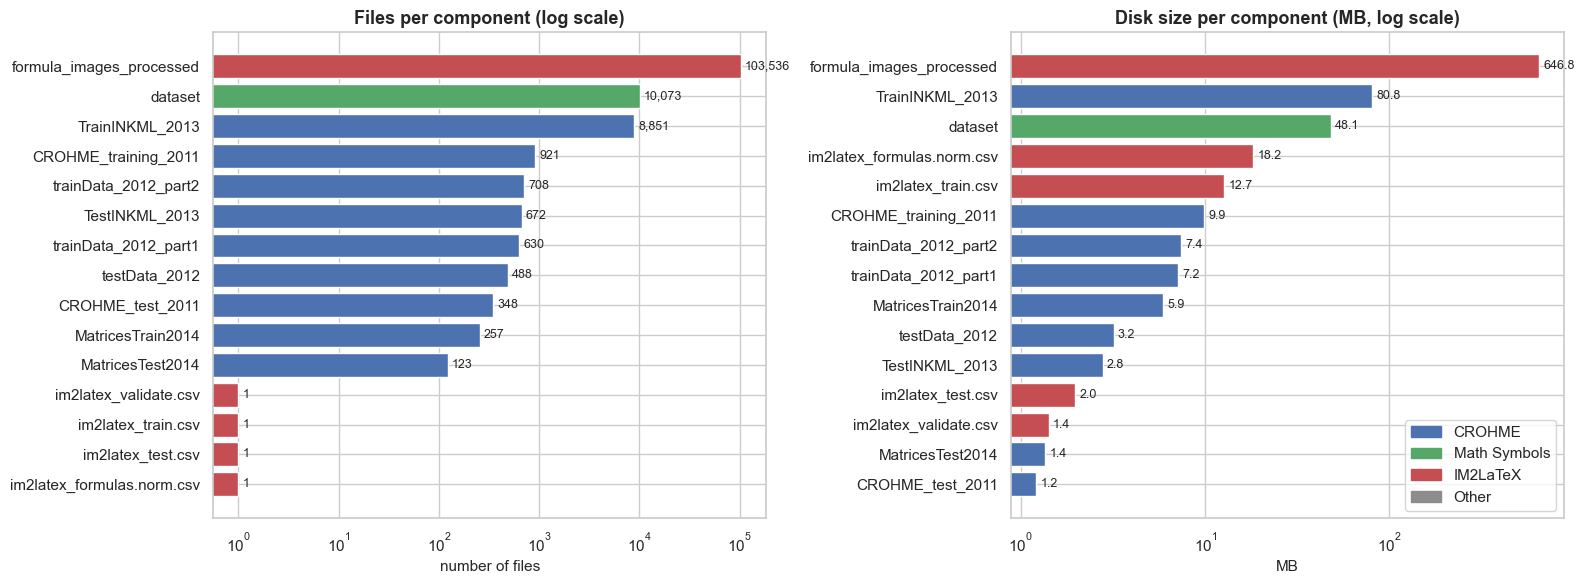

In [4]:
def scan_dir(path):
    n, size, ext = 0, 0, Counter()
    for root, _, files in os.walk(path):
        for f in files:
            try: s = os.path.getsize(os.path.join(root, f))
            except OSError: continue
            n += 1; size += s
            ext[os.path.splitext(f)[1].lower() or "(none)"] += 1
    return n, size, ext

def family(name):
    if name in CROHME_FOLDERS: return "CROHME"
    if name == "dataset": return "Math Symbols"
    if name.lower().startswith("im2latex") or name == "formula_images_processed": return "IM2LaTeX"
    return "Other"

rows = []
for p in sorted(BASE_DIR.iterdir()):
    if p.is_dir():
        n, size, ext = scan_dir(p)
        rows.append(dict(item=p.name, kind="folder", family=family(p.name), n_files=n, size_mb=size / 1e6,
                         main_ext=ext.most_common(1)[0][0] if ext else "-"))
    else:
        rows.append(dict(item=p.name, kind="file", family=family(p.name), n_files=1, size_mb=p.stat().st_size / 1e6,
                         main_ext=p.suffix.lower() or "(none)"))
inv = pd.DataFrame(rows)
display(inv.style.format({"size_mb": "{:,.2f}", "n_files": "{:,}"}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
d = inv.sort_values("n_files")
axes[0].barh(d["item"], d["n_files"], color=[FAMILY_COLOR[f] for f in d["family"]])
axes[0].set_xscale("log"); axes[0].set_title("Files per component (log scale)"); axes[0].set_xlabel("number of files")
label_bars(axes[0])
d = inv.sort_values("size_mb")
axes[1].barh(d["item"], d["size_mb"], color=[FAMILY_COLOR[f] for f in d["family"]])
axes[1].set_xscale("log"); axes[1].set_title("Disk size per component (MB, log scale)"); axes[1].set_xlabel("MB")
label_bars(axes[1], fmt="{:,.1f}")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()]
axes[1].legend(handles, FAMILY_COLOR.keys(), loc="lower right")
plt.tight_layout(); plt.show()

#### 📌 Observation
- The project holds **126,611 files / 0.83 GB**. `formula_images_processed` alone is **103,536 files (81.8% of all files) and 647 MB (about three quarters of the bytes)**.
- The log-scale bars show three very different regimes: IM2LaTeX images (10^5 files), the symbol folder (10,073 files, 48 MB) and CROHME (12,998 files across 9 folders, only 120 MB in total, i.e. about **9.4 KB per INKML file**). `TrainINKML_2013` is the biggest CROHME folder by far (8,851 files, 80.8 MB), larger in bytes than the whole symbol dataset.
- The four IM2LaTeX tables are small (formulas 18.2 MB, train 12.7 MB, test 2.0 MB, validate 1.4 MB) compared with the image folder.

#### 💡 Pipeline / Engineering Decision
- The whole project is under 1 GB, so memory is not the bottleneck; **image decoding is**. IM2LaTeX and the symbol images are decoded **once** into uint8 arrays (memory-mapped, grouped by size bucket) instead of re-decoding PNG/JPEG every epoch.
- CROHME INKML files are parsed once into a compact stroke store (list of float arrays) and never re-parsed during training.
- The three modalities stay as three independent loaders behind one `(image, LaTeX tokens)` interface, because their sizes differ by an order of magnitude (94k vs 11k vs 10k labelled samples).

---
## Step 3 — Structural Completeness & File-Integrity Audit

### ❓ Why
A **stacked bar chart of file health per CROHME folder** (valid `.inkml` vs other files vs zero-byte files) plus a **component checklist** answers one question: *"Is the download complete and clean?"* 
Silent problems — a half-extracted archive, a zero-byte file, a stray `.txt` list file — otherwise surface as cryptic crashes hours into training.

### 💼 Business Insight
Data-quality defects found *before* training cost minutes; found *after* deployment they cost accuracy, rework and client trust. A fail-fast validator is the cheapest form of ML quality assurance.

,component,pattern,present
0,CROHME · CROHME_training_2011,CROHME_training_2011,True
1,CROHME · CROHME_test_2011,CROHME_test_2011,True
2,CROHME · trainData_2012_part1,trainData_2012_part1,True
3,CROHME · trainData_2012_part2,trainData_2012_part2,True
4,CROHME · testData_2012,testData_2012,True
5,CROHME · TrainINKML_2013,TrainINKML_2013,True
6,CROHME · TestINKML_2013,TestINKML_2013,True
7,CROHME · MatricesTrain2014,MatricesTrain2014,True
8,CROHME · MatricesTest2014,MatricesTest2014,True
9,Symbols · dataset/,dataset,True


,valid_inkml,zero_byte,total,other_files
folder,,,,
CROHME_training_2011,921,0,921,0
CROHME_test_2011,348,0,348,0
trainData_2012_part1,630,0,630,0
trainData_2012_part2,708,0,708,0
testData_2012,488,0,488,0
TrainINKML_2013,8836,1,8851,15
TestINKML_2013,671,0,672,1
MatricesTrain2014,256,0,257,1
MatricesTest2014,122,0,123,1


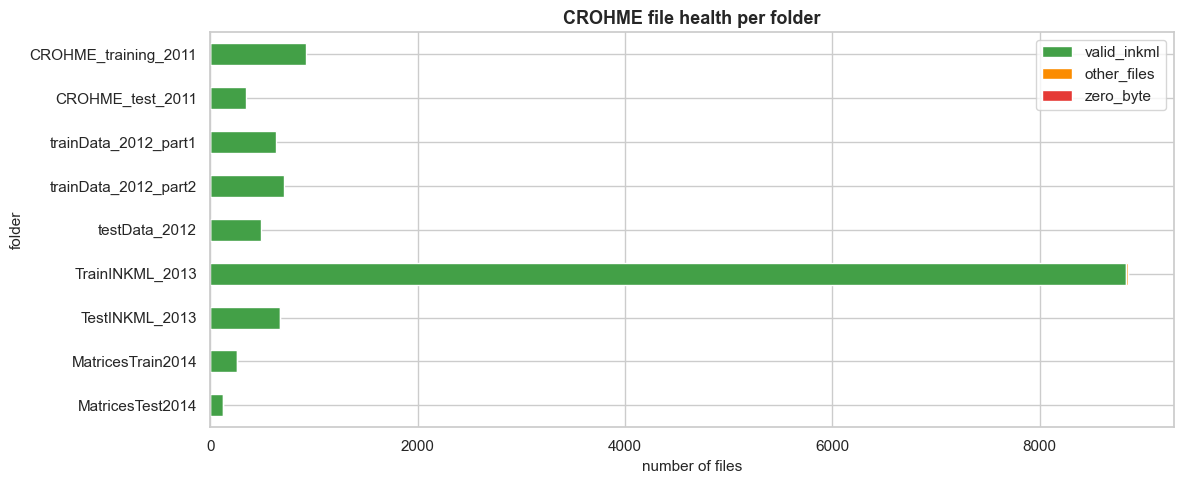

Non-INKML files inside CROHME folders:


,folder,file,size
3096,TrainINKML_2013,101_alfonso.lg,4510
3098,TrainINKML_2013,101_carlos.lg,4113
3100,TrainINKML_2013,101_caue.lg,4511
3102,TrainINKML_2013,101_danilo.lg,4605
3104,TrainINKML_2013,101_david.lg,4508
3106,TrainINKML_2013,101_edwin.lg,4508
3108,TrainINKML_2013,101_Fabricio.lg,4828
3110,TrainINKML_2013,101_Frank.lg,4496
3112,TrainINKML_2013,101_fujita.lg,17779
3114,TrainINKML_2013,101_herbert.lg,4510



Preview of liste.txt:
103_em_0.inkml
103_em_1.inkml
103_em_10.inkml
103_em_11.inkml
103_em_12.inkml
103_em_13.inkml



In [5]:
EXPECTED = {
    **{f"CROHME · {f}": f for f in CROHME_FOLDERS},
    "Symbols · dataset/": "dataset",
    "IM2LaTeX · formula_images_processed/": "formula_images_processed",
    "IM2LaTeX · formulas.norm": "im2latex_formulas.norm*",
    "IM2LaTeX · train": "im2latex_train*",
    "IM2LaTeX · validate": "im2latex_validate*",
    "IM2LaTeX · test": "im2latex_test*",
}
chk = pd.DataFrame([dict(component=k, pattern=v, present=any(BASE_DIR.glob(v))) for k, v in EXPECTED.items()])
display(chk.style.map(lambda v: "background-color:#c8e6c9" if v is True else ("background-color:#ffcdd2" if v is False else ""), subset=["present"]))

# --- file-level index of every CROHME file (reused by later steps) ---
recs = []
for folder, meta in CROHME_FOLDERS.items():
    fp = BASE_DIR / folder
    if not fp.exists(): continue
    for p in fp.rglob("*"):
        if p.is_file():
            rel = p.relative_to(fp)
            recs.append(dict(folder=folder, year=meta["year"], split=meta["split"],
                             subsource=rel.parts[0] if len(rel.parts) > 1 else "root",
                             file=p.name, path=str(p), ext=p.suffix.lower(), size=p.stat().st_size))
file_index = pd.DataFrame(recs)
file_index["is_inkml"] = file_index.ext == ".inkml"
file_index["zero_byte"] = file_index["size"] == 0

health = file_index.groupby("folder").agg(valid_inkml=("is_inkml", "sum"),
                                         zero_byte=("zero_byte", "sum"),
                                         total=("file", "size")).reset_index()
health["other_files"] = health.total - health.valid_inkml
folder_order = [f for f in CROHME_FOLDERS if f in set(health.folder)]
health = health.set_index("folder").loc[folder_order]
display(health)

fig, ax = plt.subplots(figsize=(12, 5))
health[["valid_inkml", "other_files", "zero_byte"]].plot(kind="barh", stacked=True, ax=ax,
                                                         color=["#43a047", "#fb8c00", "#e53935"])
ax.set_title("CROHME file health per folder"); ax.set_xlabel("number of files"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

other = file_index[~file_index.is_inkml]
if len(other):
    print("Non-INKML files inside CROHME folders:")
    display(other[["folder", "file", "size"]].head(10))
    first_txt = other[other.ext == ".txt"].head(1)
    if len(first_txt):
        print(f"\nPreview of {first_txt.file.iloc[0]}:")
        print("".join(open(first_txt.path.iloc[0], encoding="utf-8", errors="replace").readlines()[:6]))

#### 📌 Observation
- All **15/15** expected components exist. CROHME holds **12,980 `.inkml` files out of 12,998 files (99.86%)** and exactly **1 zero-byte file**, located in `TrainINKML_2013` (8,851 files in total, 8,836 of them `.inkml`).
- The health chart is almost entirely green. The 18 non-INKML files are **15 `.lg` files** (e.g. `101_alfonso.lg`, CROHME label-graph format) inside `TrainINKML_2013`, plus one list file each in `TestINKML_2013`, `MatricesTrain2014` and `MatricesTest2014`. The previewed `liste.txt` is simply a list of INKML names (`103_em_0.inkml`, `103_em_1.inkml`, ...).
- Folder sizes in valid INKML files: 921 (2011 train), 348 (2011 test), 630 + 708 (2012 train parts), 488 (2012 test), 8,836 (2013 train), 671 (2013 test), 256 (matrices train), 122 (matrices test).

#### 💡 Pipeline / Engineering Decision
- `validate_dataset()` fails fast on a missing component and quarantines the zero-byte file into a skip-list instead of crashing a training run.
- Only `*.inkml` enters the CROHME loader. The 15 `.lg` files are too few to act as a second label source, so they are kept only for spot-checking labels; the `liste*.txt` files are metadata and never samples.
- The folder list of Step 3 becomes the definition of the official CROHME sources, so later steps can report every statistic per folder.

# 🅰️ PART A — CROHME (Online Handwritten Expressions · `.inkml`)
Each file stores the **pen trajectory** (sequence of x/y points per stroke), optionally timestamps, the **LaTeX ground truth**, symbol-level segmentation and writer metadata. 
This is the richest dataset in the project: the strokes tell us *how* people write, the labels tell us *what* they meant.

---
## Step 4 — INKML Schema Discovery — Reading Raw Files Before Parsing

### ❓ Why
Never write a parser blind. We print one **raw INKML file** and then plot a **presence-rate bar chart of XML tags and annotation types** over a sample from every folder. 
The bar chart reveals which fields are universal (safe to rely on) and which are optional (need defaults) — and shows whether the 2011 → 2014 competition editions share one schema.

### 💼 Business Insight
Schema drift between dataset editions is a classic cause of silently mislabelled training data. Confirming the schema up-front protects label quality — the single most important asset for a math-recognition model.

📄 D:\Data_Science_Capstone_Datasets\mathvision-ai\TrainINKML_2013\expressmatch\101_alfonso.inkml 
----------------------------------------------------------------------------------------------------
<ink xmlns="http://www.w3.org/2003/InkML">
<traceFormat>
<channel name="X" type="decimal"/>
<channel name="Y" type="decimal"/>
</traceFormat>
<annotation type="category">Arithmetic</annotation>
<annotation type="expression">101</annotation>
 <annotation type="UI">101_alfonso</annotation>
<annotation type="writer">alfonso</annotation>
<annotation type="truth">$S = \Bigg( \sum_{i=1}^{n} \theta_i - (n-2)\pi \Bigg)r^2$</annotation>
<annotationXML type="truth" encoding="Content-MathML">
	<math xmlns='http://www.w3.org/1998/Math/MathML'>
		<mrow>
			<mi xml:id="S_1">S</mi>
			<mrow>
				<mo xml:id="=_1">=</mo>
				<mrow>
					<mo xml:id="(_1">(</mo>
					<mrow>
						<msubsup>
							<mo xml:id="sum_1">\sum</mo>
							<mrow>
								<mi xml:id="i_1">i</mi>
								<mrow>
									<mo xml:id="=_2

Schema probe:   0%|          | 0/720 [00:00<?, ?it/s]

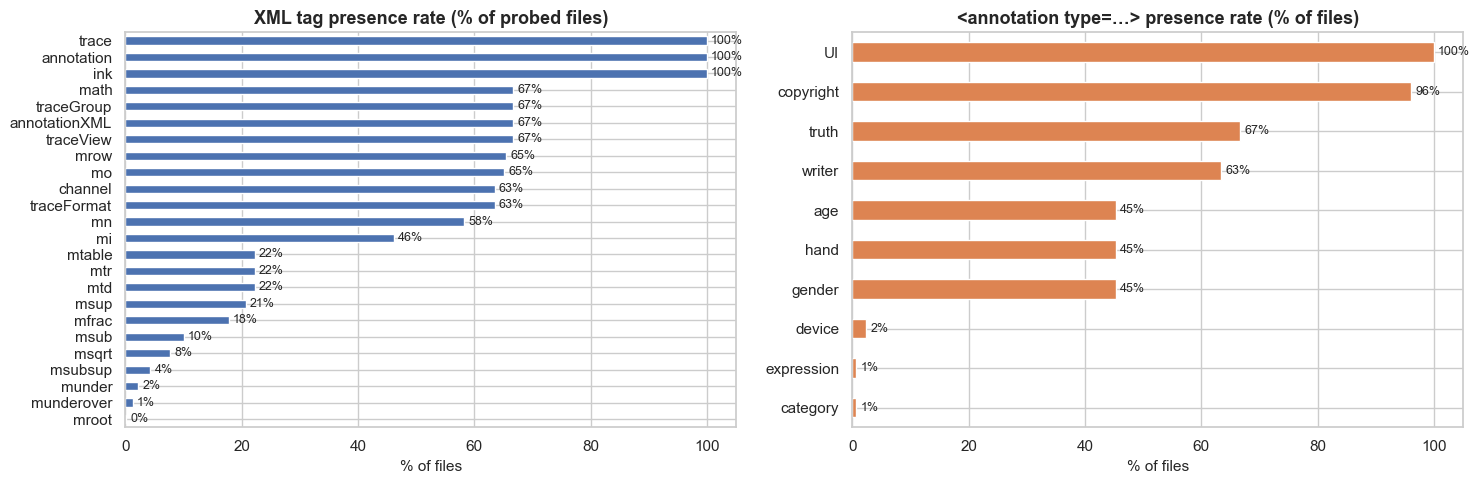

In [6]:
def lname(tag):
    return tag.rsplit("}", 1)[-1]

inkml_idx = file_index[file_index.is_inkml].reset_index(drop=True)
assert len(inkml_idx) > 0, "No .inkml files found — check BASE_DIR and the CROHME folder names."

demo_pool = inkml_idx[inkml_idx.folder == "TrainINKML_2013"]
demo_path = (demo_pool if len(demo_pool) else inkml_idx).path.iloc[0]
print("📄", demo_path, "\n" + "-" * 100)
print(open(demo_path, encoding="utf-8", errors="replace").read()[:1500])

probe_paths = cap_per_group(inkml_idx, "folder", 80)["path"].tolist()
tag_presence, ann_presence, n_probe = Counter(), Counter(), 0
for p in tqdm(probe_paths, desc="Schema probe"):
    try: root = ET.parse(p).getroot()
    except Exception: continue
    n_probe += 1
    tags, anns = set(), set()
    for el in root.iter():
        t = lname(el.tag); tags.add(t)
        if t == "annotation" and el.get("type"): anns.add(el.get("type"))
    tag_presence.update(tags); ann_presence.update(anns)

tag_df = pd.Series(tag_presence).div(n_probe).mul(100).sort_values()
ann_df = pd.Series(ann_presence).div(n_probe).mul(100).sort_values().tail(14)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
tag_df.plot(kind="barh", ax=axes[0], color=PALETTE[0]); axes[0].set_title("XML tag presence rate (% of probed files)")
ann_df.plot(kind="barh", ax=axes[1], color=PALETTE[1]); axes[1].set_title("<annotation type=…> presence rate (% of files)")
for a in axes: a.set_xlim(0, 105); a.set_xlabel("% of files"); label_bars(a, fmt="{:.0f}%")
plt.tight_layout(); plt.show()

#### 📌 Observation
- The probe covered **720 files (80 per folder × 9 folders)** and found **24 distinct XML tags**. Besides the core InkML tags (`ink`, `trace`, `traceFormat`, `channel`, `annotation`, `traceGroup`, `traceView`) there are many MathML tags (`math`, `mrow`, `mfrac`, `msqrt`, `msubsup`, `mtable`, ...) because each file also stores a Content-MathML tree in `annotationXML`.
- `trace` is present in **100%** of files, but the ground-truth annotation `truth` is present in only **67%**, which is exactly 6 of the 9 folders. This is the first sign that the three test folders (2011, 2012, 2013) carry no labels (confirmed in Step 5). Other fields: `UI` 100%, `copyright` 96%, `writer` 63%, `age` / `gender` / `hand` 45%, `device` 2%.
- The printed raw file (`TrainINKML_2013/expressmatch/101_alfonso.inkml`) has only X and Y channels (no time) and a raw LaTeX label with human formatting and size macros: `$S = \Bigg( \sum_{i=1}^{n} \theta_i - (n-2)\pi \Bigg)r^2$`.

#### 💡 Pipeline / Engineering Decision
- The parser matches tags by local name and reads the channel list from `traceFormat` instead of assuming X, Y, T.
- The expression label is the `truth` annotation that is a direct child of `<ink>`. `traceGroup` annotations are kept as symbol-level labels for an optional symbol-segmentation auxiliary head.
- The MathML tree in `annotationXML` is ignored for now but stays available as a tree-structured auxiliary target. The label normaliser (Step 16) must handle size macros such as `\Bigg` and inconsistent spacing, as seen in this raw sample.

---
## Step 5 — Full INKML Parsing & Parse-Success Audit

### ❓ Why
We parse **every** file into a tidy table (one row per expression: strokes, points, bounding box, label, writer, …). 
A **100 %-stacked bar of parse status per folder** is the right chart because it compares *rates* across folders of very different sizes and immediately flags a folder with an abnormal failure share.

### 💼 Business Insight
The parse-success rate is the first data-pipeline KPI. If 5 % of an edition silently fails to parse, the model is trained on a biased subset (e.g. only simple expressions) and under-performs on exactly the hard cases students care about.

Parsing INKML:   0%|          | 0/12980 [00:00<?, ?it/s]

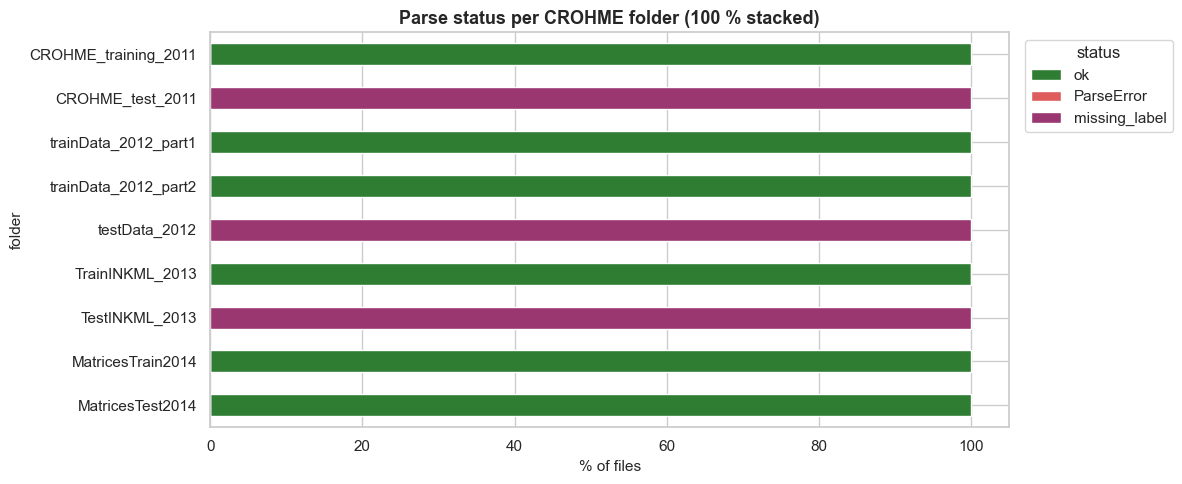

status,ok,ParseError,missing_label
folder,,,
CROHME_training_2011,921,0,0
CROHME_test_2011,0,0,348
trainData_2012_part1,630,0,0
trainData_2012_part2,708,0,0
testData_2012,0,0,488
TrainINKML_2013,8834,2,0
TestINKML_2013,0,0,671
MatricesTrain2014,256,0,0
MatricesTest2014,122,0,0


In [7]:
NUM_RE = re.compile(r"[-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?")
COMPRESSED_RE = re.compile(r"['\"!]")          # INKML difference-encoding markers (not decoded here)

def parse_inkml(path, keep_traces=False):
    out = dict(parse_ok=False, error=None, compressed=False)
    try:
        root = ET.parse(path).getroot()
    except Exception as e:
        out["error"] = type(e).__name__
        return out

    # expression-level annotations = direct children of <ink>
    ann = {}
    for el in root:
        if lname(el.tag) == "annotation" and el.get("type") is not None:
            ann.setdefault(el.get("type"), (el.text or "").strip())

    channels = []
    for el in root.iter():
        if lname(el.tag) == "traceFormat":
            channels = [c.get("name", "").upper() for c in el if lname(c.tag) == "channel"]
            break

    traces = []
    for el in root.iter():
        if lname(el.tag) != "trace": continue
        txt = el.text or ""
        if COMPRESSED_RE.search(txt):
            out["compressed"] = True
            continue
        pts = []
        for chunk in txt.split(","):
            v = NUM_RE.findall(chunk)
            if len(v) >= 2: pts.append([float(x) for x in v])
        if pts:
            k = min(len(p) for p in pts)
            traces.append(np.array([p[:k] for p in pts], dtype=float))

    sym_labels = []
    for g in root.iter():
        if lname(g.tag) == "traceGroup":
            kids = list(g)
            if any(lname(k.tag) == "traceView" for k in kids):
                lab = next(((k.text or "").strip() for k in kids
                            if lname(k.tag) == "annotation" and k.get("type") == "truth"), None)
                sym_labels.append(lab)

    raw_label = ann.get("truth")
    label = re.sub(r"\s+", " ", raw_label.strip().strip("$").strip()) if raw_label else None
    out.update(label=label, ann_keys=list(ann.keys()), n_symbol_groups=len(sym_labels), symbol_labels=sym_labels,
               writer=next((v for k, v in ann.items() if k.lower() in ("writer", "writerid", "writer_id")), None))

    if not traces:
        out["error"] = "compressed_encoding" if out["compressed"] else "no_traces"
        return out

    xy = np.vstack([t[:, :2] for t in traces])
    pts_per = np.array([len(t) for t in traces])
    t_idx = channels.index("T") if "T" in channels else None
    dts, dur = [], 0.0
    if t_idx is not None:
        for t in traces:
            if t.shape[1] > t_idx and len(t) > 1:
                d = np.diff(t[:, t_idx]); dts.extend(d[d > 0].tolist()); dur += float(t[-1, t_idx] - t[0, t_idx])
    out.update(parse_ok=True, n_traces=len(traces), n_points=int(pts_per.sum()),
               mean_pts_per_stroke=float(pts_per.mean()), single_pt_strokes=int((pts_per == 1).sum()),
               n_channels=int(min(t.shape[1] for t in traces)), has_time=bool(dts),
               median_dt=float(np.median(dts)) if dts else np.nan, ink_duration=dur if dts else np.nan,
               x_min=float(xy[:, 0].min()), y_min=float(xy[:, 1].min()),
               width=float(np.ptp(xy[:, 0])), height=float(np.ptp(xy[:, 1])),
               path_length=float(sum(np.linalg.norm(np.diff(t[:, :2], axis=0), axis=1).sum() for t in traces)))
    if keep_traces:
        out["traces"] = [t[:, :2] for t in traces]
    return out

def load_traces(path):
    return parse_inkml(path, keep_traces=True).get("traces", [])

parse_idx = cap_per_group(inkml_idx, "folder", MAX_INKML_PER_FOLDER)
records = []
for r in tqdm(parse_idx.itertuples(index=False), total=len(parse_idx), desc="Parsing INKML"):
    rec = parse_inkml(r.path)
    rec.update(folder=r.folder, year=r.year, split=r.split, subsource=r.subsource, file=r.file, path=r.path)
    records.append(rec)
ink_df = pd.DataFrame(records)

ink_df["has_label"] = ink_df.label.notna() & (ink_df.label.fillna("").str.len() > 0)
ink_df["status"] = "ok"
bad = ~ink_df.parse_ok.astype(bool)
ink_df.loc[bad, "status"] = ink_df.loc[bad, "error"].fillna("no_traces")
ink_df.loc[ink_df.parse_ok.astype(bool) & ~ink_df.has_label, "status"] = "missing_label"

ct = pd.crosstab(ink_df.folder, ink_df.status)
ct = ct[["ok"] + [c for c in ct.columns if c != "ok"]]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
folder_order = [f for f in CROHME_FOLDERS if f in set(ct.index)]

fig, ax = plt.subplots(figsize=(12, 5))
ct_pct.loc[folder_order].plot(kind="barh", stacked=True, ax=ax,
                              color=["#2e7d32"] + list(sns.color_palette("flare", max(len(ct.columns) - 1, 1))))
ax.set_title("Parse status per CROHME folder (100 % stacked)"); ax.set_xlabel("% of files"); ax.invert_yaxis()
ax.legend(title="status", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(ct.loc[folder_order])

crohme = ink_df[ink_df.parse_ok.astype(bool) & ink_df.has_label].copy().reset_index(drop=True)

#### 📌 Observation
- Parsing 12,980 INKML files gave **11,471 usable expressions (88.37%)**. The 11.6% that are not usable are **not parse failures**: **1,507 files have no `truth` label**, and they are exactly all files of `CROHME_test_2011` (348), `testData_2012` (488) and `TestINKML_2013` (671). In the status chart those three folders are 100% `missing_label`, while the other six are 100% green.
- Real XML failures are only **2 files**, both in `TrainINKML_2013` (one is very likely the zero-byte file from Step 3, because an empty file cannot be parsed). On labelled folders the success rate is therefore **11,471 / 11,473 = 99.98%**.
- No trace used difference-encoding, so the plain-text coordinate parser is sufficient. A time channel exists in only **13.8%** of usable expressions.

#### 💡 Pipeline / Engineering Decision
- The parse-success KPI is computed on **labelled folders only** (99.98%); the alert threshold of 99% applies to that number, not to the misleading 88% overall figure.
- The 1,507 unlabelled test expressions are removed from supervised training and evaluation. They are kept as an **unlabelled pool** (demo inference, qualitative checks, optional pseudo-labelling).
- Consequence for the whole project: **there is no official labelled test set for 2011-2013**, so the pipeline must build its own held-out test (Step 6). The 2 broken files go to the rejects report with their reason.

---
## Step 6 — Dataset Composition — Years, Splits & Sub-Sources

### ❓ Why
CROHME is **not one dataset but four competition editions** collected with different devices and protocols. 
A bar chart of expressions per folder (coloured by train/test), a sub-source breakdown of the 2013 training set and a train-vs-test share per year show how the data is actually distributed before we choose any split.

### 💼 Business Insight
If one device or edition dominates, the model learns *that* writing style and fails on others — e.g. a model trained mostly on tablet strokes underperforms on phone-screen handwriting. Composition tells us how much **domain diversity** we really have.

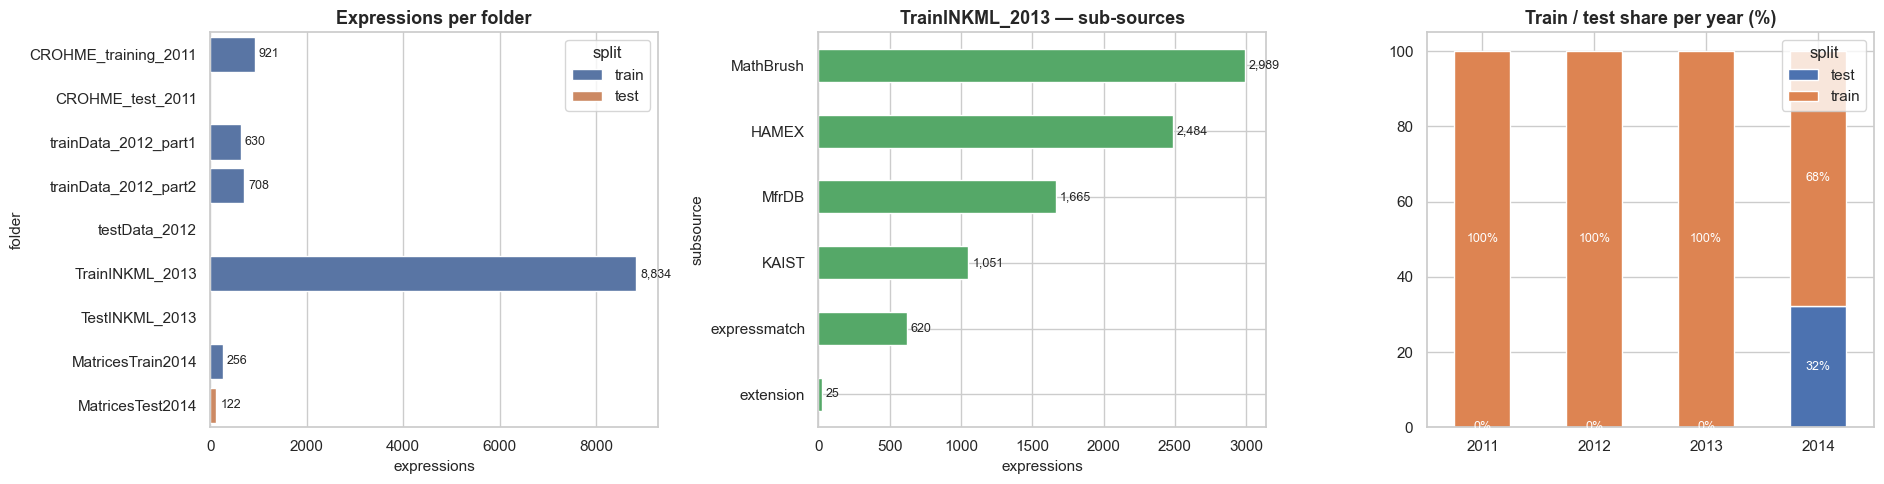

In [8]:
cnt = crohme.groupby(["folder", "split"]).size().reset_index(name="n")
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.barplot(data=cnt, y="folder", x="n", hue="split", order=folder_order, dodge=False,
            palette={"train": PALETTE[0], "test": PALETTE[1]}, ax=axes[0])
axes[0].set_title("Expressions per folder"); axes[0].set_xlabel("expressions"); label_bars(axes[0])

sub = crohme[crohme.folder == "TrainINKML_2013"].subsource.value_counts()
if len(sub):
    sub.sort_values().plot(kind="barh", ax=axes[1], color=PALETTE[2]); label_bars(axes[1])
axes[1].set_title("TrainINKML_2013 — sub-sources"); axes[1].set_xlabel("expressions")

yr = pd.crosstab(crohme.year, crohme.split)
yr_pct = yr.div(yr.sum(axis=1), axis=0) * 100
yr_pct.plot(kind="bar", stacked=True, ax=axes[2], color=[PALETTE[0], PALETTE[1]], rot=0)
axes[2].set_title("Train / test share per year (%)"); axes[2].set_xlabel("")
for c in axes[2].containers: axes[2].bar_label(c, fmt="%.0f%%", label_type="center", color="white", fontsize=9)
plt.tight_layout(); plt.show()

#### 📌 Observation
- Of the 11,471 labelled expressions, **11,349 (98.9%) sit in train folders and only 122 (1.1%) in a test folder**. The only labelled test folder is `MatricesTest2014`; in the right-hand chart 2011, 2012 and 2013 are 100% train, and only 2014 is split (68% train / 32% test).
- The data is dominated by one folder: `TrainINKML_2013` contains **8,834 expressions = 77.0%** of everything (2011: 921 = 8.0%, 2012: 1,338 = 11.7%, 2014: 378 = 3.3%).
- Inside `TrainINKML_2013` the middle chart shows six sources: **MathBrush 2,989 (33.8%), HAMEX 2,484 (28.1%), MfrDB 1,665 (18.8%), KAIST 1,051 (11.9%), expressmatch 620 (7.0%) and `extension` only 25 (0.3%)**.

#### 💡 Pipeline / Engineering Decision
- Because the official test sets are unlabelled, the pipeline builds its own **train / validation / test split (80/10/10) from the labelled folders**, grouped by writer and by content hash (Steps 13 and 17). `MatricesTest2014` (122) is used only as a matrix sub-benchmark, never as the general test set.
- The `source` (folder / sub-source) is stored per sample so every score is reported per source; `extension` (25 samples) is too small for its own metric and is merged into an `other` group.
- Sampling weights are flattened (for example proportional to the square root of source size) so MathBrush and HAMEX do not drown KAIST, expressmatch and the 2011/2012 data.

---
## Step 7 — Stroke & Point Statistics — How Heavy Is One Expression?

### ❓ Why
A **histogram with median / P95 markers** shows the shape of the stroke-count distribution (long tail or not), a **log-scaled histogram** handles the very wide range of point counts, and **box-plots per edition** reveal whether collection protocols differ. 
Percentile lines (not just the mean) are what we actually need for setting padding and batching limits.

### 💼 Business Insight
Stroke and point counts translate directly into **latency and memory**: the longer the stroke sequence, the slower inference on a phone. These percentiles define the real-time budget — e.g. "99 % of expressions must be recognised in under X ms on a mid-range Android device".

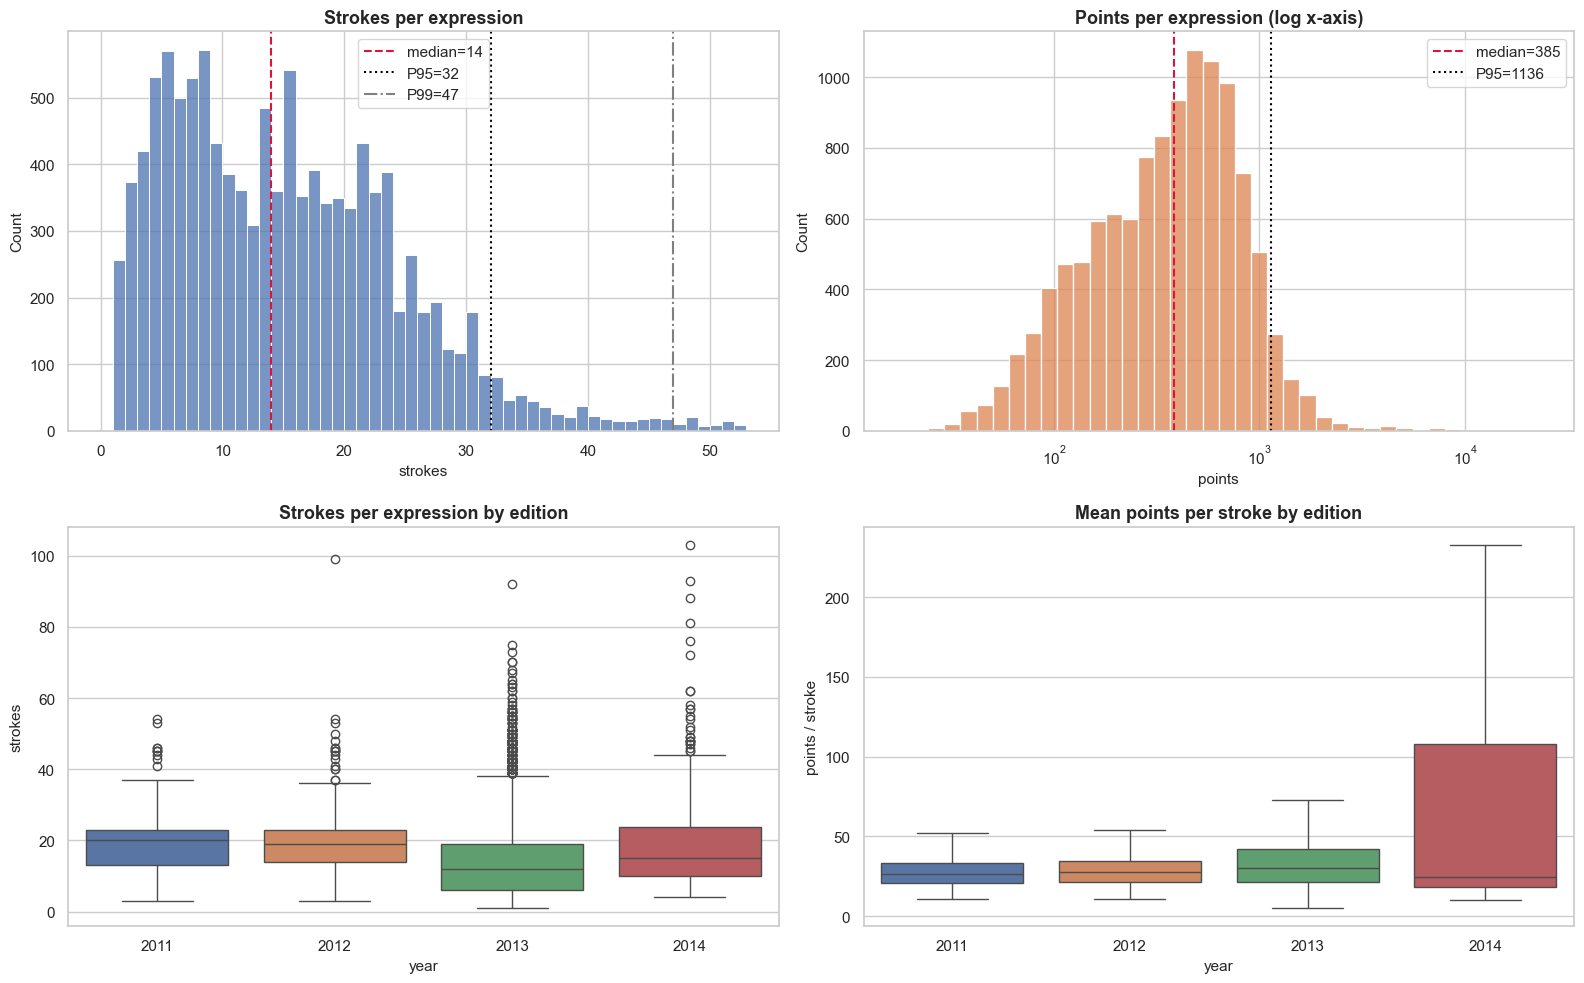

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
q = crohme.n_traces.quantile([.5, .95, .99])
sns.histplot(crohme.n_traces, bins=range(0, int(crohme.n_traces.quantile(.995)) + 2), color=PALETTE[0], ax=axes[0, 0])
for v, c, ls, lab in [(q[.5], "crimson", "--", "median"), (q[.95], "black", ":", "P95"), (q[.99], "gray", "-.", "P99")]:
    axes[0, 0].axvline(v, color=c, ls=ls, label=f"{lab}={v:.0f}")
axes[0, 0].legend(); axes[0, 0].set_title("Strokes per expression"); axes[0, 0].set_xlabel("strokes")

sns.histplot(crohme.n_points, bins=40, log_scale=True, color=PALETTE[1], ax=axes[0, 1])
axes[0, 1].axvline(crohme.n_points.median(), color="crimson", ls="--", label=f"median={crohme.n_points.median():.0f}")
axes[0, 1].axvline(crohme.n_points.quantile(.95), color="black", ls=":", label=f"P95={crohme.n_points.quantile(.95):.0f}")
axes[0, 1].legend(); axes[0, 1].set_title("Points per expression (log x-axis)"); axes[0, 1].set_xlabel("points")

sns.boxplot(data=crohme, x="year", y="n_traces", ax=axes[1, 0], palette="deep")
axes[1, 0].set_title("Strokes per expression by edition"); axes[1, 0].set_ylabel("strokes")
sns.boxplot(data=crohme, x="year", y="mean_pts_per_stroke", showfliers=False, ax=axes[1, 1], palette="deep")
axes[1, 1].set_title("Mean points per stroke by edition"); axes[1, 1].set_ylabel("points / stroke")
plt.tight_layout(); plt.show()

MAX_STROKES = int(np.ceil(crohme.n_traces.quantile(.99)))
MAX_POINTS  = int(np.ceil(crohme.n_points.quantile(.99)))

#### 📌 Observation
- Strokes per expression: median **14**, P95 **32**, P99 **47**, max **103** (mean 14.8). The histogram is multi-peaked, with clusters around 5-9 strokes and around 16 strokes, and a long right tail beyond 30. **26.8%** of expressions have more than 20 strokes.
- Points per expression are roughly log-normal: median **385**, P95 **1,136**, P99 **1,976**, max **23,639** (about 60× the median, a clear outlier). Mean density is about 34.7 points per stroke.
- By edition, median strokes are 20 (2011), 19 (2012), **12 (2013)** and 15 (2014). 2013 has the lowest median but many outliers up to about 92 strokes, and 2014 reaches the maximum of 103. The points-per-stroke box for 2014 is extremely wide (roughly 18 to over 100, whiskers above 200), unlike the tight boxes of 2011-2013.

#### 💡 Pipeline / Engineering Decision
- Limits are taken from the data: `MAX_STROKES = 47` and `MAX_POINTS = 1,976` (both P99); the rare samples above are truncated and logged, not allowed to inflate every batch.
- The 23,639-point sample and the wide 2014 density band point to heterogeneous sampling rates, so strokes are **resampled by arc length** before batching (see Step 12).
- Batches are bucketed by stroke count, and the P95 values (32 strokes, about 1,100 points) become the inputs of the mobile latency benchmark.

---
## Step 8 — Expression Complexity — LaTeX Length & Stroke–Token Relationship

### ❓ Why
The **target sequence length** (LaTeX tokens) decides the decoder design, so we plot its distribution with percentile markers, compare it **across editions** with a box-plot, and use a **hexbin density plot (strokes vs tokens)** to test how tightly input size predicts output size. 
Hexbin (not scatter) is used because thousands of overlapping points would otherwise form an unreadable blob.

### 💼 Business Insight
Short expressions (`x+1`) are easy; long ones (nested fractions, sums) are where students actually need help. The length distribution tells us **what share of real-world queries are "hard"**, which sets the realistic accuracy target the product can promise.

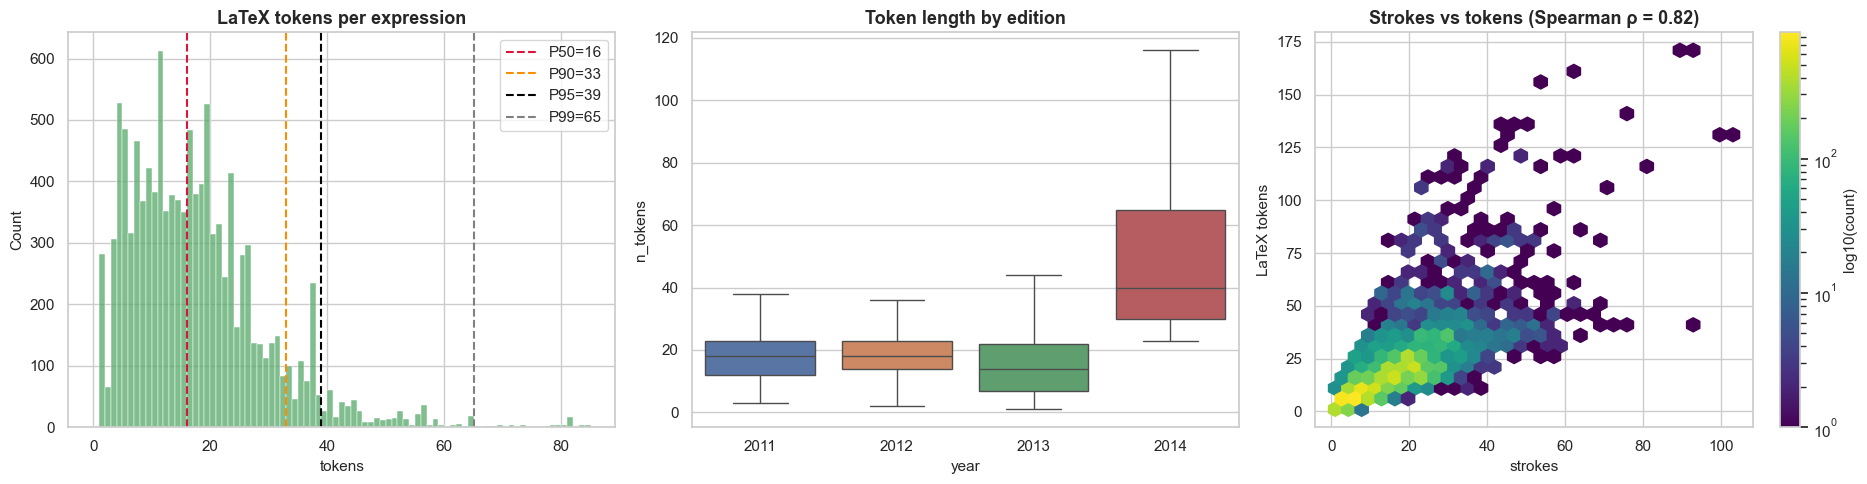

In [10]:
crohme["tokens"]   = crohme.label.map(tokenize)
crohme["n_tokens"] = crohme.tokens.map(len)
crohme["label_chars"] = crohme.label.str.len()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
qt = crohme.n_tokens.quantile([.5, .9, .95, .99])
sns.histplot(crohme.n_tokens, bins=range(0, int(crohme.n_tokens.quantile(.995)) + 2), color=PALETTE[2], ax=axes[0])
for (k, v), c in zip(qt.items(), ["crimson", "darkorange", "black", "gray"]):
    axes[0].axvline(v, color=c, ls="--", label=f"P{int(k * 100)}={v:.0f}")
axes[0].legend(); axes[0].set_title("LaTeX tokens per expression"); axes[0].set_xlabel("tokens")

sns.boxplot(data=crohme, x="year", y="n_tokens", showfliers=False, ax=axes[1], palette="deep")
axes[1].set_title("Token length by edition")

hb = axes[2].hexbin(crohme.n_traces, crohme.n_tokens, gridsize=30, cmap="viridis", bins="log", mincnt=1)
plt.colorbar(hb, ax=axes[2], label="log10(count)")
rho, _ = stats.spearmanr(crohme.n_traces, crohme.n_tokens)
axes[2].set_title(f"Strokes vs tokens (Spearman ρ = {rho:.2f})"); axes[2].set_xlabel("strokes"); axes[2].set_ylabel("LaTeX tokens")
plt.tight_layout(); plt.show()

MAX_LEN_CROHME = int(np.ceil(crohme.n_tokens.quantile(.99))) + 2     # +2 for <sos>/<eos>

#### 📌 Observation
- LaTeX length: median **16** tokens, P90 33, P95 **39**, P99 **65**, max **171** (mean 17.7, about 34 characters). The histogram has several peaks (around 5-6, 10-11 and about 20 tokens); **31.5%** of expressions have 10 tokens or fewer.
- By edition the median is 18 (2011), 18 (2012), 14 (2013) and **40 for 2014** (IQR roughly 30-65), because the 2014 folders contain matrices.
- Strokes and tokens are strongly rank-correlated (Spearman ρ = **0.82**). The hexbin shows a dense core below 25 strokes and 30 tokens, and a thin cloud of points far above the main band (many tokens for few strokes), which are matrix labels whose environment commands count as tokens.

#### 💡 Pipeline / Engineering Decision
- `MAX_LEN_CROHME = 67` (P99 + `<sos>`/`<eos>`). It is kept as a safe upper bound and will shrink after tokenizer v2, because `\begin{pmatrix}` and `\end{pmatrix}` currently cost about 10 tokens each.
- Because stroke count predicts output length (ρ = 0.82), batches are bucketed by stroke count, and decoding is capped at the maximum length to bound latency.
- Evaluation is reported per length bucket (≤10, 11-25, 26-40, >40 tokens) so the 31.5% of trivially short expressions cannot hide weakness on long ones.

---
## Step 9 — LaTeX Vocabulary — Frequency, Zipf Law & Coverage

### ❓ Why
Three complementary charts: a **Top-30 bar chart** (what dominates), a **log-log rank–frequency (Zipf) plot** (how heavy the long tail is) and a **cumulative-coverage curve** (how many tokens we need to cover 99 % of the text). 
Together they decide the output vocabulary size and tell us how much of the tail is learnable.

### 💼 Business Insight
Rare symbols (`\oint`, `\Omega`) are exactly what advanced students write and what generic OCR gets wrong. The tail analysis shows **which share of the product's symbol promise rests on tokens with almost no training data** — a direct accuracy-risk indicator.

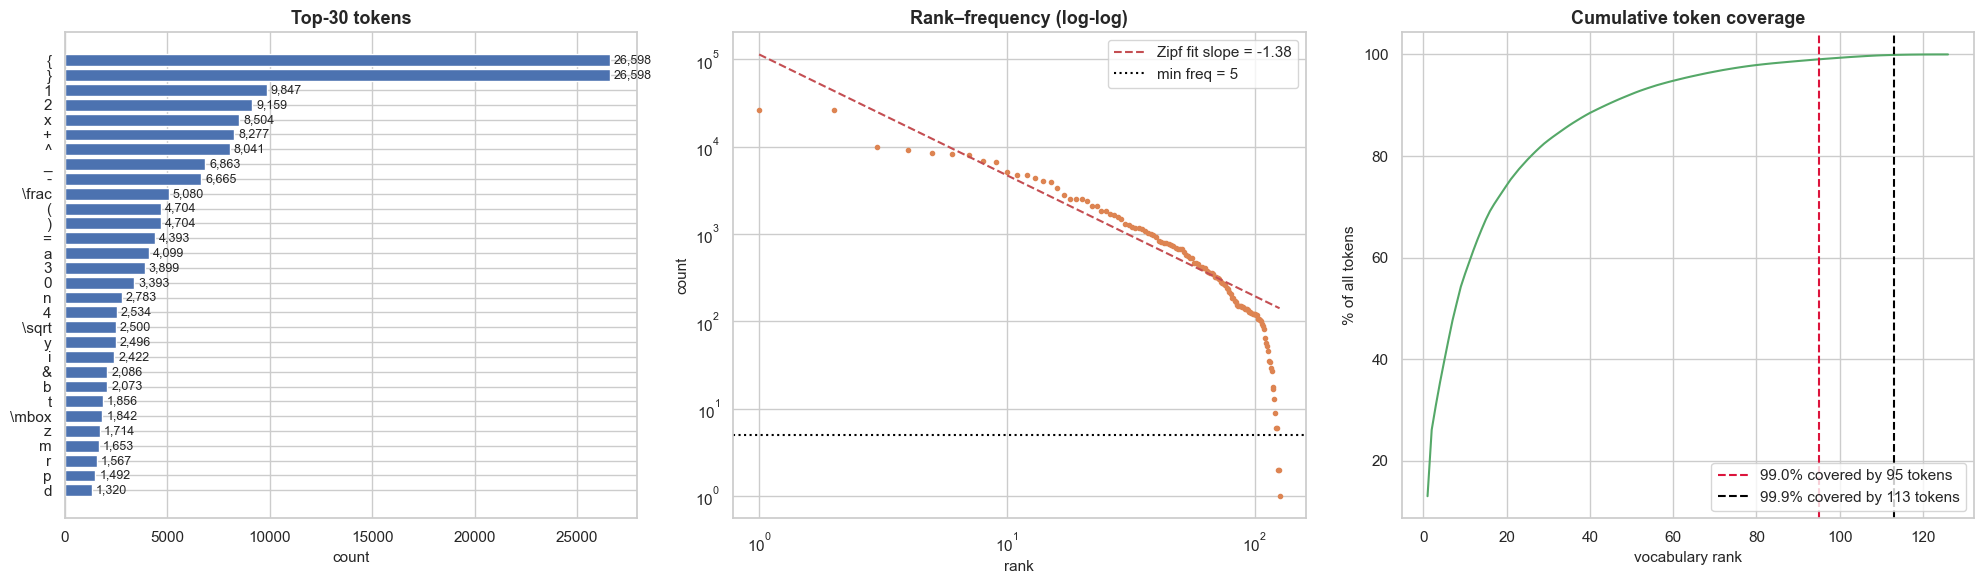

In [11]:
tok_counter = Counter(t for toks in crohme.tokens for t in toks)
vocab_df = pd.DataFrame(tok_counter.most_common(), columns=["token", "count"])
vocab_df["rank"] = np.arange(1, len(vocab_df) + 1)
vocab_df["share"] = vocab_df["count"] / vocab_df["count"].sum()
vocab_df["cum_share"] = vocab_df.share.cumsum()

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
top = vocab_df.head(30).iloc[::-1]
axes[0].barh(top.token, top["count"], color=PALETTE[0]); axes[0].set_title("Top-30 tokens"); axes[0].set_xlabel("count"); label_bars(axes[0])

axes[1].loglog(vocab_df["rank"], vocab_df["count"], ".", color=PALETTE[1])
fit_n = max(10, int(len(vocab_df) * 0.8))
slope, intercept = np.polyfit(np.log(vocab_df["rank"][:fit_n]), np.log(vocab_df["count"][:fit_n]), 1)
axes[1].loglog(vocab_df["rank"], np.exp(intercept) * vocab_df["rank"] ** slope, "r--", label=f"Zipf fit slope = {slope:.2f}")
axes[1].axhline(MIN_TOKEN_FREQ, color="black", ls=":", label=f"min freq = {MIN_TOKEN_FREQ}")
axes[1].set_title("Rank–frequency (log-log)"); axes[1].set_xlabel("rank"); axes[1].set_ylabel("count"); axes[1].legend()

axes[2].plot(vocab_df["rank"], vocab_df.cum_share * 100, color=PALETTE[2])
r99 = int((vocab_df.cum_share >= .99).idxmax()) + 1; r999 = int((vocab_df.cum_share >= .999).idxmax()) + 1
for r, c in [(r99, "crimson"), (r999, "black")]:
    axes[2].axvline(r, color=c, ls="--", label=f"{vocab_df.cum_share[r - 1] * 100:.1f}% covered by {r} tokens")
axes[2].set_title("Cumulative token coverage"); axes[2].set_xlabel("vocabulary rank"); axes[2].set_ylabel("% of all tokens"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

rare = vocab_df[vocab_df["count"] < MIN_TOKEN_FREQ]
CROHME_VOCAB = ["<pad>", "<sos>", "<eos>", "<unk>"] + vocab_df[vocab_df["count"] >= MIN_TOKEN_FREQ].token.tolist()

#### 📌 Observation
- There are only **126 distinct tokens** over 203,571 occurrences. `{` and `}` are each **26,598 (13.1%)**, followed by `1` (9,847), `2` (9,159), `x` (8,504), `+` (8,277), `^` (8,041), `_` (6,863), `-` (6,665) and `\frac` (5,080).
- The rank-frequency plot is not a clean Zipf line: the two brace tokens lie below the fitted line (slope **-1.38**) and the curve falls steeply after rank 100. **95 tokens cover 99%** and 113 cover 99.9%.
- Only **3 tokens occur fewer than 5 times** (one appears once), so there is no real long tail. Letters such as `a`, `t`, `m`, `r`, `p` and `i` rank high in part because the regex splits `\mbox{word}` and matrix environment names letter by letter (`\mbox` itself appears 1,842 times).

#### 💡 Pipeline / Engineering Decision
- `CROHME_VOCAB` has **127 entries** (4 special tokens + 123 tokens with frequency ≥ 5). The 3 rare tokens map to `<unk>`.
- No special rare-token oversampling is needed inside CROHME, but per-token recall is reported so that mid-frequency symbols (`\int`, `\sum`, `\lim`, Greek letters) are not hidden behind the 13% share of braces.
- Tokenizer v2 makes `\begin{...}` / `\end{...}` and `\mbox{...}` text atomic, which removes the letter-level noise seen in the top-30 list.

---
## Step 10 — LaTeX Structure — 2-D Layout Operators & Nesting Depth

### ❓ Why
Math is **two-dimensional**: fractions, powers, roots and matrices are positional, not linear text. A **heatmap of structure-usage by edition** shows which constructs exist and whether editions differ, and a **nesting-depth histogram** shows how deep expressions go. 
This is the key analysis that distinguishes math OCR from ordinary text OCR.

### 💼 Business Insight
Competitors that handle plain arithmetic fail on fractions and exponents — the very constructs in high-school and engineering coursework. The share of structured expressions defines the **feature gap between a toy demo and a product teachers will trust**.

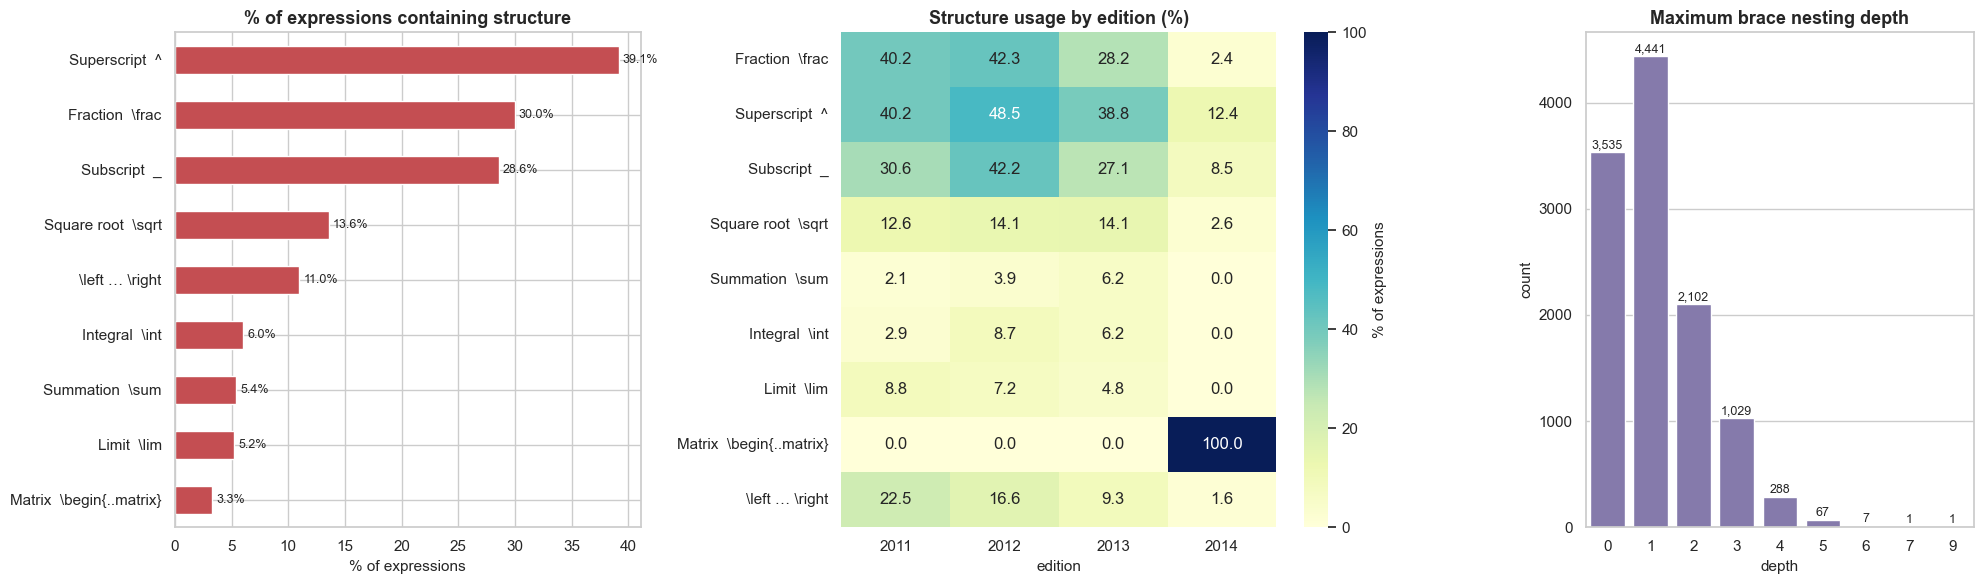

In [12]:
STRUCT_PATTERNS = {
    "Fraction  \\frac":      r"\\frac",
    "Superscript  ^":        r"\^",
    "Subscript  _":          r"_",
    "Square root  \\sqrt":   r"\\sqrt",
    "Summation  \\sum":      r"\\sum",
    "Integral  \\int":       r"\\int",
    "Limit  \\lim":          r"\\lim",
    "Matrix  \\begin{..matrix}": r"begin\s*\{\s*[pbvVB]?matrix\s*\}",
    "\\left … \\right":      r"\\left|\\right",
}
def max_brace_depth(s):
    s = re.sub(r"\\[{}]", "", s)
    d = m = 0
    for ch in s:
        if ch == "{": d += 1; m = max(m, d)
        elif ch == "}": d -= 1
    return m

struct = pd.DataFrame({k: crohme.label.str.contains(rx, regex=True) for k, rx in STRUCT_PATTERNS.items()})
crohme["brace_depth"] = crohme.label.map(max_brace_depth)
two_d_cols = [c for c in struct.columns if "Matrix" not in c and "left" not in c]
crohme["is_2d"] = struct[two_d_cols].any(axis=1)

by_year = struct.groupby(crohme.year).mean().T * 100
overall = struct.mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1.2, 1.4, 1]})
overall.sort_values().plot(kind="barh", ax=axes[0], color=PALETTE[3]); axes[0].set_title("% of expressions containing structure")
axes[0].set_xlabel("% of expressions"); label_bars(axes[0], fmt="{:.1f}%")
sns.heatmap(by_year, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "% of expressions"}, ax=axes[1])
axes[1].set_title("Structure usage by edition (%)"); axes[1].set_xlabel("edition")
sns.countplot(x=crohme.brace_depth, color=PALETTE[4], ax=axes[2]); axes[2].set_title("Maximum brace nesting depth"); axes[2].set_xlabel("depth")
label_bars(axes[2], horizontal=False)
plt.tight_layout(); plt.show()

#### 📌 Observation
- **71.3%** of expressions contain at least one 2-D construct. Most frequent: superscript **39.1%**, fraction 30.0%, subscript 28.6%, square root 13.6%, `\left...\right` 11.0%, integral 6.0%, summation 5.4%, limit 5.2%, matrix 3.3%.
- The heatmap shows strong edition differences: fractions appear in 40.2% / 42.3% / 28.2% of 2011 / 2012 / 2013 expressions but only **2.4% in 2014**, superscripts 40.2 / 48.5 / 38.8 versus 12.4, and the matrix row is **0% for 2011-2013 and 100% for 2014**. `\left...\right` falls from 22.5% (2011) to 9.3% (2013).
- Maximum brace depth: 0 for 3,535 expressions (30.8%), 1 for 4,441 (38.7%), 2 for 2,102 (18.3%), 3 for 1,029 (9.0%), 4 for 288, 5 for 67 and a handful at 6, 7 and 9. P95 is 3, and **12.1%** nest three or more levels.

#### 💡 Pipeline / Engineering Decision
- The recogniser is an **attention encoder-decoder emitting LaTeX tokens**; a flat character-CTC model cannot express 71% 2-D content.
- Constrained decoding adds a bracket-balance guard and pairs `\left` with `\right` (22.5% of 2011 expressions use them).
- `is_2d` and `brace_depth >= 3` (12.1%) are stored per sample for stratified metrics and for oversampling hard cases. The 2014 data is structurally narrow (almost only matrices), so it is mixed with the other editions rather than used alone.

---
## Step 11 — Pen-Coordinate Geometry — Scale & Offset Across Sources

### ❓ Why
Box-plots (log-scaled) of **bounding-box width and height per folder** and an **aspect-ratio histogram** reveal whether different editions / capture devices use different coordinate scales. 
A log axis is necessary because raw INKML coordinates can differ by orders of magnitude between devices.

### 💼 Business Insight
Real users write on phones, tablets and laptops with very different screen resolutions. If the model only ever saw one coordinate scale it breaks the moment a different device sends strokes — a hidden production-failure mode that is trivial to prevent once detected.

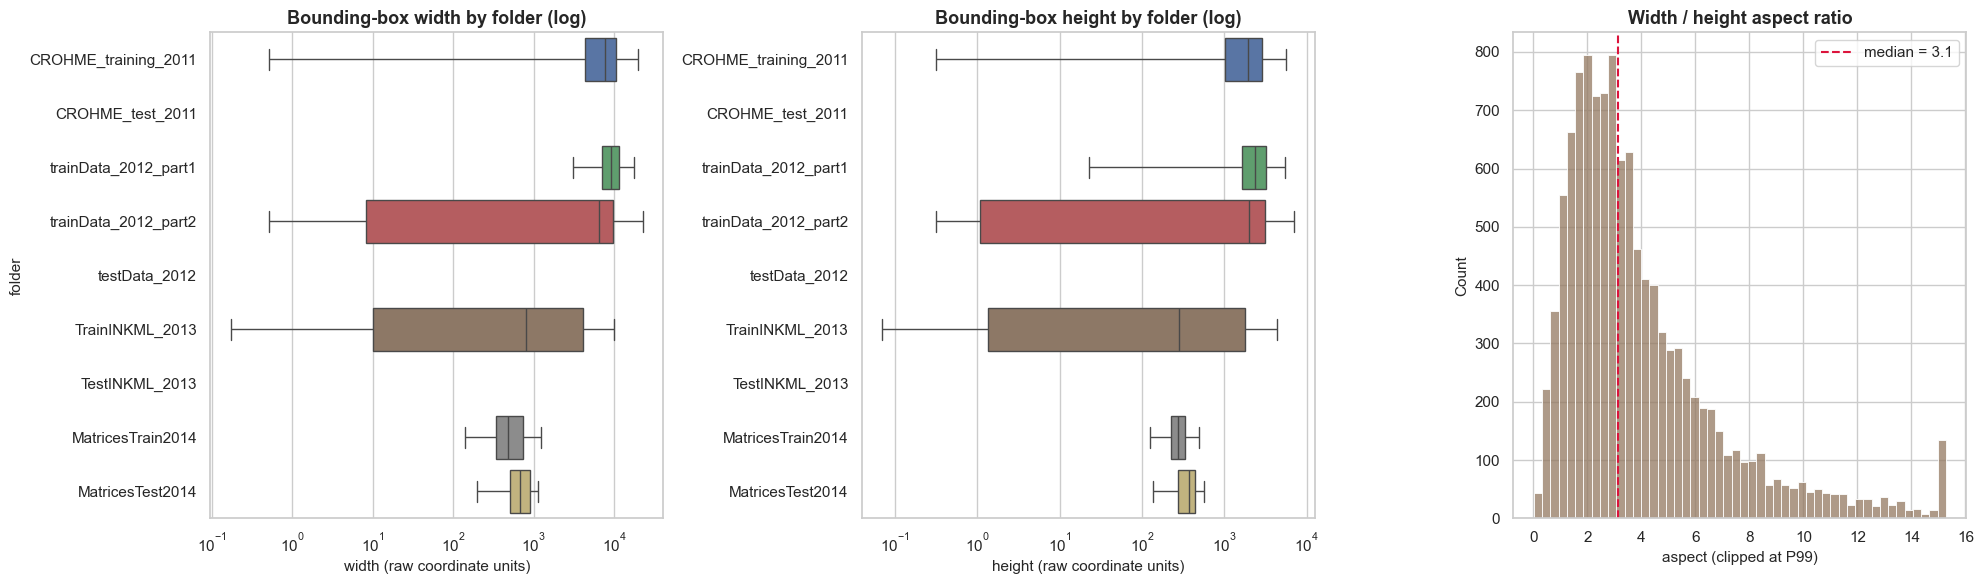

In [13]:
geo = crohme[(crohme.width > 0) & (crohme.height > 0)].copy()
geo["scale"] = np.sqrt(geo.width * geo.height)
crohme["aspect"] = (crohme.width / np.maximum(crohme.height, 0.02 * np.maximum(crohme.width, 1e-9))).where(crohme.width > 0, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.boxplot(data=geo, y="folder", x="width", order=folder_order, showfliers=False, ax=axes[0], palette="deep")
axes[0].set_xscale("log"); axes[0].set_title("Bounding-box width by folder (log)"); axes[0].set_xlabel("width (raw coordinate units)")
sns.boxplot(data=geo, y="folder", x="height", order=folder_order, showfliers=False, ax=axes[1], palette="deep")
axes[1].set_xscale("log"); axes[1].set_title("Bounding-box height by folder (log)"); axes[1].set_xlabel("height (raw coordinate units)"); axes[1].set_ylabel("")
sns.histplot(crohme.aspect.clip(upper=crohme.aspect.quantile(.99)), bins=50, color=PALETTE[5], ax=axes[2])
axes[2].axvline(crohme.aspect.median(), color="crimson", ls="--", label=f"median = {crohme.aspect.median():.1f}")
axes[2].set_title("Width / height aspect ratio"); axes[2].set_xlabel("aspect (clipped at P99)"); axes[2].legend()
plt.tight_layout(); plt.show()

scale_by_folder = geo.groupby("folder").scale.median().reindex(folder_order).dropna()
offset_by_folder = crohme.groupby("folder").x_min.median().reindex(folder_order).dropna()

#### 📌 Observation
- Median expression size (√(w·h)) differs by **12.7×** between folders, from 364.8 (`MatricesTrain2014`) to 4,619 (`trainData_2012_part1`); median `x_min` ranges from 130 to 5,407, so the coordinate origin is not fixed either.
- The width and height box-plots (log axis) show that `TrainINKML_2013` and `trainData_2012_part2` span **four to five orders of magnitude inside one folder** (from about 0.2 up to 10^4), unlike the compact boxes of 2011 and `trainData_2012_part1`. These folders therefore mix several capture devices.
- Median aspect ratio is **3.1** (P95 10.3, extreme 25.2); no expression has zero height in this copy (0.00%).

#### 💡 Pipeline / Engineering Decision
- Normalisation is **per sample, never per folder**: translate to the origin and divide by the longest side, aspect ratio preserved (shown in Step 15).
- Raw absolute coordinates are never model features; only normalised x, y and optional pen offsets are used.
- The aspect-ratio floor (`height >= 2% of width`) stays in the rasteriser as a safeguard for single horizontal strokes, even though none occurs in this copy.

---
## Step 12 — Pen Sampling Quality — Point Density, Dots & Time Channel

### ❓ Why
**Box-plots of points-per-stroke per folder** show how densely each device samples the pen, a **bar of single-point strokes** quantifies dots (the `i` dot, decimal point, `\cdot`), and a **bar of time-channel availability** tells us whether velocity/timing features are usable at all.

### 💼 Business Insight
Low-sample-rate devices produce jagged strokes that look different from smooth tablet ink. Quantifying this early tells us whether we need **resampling and smoothing** to make one model work across low-end phones and professional styluses.

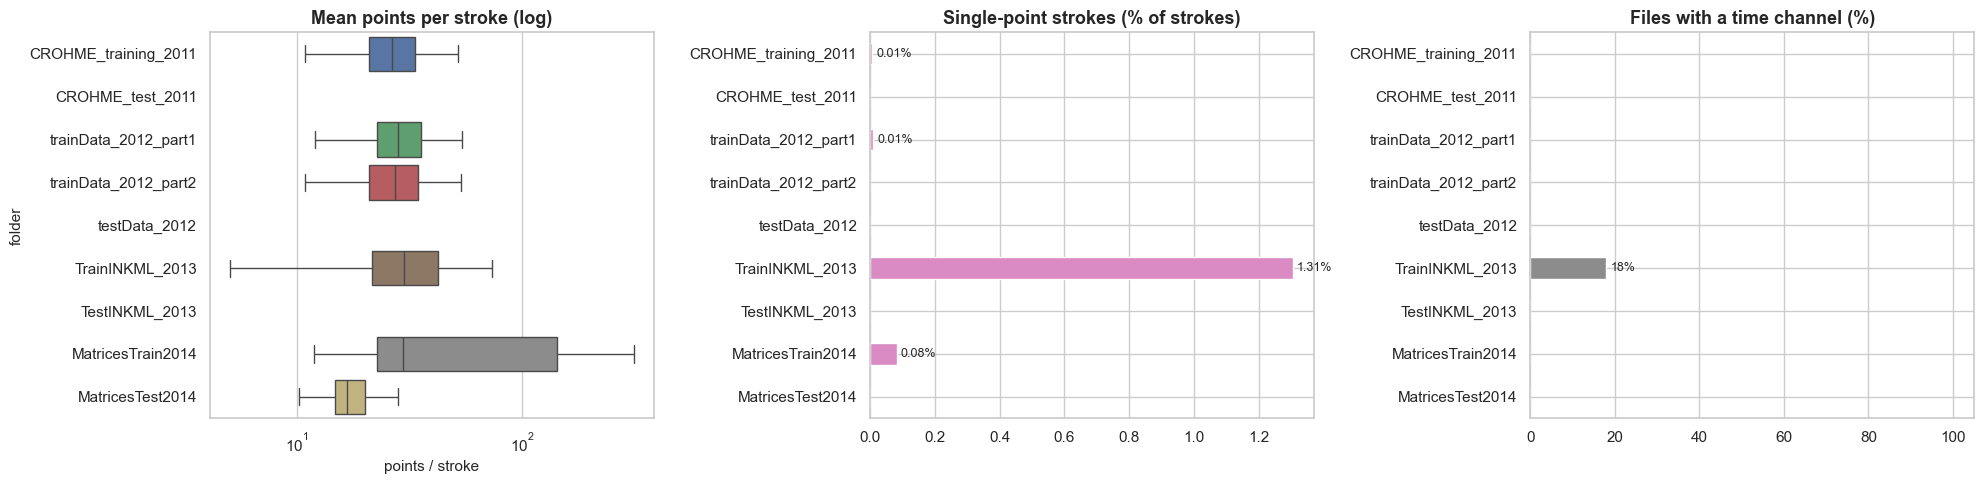

,strokes,dot_pct,time_pct,median_dt,pts_per_stroke
folder,,,,,
CROHME_training_2011,16891.0,0.006,0.0,NaN,26.455
CROHME_test_2011,NaN,NaN,NaN,NaN,NaN
trainData_2012_part1,12526.0,0.008,0.0,NaN,28.170
trainData_2012_part2,12236.0,0.000,0.0,NaN,27.189
testData_2012,NaN,NaN,NaN,NaN,NaN
TrainINKML_2013,121306.0,1.306,17.919402,16.0,29.933
TestINKML_2013,NaN,NaN,NaN,NaN,NaN
MatricesTrain2014,4927.0,0.081,0.0,NaN,29.537
MatricesTest2014,2394.0,0.000,0.0,NaN,16.729


In [14]:
agg = crohme.groupby("folder").agg(strokes=("n_traces", "sum"), dots=("single_pt_strokes", "sum"),
                                   time_share=("has_time", "mean"), median_dt=("median_dt", "median"),
                                   pts_per_stroke=("mean_pts_per_stroke", "median")).reindex(folder_order)
agg["dot_pct"] = agg.dots / agg.strokes * 100
agg["time_pct"] = agg.time_share * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=crohme, y="folder", x="mean_pts_per_stroke", order=folder_order, showfliers=False, ax=axes[0], palette="deep")
axes[0].set_xscale("log"); axes[0].set_title("Mean points per stroke (log)"); axes[0].set_xlabel("points / stroke")
agg.dot_pct.iloc[::-1].plot(kind="barh", ax=axes[1], color=PALETTE[6]); axes[1].set_title("Single-point strokes (% of strokes)"); axes[1].set_ylabel(""); label_bars(axes[1], fmt="{:.2f}%")
agg.time_pct.iloc[::-1].plot(kind="barh", ax=axes[2], color=PALETTE[7]); axes[2].set_title("Files with a time channel (%)"); axes[2].set_ylabel(""); axes[2].set_xlim(0, 105); label_bars(axes[2], fmt="{:.0f}%")
plt.tight_layout(); plt.show()
display(agg[["strokes", "dot_pct", "time_pct", "median_dt", "pts_per_stroke"]].round(3))

#### 📌 Observation
- Median points per stroke are 26.5 (2011), 28.2 and 27.2 (2012), **29.9 (2013)**, 29.5 (`MatricesTrain2014`) and **16.7 (`MatricesTest2014`)**. `MatricesTrain2014` has a very wide spread (box up to about 140 points per stroke, whiskers above 300) while `MatricesTest2014` is tight at roughly 15-20, i.e. **matrix train and test were captured at different sampling densities**.
- Single-point strokes (dots) are 0.93% of all strokes overall but **1.31% in `TrainINKML_2013`**, versus 0.00-0.08% in all other folders.
- A **time channel exists only in `TrainINKML_2013`** (17.9% of that folder's files, 13.8% of all usable expressions), with a median step of 16 time units. All other folders are position-only.

#### 💡 Pipeline / Engineering Decision
- Strokes are resampled by arc length to a fixed point spacing so 16-point and 140-point strokes look alike to the model; this also removes the matrix train/test density mismatch.
- Dots are kept: they are real symbols (decimal points, `i`/`j` dots, `\cdot`), and 1.31% of 2013 strokes would otherwise be deleted.
- Timing is not used as a model feature, because 86% of the data has none; the model relies on geometry and stroke order only.

---
## Step 13 — Writers & Metadata Availability — Leakage-Safe Splitting

### ❓ Why
A **metadata-availability bar chart** shows which annotation fields we can actually rely on; if a writer field exists, a **writer-contribution histogram** shows how many expressions each person wrote. 
This is the evidence needed to choose between a random split and a **writer-independent split**.

### 💼 Business Insight
If the same person appears in train *and* validation, the model memorises handwriting style and reports inflated accuracy that collapses on new users. Writer-independent evaluation is the honest estimate of how the app will behave for a **brand-new student**.

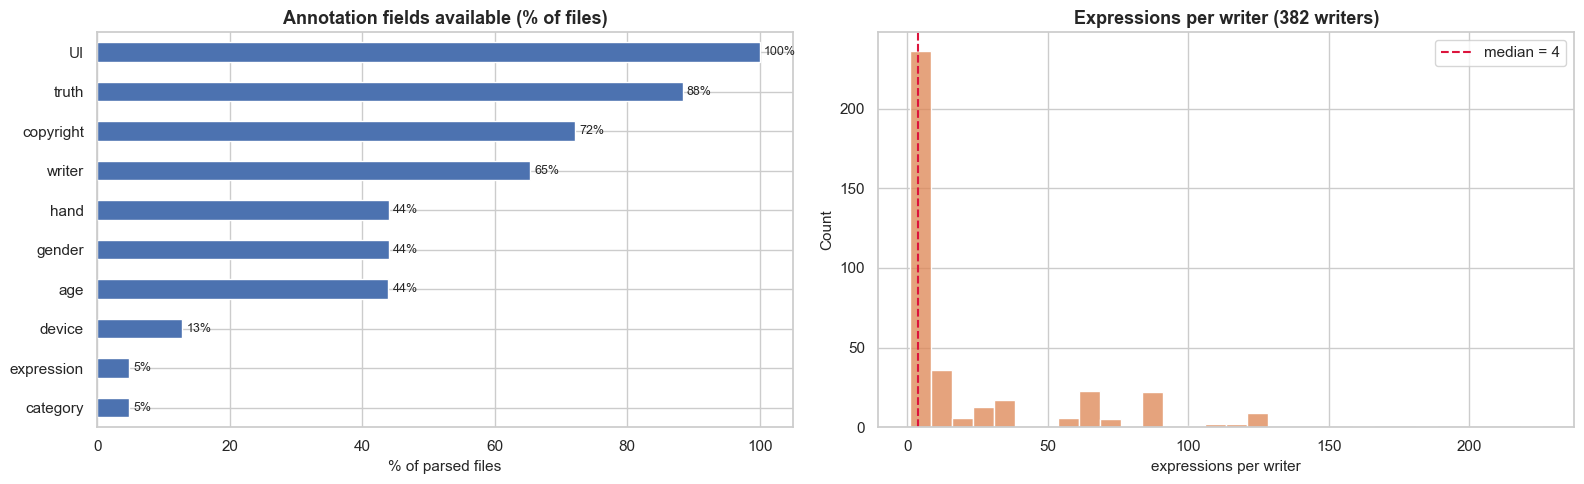

In [15]:
meta_keys = Counter(k for ks in ink_df.ann_keys.dropna() for k in ks)
meta_pct = (pd.Series(meta_keys) / ink_df.parse_ok.astype(bool).sum() * 100).sort_values().tail(15)
has_writer = crohme.writer.notna() & (crohme.writer.fillna("").astype(str).str.len() > 0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
meta_pct.plot(kind="barh", ax=axes[0], color=PALETTE[0]); axes[0].set_title("Annotation fields available (% of files)")
axes[0].set_xlabel("% of parsed files"); axes[0].set_xlim(0, 105); label_bars(axes[0], fmt="{:.0f}%")

if has_writer.any():
    per_writer = crohme[has_writer].groupby("writer").size()
    sns.histplot(per_writer, bins=30, color=PALETTE[1], ax=axes[1])
    axes[1].set_title(f"Expressions per writer ({per_writer.size:,} writers)"); axes[1].set_xlabel("expressions per writer")
    axes[1].axvline(per_writer.median(), color="crimson", ls="--", label=f"median = {per_writer.median():.0f}"); axes[1].legend()
else:
    per_writer = pd.Series(dtype=int)
    axes[1].axis("off"); axes[1].text(0.5, 0.5, "No writer identifier found\nin the annotations", ha="center", va="center", fontsize=14)
plt.tight_layout(); plt.show()

#### 📌 Observation
- Annotation availability: `UI` 100%, `truth` 88%, `copyright` 72%, `writer` 65%, `hand` / `gender` / `age` 44%, `device` 13%, `expression` and `category` only 5%.
- A writer id exists for **73.9%** of usable expressions, giving **382 unique writers**. The writer histogram is heavily skewed: the median is **4 expressions per writer**, roughly 240 writers have fewer than 10 expressions, a second cluster of writers has 60-130 expressions, and the top writer has 226 (2.7% of identified data).
- About **26% of usable expressions (roughly 3,000) have no writer id**, so writer grouping alone cannot cover the whole dataset.

#### 💡 Pipeline / Engineering Decision
- The split is grouped by writer (`GroupShuffleSplit`) where an id exists. Expressions without a writer id are grouped by `UI` / file-name prefix and by content hash, so one hidden writer cannot leak across splits.
- The ~240 low-volume writers make a writer-independent split easy; the few high-volume writers (60-226 expressions) are kept whole inside one split.
- Age, gender, handedness and device are used only for sub-group error analysis, never as inputs, and the data card records their partial coverage (44% / 13%).

---
## Step 14 — Visual Inspection — Rendering the Raw Pen Strokes

### ❓ Why
Statistics can hide obvious defects, so we **draw real expressions** straight from the stroke data, colouring each stroke by writing order (dark → light). 
One gallery is sampled per edition (to catch edition-specific quirks) and one shows **extreme cases** (most strokes, longest label, widest, fewest strokes) — the samples most likely to break a model.

### 💼 Business Insight
Looking at the data is the fastest sanity check that labels and ink actually match. It also builds intuition for stakeholders: *this* is what a student's messy handwriting looks like, and *this* is what the model must read.

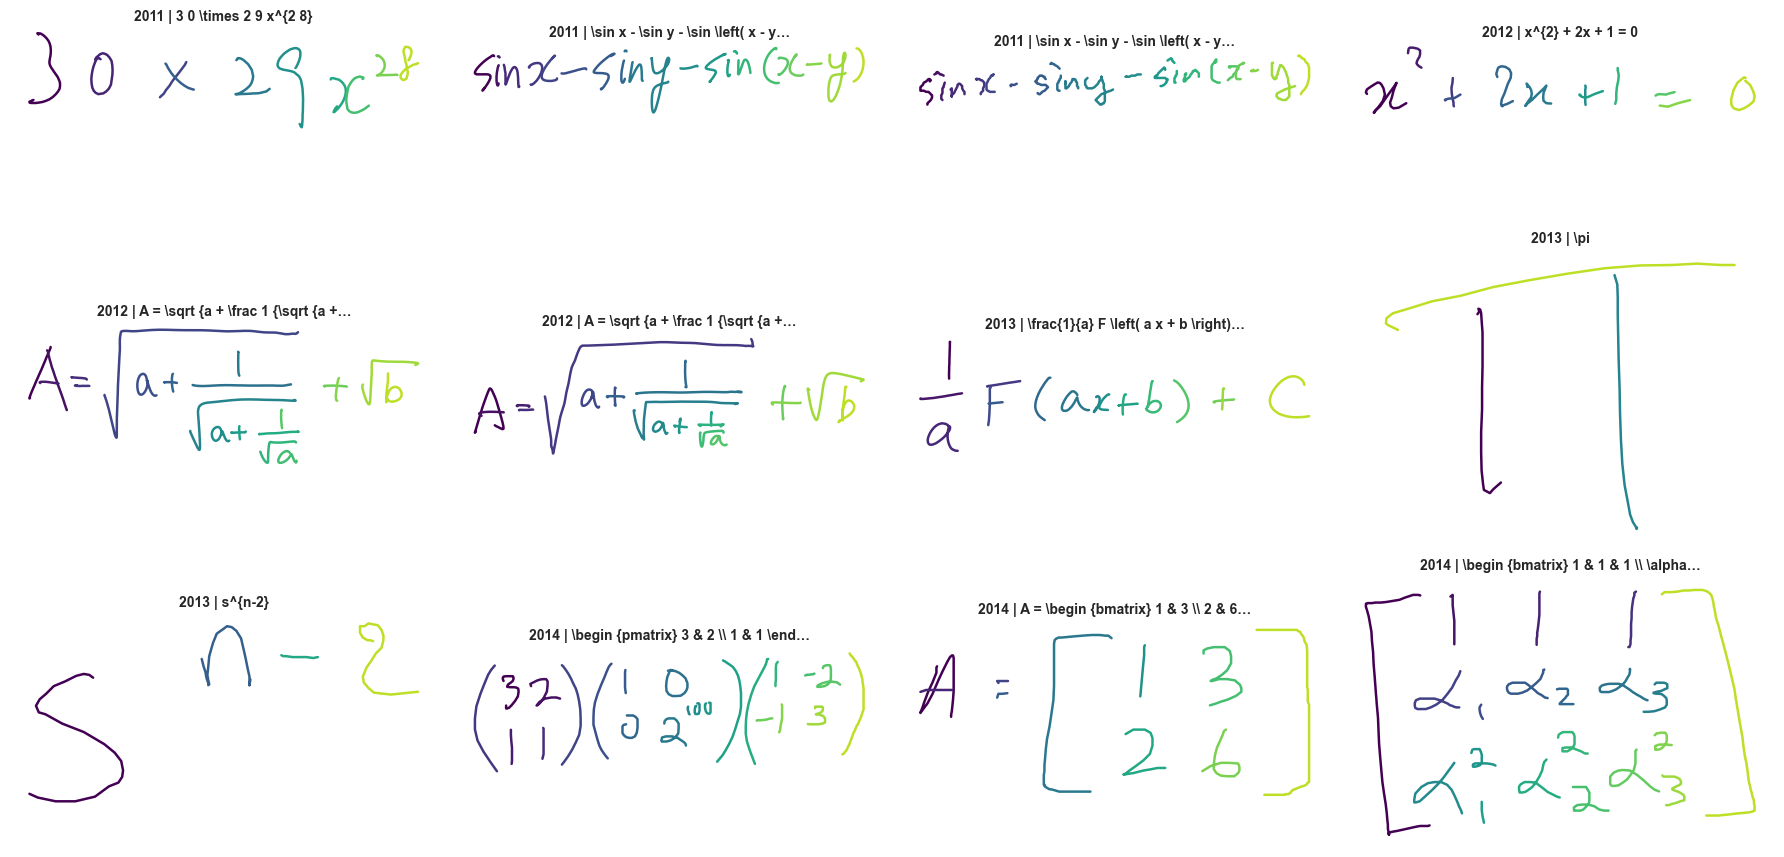

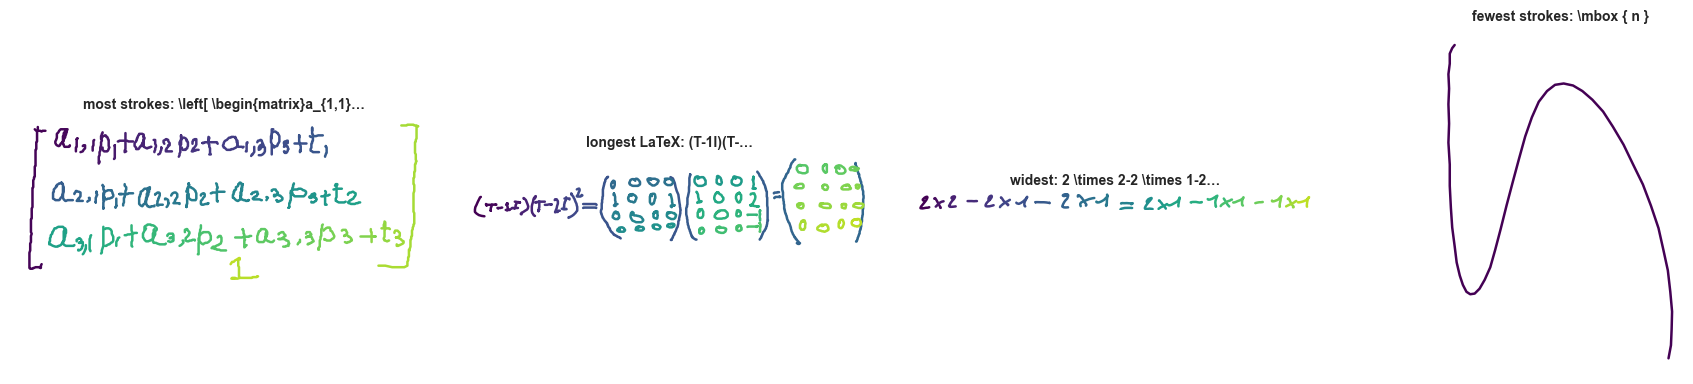

In [16]:
def draw_ink(ax, traces, lw=1.8):
    n = len(traces)
    colors = plt.cm.viridis(np.linspace(0, 0.9, max(n, 1)))
    for i, t in enumerate(traces):
        if len(t) == 1: ax.plot(t[0, 0], t[0, 1], "o", color=colors[i], ms=3)
        else:           ax.plot(t[:, 0], t[:, 1], "-", color=colors[i], lw=lw, solid_capstyle="round")
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")

def gallery(df_rows, ncols=4, titles=None, figsize=(18, 8)):
    nrows = int(np.ceil(len(df_rows) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, r), ttl in zip(axes, df_rows.iterrows(), titles or [None] * len(df_rows)):
        tr = load_traces(r.path)
        if tr: draw_ink(ax, tr)
        ax.set_title(ttl or f"{r.year} | {safe_title(r.label, 38)}", fontsize=10)
    for ax in axes[len(df_rows):]: ax.axis("off")
    plt.tight_layout(); plt.show()

# (a) stratified random gallery — 3 expressions per edition
sample_rows = pd.concat([g.sample(min(3, len(g)), random_state=SEED) for _, g in crohme.groupby("year")], ignore_index=True)
gallery(sample_rows, ncols=4, figsize=(18, 3.2 * int(np.ceil(len(sample_rows) / 4))))

# (b) extreme cases
extremes = pd.concat([
    crohme.nlargest(1, "n_traces").assign(tag="most strokes"),
    crohme.nlargest(1, "n_tokens").assign(tag="longest LaTeX"),
    crohme[crohme.width > 0].nlargest(1, "aspect").assign(tag="widest"),
    crohme.nsmallest(1, "n_traces").assign(tag="fewest strokes"),
], ignore_index=True)
gallery(extremes, ncols=4, titles=[f"{r.tag}: {safe_title(r.label, 30)}" for _, r in extremes.iterrows()], figsize=(18, 4))

#### 📌 Observation
- The stratified gallery shows **the same formula written by different writers**: the 2011 `\sin x - \sin y - \sin\left(x-y\right)` appears twice and the 2012 nested `A = \sqrt{a + \frac{1}{\sqrt{a + ...}}} + \sqrt{b}` appears twice with visibly different handwriting.
- **Label style differs between editions**: 2011 labels are space-separated (`3 0 \times 2 9 x^{2 8}`) while 2013 / 2014 labels are compact (`s^{n-2}`, `\frac{1}{a}F\left(ax+b\right)+C`). Scale inside one expression is also inconsistent: in `s^{n-2}` the `S` is far larger than `n-2`, and the 2013 `\pi` sample is a single isolated symbol drawn very large.
- The extreme cases are all matrix-like: the **103-stroke** 3×3 matrix with entries such as `a_{1,1}p_1 + ...`, the **171-token** matrix product `(T-1I)(T-...)`, the **widest (aspect 25.2)** one-line chain `2 \times 2 - 2 \times 1 - ...`, and the **1-stroke** sample labelled `\mbox{n}`, a single letter drawn in one stroke. Colour order shows that brackets and fraction bars are often drawn first or last.

#### 💡 Pipeline / Engineering Decision
- Stroke order is not trusted as spatial order: the encoder consumes the full stroke set with 2-D positional information.
- Labels are normalised to one style (strip spaces, canonical commands) before tokenisation, so 2011-style and 2013-style labels produce identical tokens.
- Single-symbol samples (e.g. `\pi`, `\mbox{n}`) are flagged `kind=symbol`. Per-symbol scale jitter is added to augmentation, and the extreme-case gallery becomes a fixed visual regression test.

---
## Step 15 — Normalisation & Rasterisation Preview — From Strokes to Model Input

### ❓ Why
A **before / after panel** (raw coordinates → normalised strokes → rasterised bitmap) proves the preprocessing is correct, and a **histogram of the estimated rasterised width** at fixed height tells us what image size the model needs. 
We visualise the transform before committing to it, because a wrong scale or flipped axis is invisible in the loss curve.

### 💼 Business Insight
Rasterising strokes lets us feed CROHME into the **same image model** as IM2LaTeX and the symbol images — one shared recogniser instead of three separate systems. That single decision cuts engineering and maintenance cost and lets the three datasets reinforce each other.

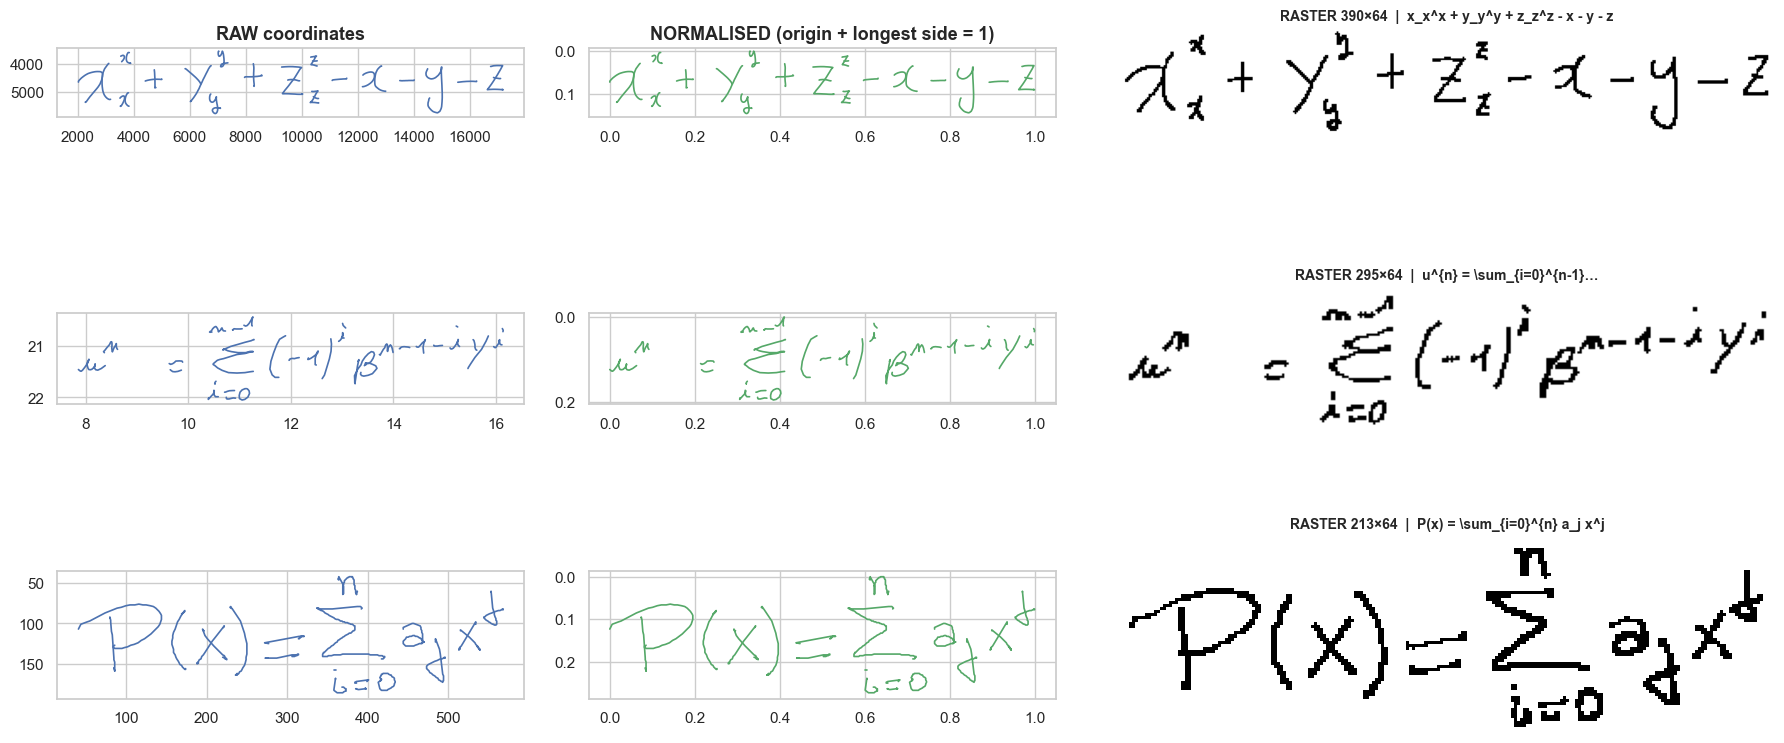

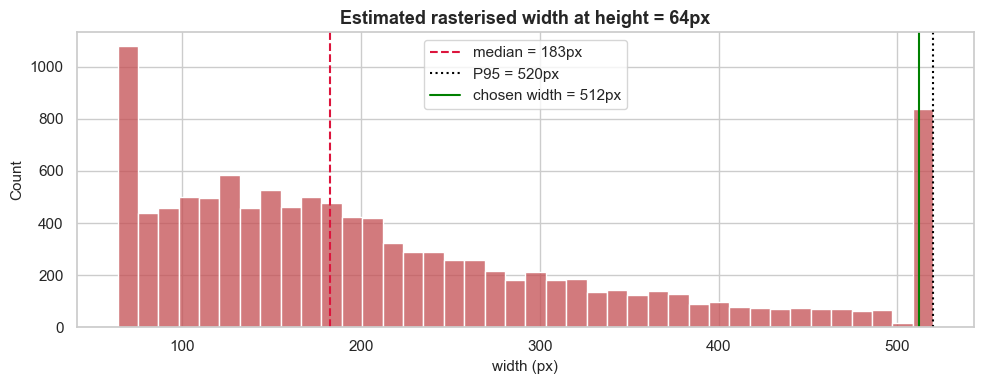

In [17]:
def normalize_traces(traces):
    allp = np.vstack(traces); mn = allp.min(0); scale = max(float(np.ptp(allp, axis=0).max()), 1e-9)
    return [(t - mn) / scale for t in traces]

def rasterize(traces, height=64, max_width=512, pad=4, line_width=2):
    nt = normalize_traces(traces); allp = np.vstack(nt)
    w_u, h_u = float(allp[:, 0].max()), float(allp[:, 1].max())
    s = min((height - 2 * pad) / max(h_u, 1e-6), (max_width - 2 * pad) / max(w_u, 1e-6))
    W = int(math.ceil(w_u * s + 2 * pad)); W = max(W, height)
    img = Image.new("L", (W, height), 255); dr = ImageDraw.Draw(img)
    y_off = (height - h_u * s) / 2
    for t in nt:
        pts = [(pad + x * s, y_off + y * s) for x, y in t]
        if len(pts) == 1: dr.ellipse([pts[0][0] - line_width, pts[0][1] - line_width, pts[0][0] + line_width, pts[0][1] + line_width], fill=0)
        else: dr.line(pts, fill=0, width=line_width, joint="curve")
    return np.asarray(img)

demo = crohme.sample(3, random_state=7)
fig, axes = plt.subplots(3, 3, figsize=(18, 9), gridspec_kw={"width_ratios": [1, 1, 1.4]})
for i, (_, r) in enumerate(demo.iterrows()):
    tr = load_traces(r.path)
    for t in tr: axes[i, 0].plot(t[:, 0], t[:, 1], "-", lw=1.2, color=PALETTE[0])
    axes[i, 0].invert_yaxis(); axes[i, 0].set_aspect("equal"); axes[i, 0].set_title("RAW coordinates" if i == 0 else "")
    for t in normalize_traces(tr): axes[i, 1].plot(t[:, 0], t[:, 1], "-", lw=1.2, color=PALETTE[2])
    axes[i, 1].invert_yaxis(); axes[i, 1].set_aspect("equal"); axes[i, 1].set_title("NORMALISED (origin + longest side = 1)" if i == 0 else "")
    ras = rasterize(tr); axes[i, 2].imshow(ras, cmap="gray", aspect="equal"); axes[i, 2].axis("off")
    axes[i, 2].set_title(f"RASTER {ras.shape[1]}×{ras.shape[0]}  |  {safe_title(r.label, 40)}", fontsize=10)
plt.tight_layout(); plt.show()

CROHME_IMG_H, PAD_PX, MAX_W = 64, 4, 512
crohme["raster_w_est"] = np.ceil(np.minimum(MAX_W, crohme.aspect * (CROHME_IMG_H - 2 * PAD_PX)) + 2 * PAD_PX).clip(lower=CROHME_IMG_H)
w95 = crohme.raster_w_est.quantile(.95)
CROHME_IMG_W = int(min(MAX_W, math.ceil(w95 / 32) * 32))

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(crohme.raster_w_est, bins=40, color=PALETTE[3], ax=ax)
for v, c, ls, lab in [(crohme.raster_w_est.median(), "crimson", "--", "median"), (w95, "black", ":", "P95")]:
    ax.axvline(v, color=c, ls=ls, label=f"{lab} = {v:.0f}px")
ax.axvline(CROHME_IMG_W, color="green", ls="-", label=f"chosen width = {CROHME_IMG_W}px"); ax.legend()
ax.set_title(f"Estimated rasterised width at height = {CROHME_IMG_H}px"); ax.set_xlabel("width (px)")
plt.tight_layout(); plt.show()

#### 📌 Observation
- The panel confirms the transform is correct but shows how different raw scales are: example 1 spans x ≈ 2,000-16,000 and y ≈ 4,500-5,500, example 2 spans x ≈ 8-16 and y ≈ 21-22, example 3 spans x ≈ 50-550. After normalisation all three live in [0, 1] and the 64-px rasters (390×64, 295×64, 213×64) keep sum limits (`i=0`, `n`), subscripts and the superscript on `x`.
- At 64 px height the 2-px lines are legible but crowded for small scripts (for example the `n-1` exponent in example 2 is jagged).
- Estimated raster width: median **183 px**, P95 **520 px**. The histogram has two spikes: about **9% of samples (~1,080) sit at the 64-px minimum width** (isolated symbols and very short expressions), and **7.18% (~820) hit the 512-px cap**.

#### 💡 Pipeline / Engineering Decision
- CROHME is rasterised to **height 64 and width up to 512**, aspect ratio preserved, white padded; sizes are grouped into width buckets so batches stay compact.
- The 7.18% of very wide expressions are scaled down uniformly (aspect preserved, never cropped). A W = 768 variant is trained as an ablation and judged on the wide-expression bucket.
- Stroke width is randomised between 1 and 3 px during on-the-fly rasterisation, and the same `normalize_traces` + `rasterize` code is shared by training and the serving API.

---
## Step 16 — Label Quality Audit — Validity, Duplicates & Synonym Inconsistency

### ❓ Why
A **heatmap of label-defect rates per folder**, a **bar chart of the most repeated expressions** and a **grouped bar of synonym pairs** (`\le` vs `\leq`, `\ldots` vs `\dots`, …) audit the ground truth itself. 
A model can only be as good as its labels; synonym splits are especially nasty because they make the *same* symbol look like two different classes.

### 💼 Business Insight
Label noise puts a hard ceiling on achievable accuracy and creates impossible-to-explain errors for users ("it printed `\leq` but my teacher's key uses `\le`"). Cleaning labels is the **highest-ROI step in the whole project**.

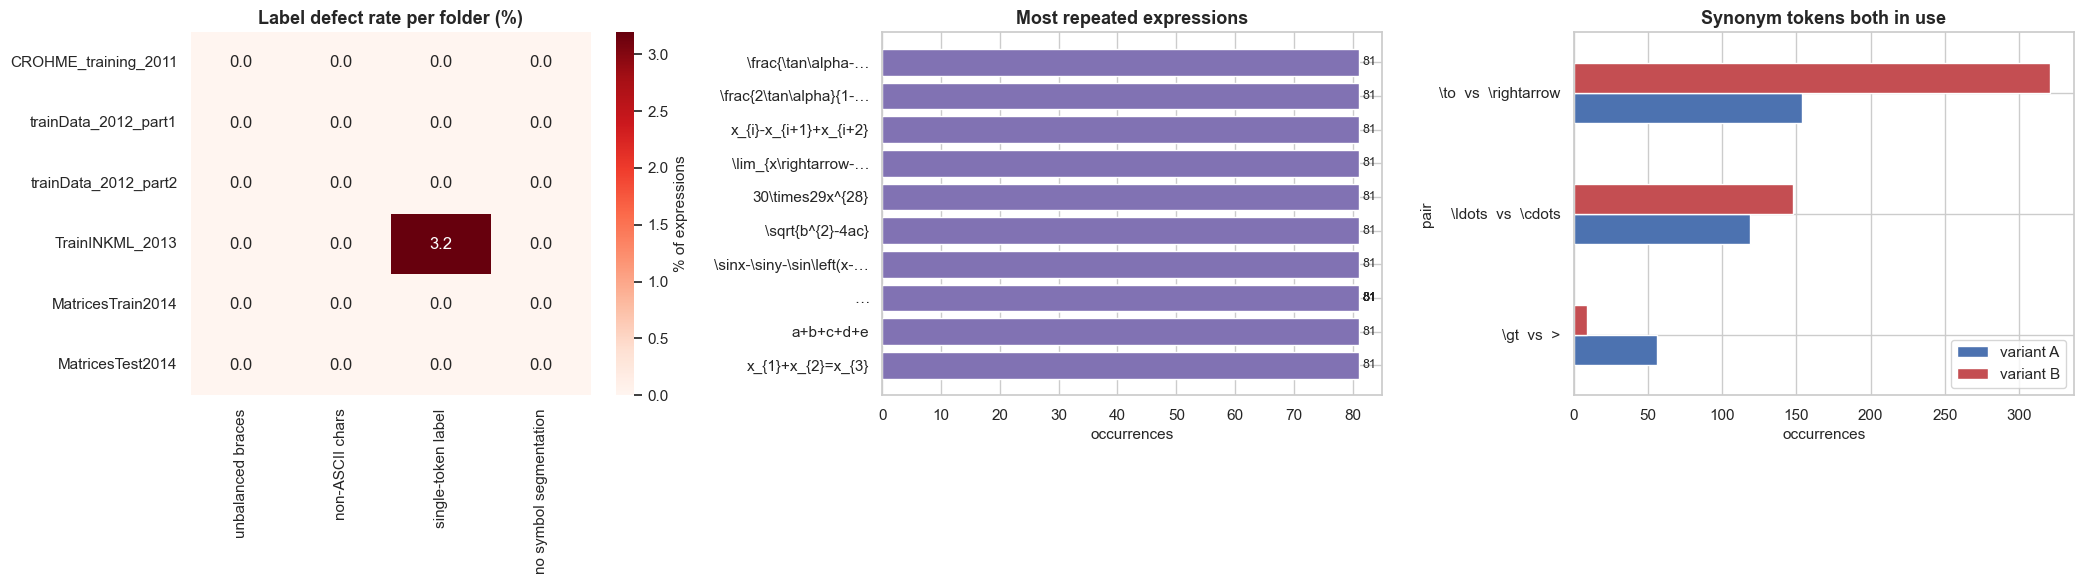

,pair,a,b,both_in_use
0,\le vs \leq,0,243,False
1,\ge vs \geq,0,173,False
2,\ne vs \neq,0,140,False
3,\to vs \rightarrow,154,321,True
4,\ldots vs \dots,119,0,False
5,\ldots vs \cdots,119,148,True
6,\lbrace vs \{,0,130,False
7,\gt vs >,56,9,True
8,\lt vs <,123,0,False


In [18]:
def braces_balanced(s):
    s = re.sub(r"\\[{}]", "", s); d = 0
    for ch in s:
        if ch == "{": d += 1
        elif ch == "}": d -= 1
        if d < 0: return False
    return d == 0

issues = pd.DataFrame({
    "unbalanced braces":  ~crohme.label.map(braces_balanced),
    "non-ASCII chars":    crohme.label.map(lambda s: any(ord(c) > 127 for c in s)),
    "single-token label": crohme.n_tokens <= 1,
    "no symbol segmentation": crohme.n_symbol_groups == 0,
})
issue_rate = issues.groupby(crohme.folder).mean().reindex(folder_order).dropna(how="all") * 100

dup = crohme.label.str.replace(" ", "", regex=False).value_counts()
n_distinct = dup.size

SYN_PAIRS = [(r"\le", r"\leq"), (r"\ge", r"\geq"), (r"\ne", r"\neq"), (r"\to", r"\rightarrow"),
             (r"\ldots", r"\dots"), (r"\ldots", r"\cdots"), (r"\lbrace", r"\{"), (r"\gt", ">"), (r"\lt", "<")]
syn = pd.DataFrame([dict(pair=f"{a}  vs  {b}", a=tok_counter.get(a, 0), b=tok_counter.get(b, 0)) for a, b in SYN_PAIRS])
syn_active = syn[(syn.a > 0) & (syn.b > 0)]

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
sns.heatmap(issue_rate, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% of expressions"}, ax=axes[0])
axes[0].set_title("Label defect rate per folder (%)"); axes[0].set_ylabel("")
dd = dup.head(15).iloc[::-1]
axes[1].barh([safe_title(i, 28) for i in dd.index], dd.values, color=PALETTE[4]); axes[1].set_title("Most repeated expressions"); axes[1].set_xlabel("occurrences"); label_bars(axes[1])
if len(syn_active):
    syn_active.set_index("pair")[["a", "b"]].rename(columns={"a": "variant A", "b": "variant B"}).iloc[::-1].plot(kind="barh", ax=axes[2], color=[PALETTE[0], PALETTE[3]])
    axes[2].set_title("Synonym tokens both in use"); axes[2].set_xlabel("occurrences")
else:
    axes[2].axis("off"); axes[2].text(0.5, 0.5, "No synonym pair found\nwith both variants in use", ha="center", va="center", fontsize=13)
plt.tight_layout(); plt.show()
display(syn.assign(both_in_use=(syn.a > 0) & (syn.b > 0)))

#### 📌 Observation
- Labels are structurally clean: **0 unbalanced braces and 0 non-ASCII labels**. The only flagged defect is **282 single-token labels, all in `TrainINKML_2013`** (3.2% of that folder), and they are valid isolated symbols such as `\pi`, not errors.
- Only **5,306 distinct labels** exist among 11,471 expressions (46.3% unique) and **709 labels repeat**. The ten most repeated labels (`\frac{\tan\alpha-\tan\beta}{...}`, `x_{i}-x_{i+1}+x_{i+2}`, `\sqrt{b^{2}-4ac}`, ...) **each occur exactly 81 times**, most likely a fixed expression list written by 81 writers.
- Synonym audit: `\to` (154) vs `\rightarrow` (321), `\ldots` (119) vs `\cdots` (148), `\gt` (56) vs `>` (9) are used inconsistently; `\lt` (123) has no `<` counterpart. `\leq` (243), `\geq` (173), `\neq` (140) and `\{` (130) are used consistently.

#### 💡 Pipeline / Engineering Decision
- The label normaliser maps `\rightarrow → \to`, `\gt → >`, `\lt → <`, and `\ldots` / `\cdots` to one token (three dots are indistinguishable in ink). Function names (`\sin`, `\cos`, `\tan`, `\log`, `\lim`) are aligned with IM2LaTeX spelling in Step 35.
- Single-token labels are kept as symbol samples (`kind=symbol`), not dropped.
- Because ten labels occur 81 times each, splitting groups by normalised label (plus writer), and a **per-label cap** (about 10 samples per label per epoch) prevents the model from memorising those fixed expressions.

---
## Step 17 — Cross-Folder Duplicate & Train/Test Leakage Audit

### ❓ Why
Filenames such as `formulaire001-equation003.inkml` visibly recur across editions. We hash **every file's bytes (MD5)** and draw a **folder × folder overlap heatmap**, then measure filename, content and label overlap between the official train and test partitions. 
Byte-level hashing is the only reliable way to prove two files are the same sample, regardless of name.

### 💼 Business Insight
Train/test leakage is the most common reason a model that scores 95 % in the lab disappoints in production. Catching it now protects the credibility of every accuracy number we will later put in a client deck.

Hashing INKML:   0%|          | 0/12980 [00:00<?, ?it/s]

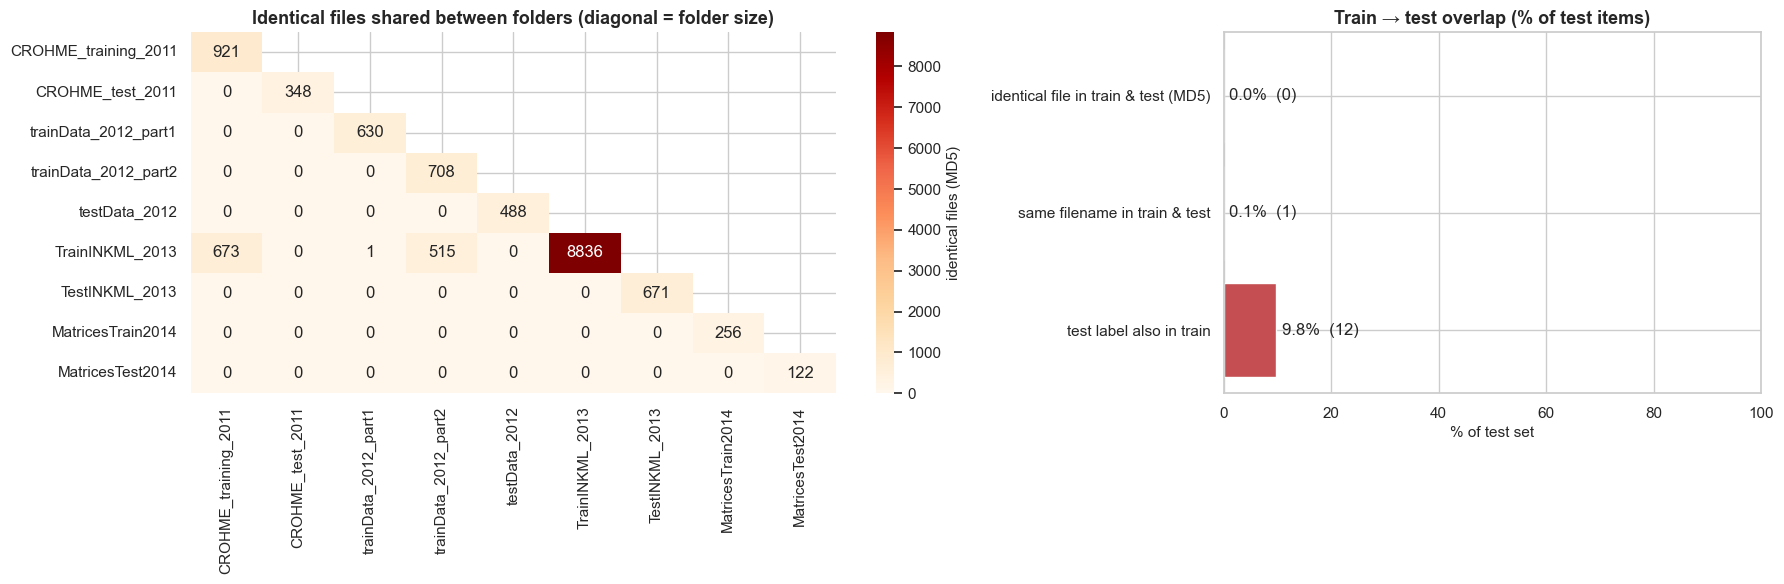

In [19]:
def md5_file(p):
    h = hashlib.md5()
    with open(p, "rb") as f: h.update(f.read())
    return h.hexdigest()

inkml_idx["md5"] = [md5_file(p) for p in tqdm(inkml_idx.path, desc="Hashing INKML")]
folders = [f for f in folder_order if f in set(inkml_idx.folder)]
md5_sets = {f: set(inkml_idx.loc[inkml_idx.folder == f, "md5"]) for f in folders}
overlap = pd.DataFrame([[len(md5_sets[a] & md5_sets[b]) for b in folders] for a in folders], index=folders, columns=folders)

dup_groups = inkml_idx.groupby("md5").filter(lambda d: len(d) > 1)
n_dup_files = len(dup_groups); n_dup_groups = dup_groups.md5.nunique()

train_md5 = set(inkml_idx.loc[inkml_idx.split == "train", "md5"]); test_md5 = set(inkml_idx.loc[inkml_idx.split == "test", "md5"])
leak_md5 = train_md5 & test_md5

low = lambda s: s.str.lower()
fn_train = set(low(inkml_idx.loc[inkml_idx.split == "train", "file"])); fn_test = set(low(inkml_idx.loc[inkml_idx.split == "test", "file"]))
leak_fn = fn_train & fn_test

norm_lab = crohme.label.str.replace(" ", "", regex=False)
lab_train = set(norm_lab[crohme.split == "train"]); te_mask = crohme.split == "test"
test_label_in_train = norm_lab[te_mask].isin(lab_train)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.5, 1]})
mask = np.triu(np.ones_like(overlap, dtype=bool), k=1)
sns.heatmap(overlap, annot=True, fmt="d", cmap="OrRd", mask=mask, cbar_kws={"label": "identical files (MD5)"}, ax=axes[0])
axes[0].set_title("Identical files shared between folders (diagonal = folder size)")
vals = pd.Series({"identical file in train & test (MD5)": len(leak_md5),
                  "same filename in train & test": len(leak_fn),
                  "test label also in train": int(test_label_in_train.sum())})
pcts = pd.Series({"identical file in train & test (MD5)": pct(len(leak_md5), max(len(test_md5), 1)),
                  "same filename in train & test": pct(len(leak_fn), max(len(fn_test), 1)),
                  "test label also in train": pct(test_label_in_train.sum(), max(te_mask.sum(), 1))})
axes[1].barh(pcts.index[::-1], pcts.values[::-1], color=[PALETTE[3], PALETTE[1], PALETTE[0]])
axes[1].set_title("Train → test overlap (% of test items)"); axes[1].set_xlabel("% of test set"); axes[1].set_xlim(0, max(100, pcts.max() * 1.1))
for i, (v, c) in enumerate(zip(pcts.values[::-1], vals.values[::-1])): axes[1].annotate(f"{v:.1f}%  ({c:,})", (v, i), xytext=(4, 0), textcoords="offset points", va="center")
plt.tight_layout(); plt.show()

#### 📌 Observation
- **2,378 files (18.3%) are byte-identical**, forming exactly **1,189 duplicate pairs**. The overlap matrix shows where: **673 files of `CROHME_training_2011` (73% of its 921) and 515 files of `trainData_2012_part2` (73% of its 708) are also inside `TrainINKML_2013`**, plus 1 file shared between `trainData_2012_part1` and `TrainINKML_2013`.
- The three unlabelled test folders and both matrix folders share **no** file with any other folder.
- Official train vs test: 0 identical files, 1 shared filename, and **12 of the 122 labelled test expressions (9.8%)** have a label that also appears in training. This test set is only the matrix folder, so the figure says little about the general case.

#### 💡 Pipeline / Engineering Decision
- Training data is de-duplicated by content hash (earliest edition kept first): **11,471 labelled expressions become about 10,282 unique ones**. The hash list goes into the data card.
- The 2013 folder is treated as the superset; 2011 and 2012-part2 add almost no new samples, so reporting them as separate 'datasets' would overstate data volume.
- The unlabelled test folders are leak-free and safe as a pure inference pool. Label overlap (same formula, different writer) is tracked as a metric (accuracy on seen vs unseen formulas).

---
## Step 18 — Matrix Subset (CROHME 2014) — Rows, Columns & Rarity

### ❓ Why
Matrices are a **structurally distinct sub-population**. A **row × column count heatmap** shows which matrix shapes exist and a **token-length overlay histogram** compares matrices against ordinary expressions. 
The heatmap (rather than a flat bar) is used because shape is two-dimensional.

### 💼 Business Insight
Linear-algebra content (matrices, determinants) is central for engineering entrance prep and university coursework — a high-value segment. If the matrix sample is tiny, advertising "matrix support" would be a promise the data cannot back.

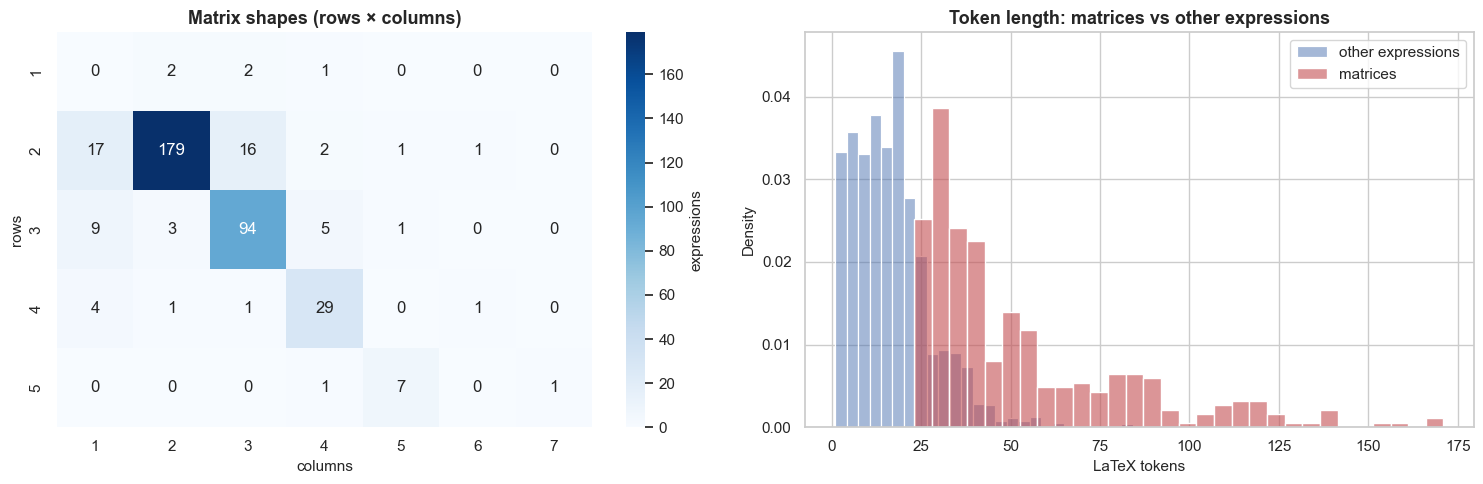

folder,MatricesTest2014,MatricesTrain2014
matrix expressions,122,256


In [20]:
MATRIX_RE = r"begin\s*\{\s*[pbvVB]?matrix\s*\}"
mat_mask = crohme.label.str.contains(MATRIX_RE, regex=True) | crohme.folder.str.startswith("Matrices")
mat = crohme[mat_mask].copy()

def matrix_shape(lab):
    inner = re.sub(r".*?begin\s*\{\s*[pbvVB]?matrix\s*\}", "", lab, count=1)
    inner = re.sub(r"\\end\s*\{\s*[pbvVB]?matrix\s*\}.*", "", inner)
    rows = [r for r in inner.split("\\\\") if r.strip()]
    return len(rows), (max(r.count("&") for r in rows) + 1) if rows else 0

if len(mat):
    mat[["m_rows", "m_cols"]] = mat.label.apply(lambda s: pd.Series(matrix_shape(s)))
    shape_ct = pd.crosstab(mat.m_rows, mat.m_cols)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.heatmap(shape_ct, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "expressions"}, ax=axes[0])
    axes[0].set_title("Matrix shapes (rows × columns)"); axes[0].set_xlabel("columns"); axes[0].set_ylabel("rows")
    sns.histplot(crohme[~mat_mask].n_tokens, bins=40, stat="density", color=PALETTE[0], alpha=.5, label="other expressions", ax=axes[1])
    sns.histplot(mat.n_tokens, bins=30, stat="density", color=PALETTE[3], alpha=.6, label="matrices", ax=axes[1])
    axes[1].set_title("Token length: matrices vs other expressions"); axes[1].set_xlabel("LaTeX tokens"); axes[1].legend()
    plt.tight_layout(); plt.show()
    display(mat.groupby("folder").size().rename("matrix expressions").to_frame().T)
else:
    print("No matrix expressions found in this copy of the data.")

#### 📌 Observation
- There are **378 matrix expressions (3.30% of the data)**: 256 train and 122 test. The shape heatmap is dominated by square matrices: **2×2 = 179 (47%)**, 3×3 = 94, 4×4 = 29, 5×5 = 7, plus a few column vectors (2×1: 17, 3×1: 9, 4×1: 4); the largest is 5×7. Shapes beyond 3×3 are 14.8%.
- Matrices are longer than other expressions (median **40 vs 15 tokens**), but the stroke counts are almost equal (median 15 vs 13). Most of the extra tokens are structural overhead: the regex turns each `\begin{pmatrix}` and `\end{pmatrix}` into about 10 tokens, so roughly 20 of the 40 tokens carry no ink.
- The token-length overlay shows the matrix distribution (peak near 30, tail to 170) barely overlapping the main mass of other expressions (peak around 10-20).

#### 💡 Pipeline / Engineering Decision
- Tokenizer v2 encodes `\begin{pmatrix}`, `\end{pmatrix}`, `&` and `\\` as single structural tokens; the decoder only allows `&` and `\\` inside a matrix environment.
- Matrices are oversampled and evaluated as their own sub-metric, with shape accuracy (rows × columns) reported separately from token accuracy.
- Matrix support is labelled 'beta': only 122 test and 256 train samples exist, and train/test have different sampling density (Step 12), so strokes are resampled and results are reported with that caveat.

# 🅱️ PART B — Math Symbols (Isolated Handwritten Symbols · Images)
Nineteen classes of single handwritten symbols — **digits `0–9`**, **operators** (`add`, `sub`, `mul`, `div`, `eq`, `dec`) and **variables** (`x`, `y`, `z`). 
This is the cleanest dataset in the project and the natural place to teach (and sanity-check) a symbol-level recogniser before moving to full expressions.

---
## Step 19 — Class Inventory & Imbalance (Math Symbols)

### ❓ Why
A **bar chart of images per class, coloured by symbol group** (digit / operator / variable) shows both absolute balance and whether a *group* is under-represented. 
We also compute the imbalance ratio and class weights here, because class balance drives loss-function and sampler choice.

### 💼 Business Insight
Under-represented operators (`div`, `mul`, `eq`) are exactly the ones a calculator-style app cannot afford to get wrong — confusing `×` with `x` silently changes the maths. Class balance shows where the symbol model will be weakest.

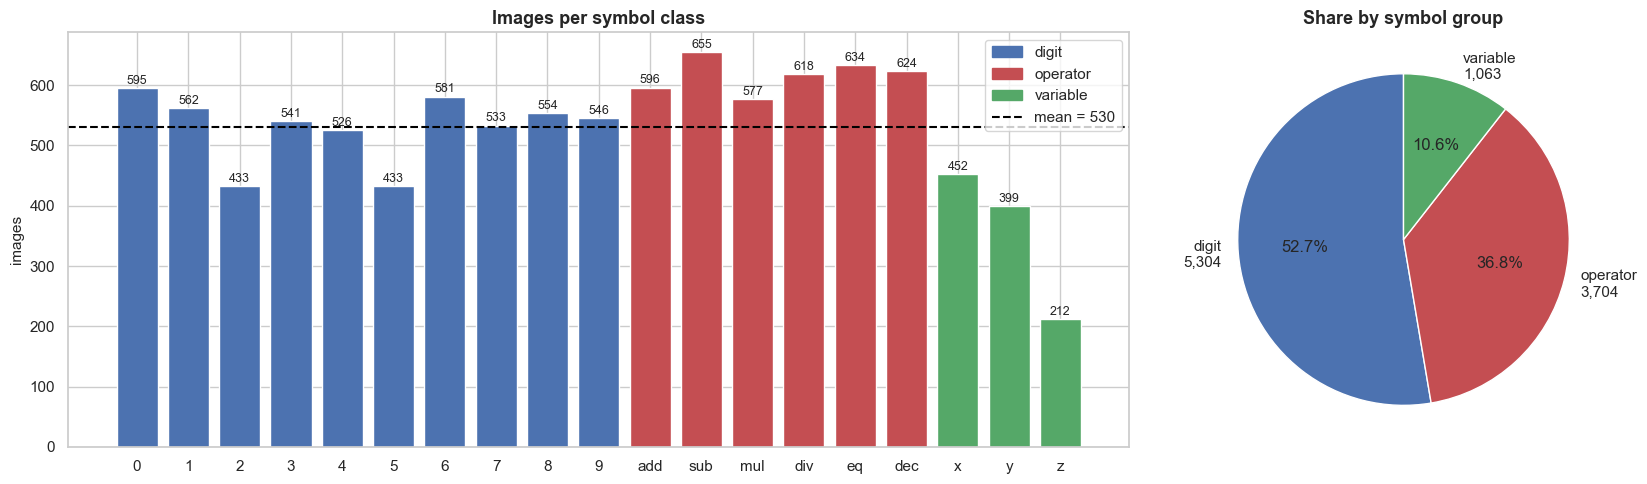

In [21]:
assert SYMBOL_DIR.exists(), f"Symbol folder not found: {SYMBOL_DIR}"
rec, non_img = [], 0
for cls_dir in sorted(d for d in SYMBOL_DIR.iterdir() if d.is_dir()):
    for p in cls_dir.rglob("*"):
        if not p.is_file(): continue
        if p.suffix.lower() in IMG_EXTS:
            rec.append(dict(cls=cls_dir.name, path=str(p), ext=p.suffix.lower(), size=p.stat().st_size))
        else: non_img += 1
sym_idx = pd.DataFrame(rec)
stray_files = [p.name for p in SYMBOL_DIR.iterdir() if p.is_file()]
present = set(sym_idx.cls)
SYM_CLASSES = [c for c in SYMBOL_ORDER if c in present] + sorted(present - set(SYMBOL_ORDER))
cls_counts = sym_idx.cls.value_counts().reindex(SYM_CLASSES)
sym_group = pd.Series({c: SYMBOL_GROUP.get(c, "other") for c in SYM_CLASSES})
GROUP_COLOR = {"digit": PALETTE[0], "operator": PALETTE[3], "variable": PALETTE[2], "other": PALETTE[7]}

fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(SYM_CLASSES, cls_counts.values, color=[GROUP_COLOR[sym_group[c]] for c in SYM_CLASSES])
axes[0].axhline(cls_counts.mean(), color="black", ls="--", label=f"mean = {cls_counts.mean():,.0f}")
axes[0].set_title("Images per symbol class"); axes[0].set_ylabel("images"); axes[0].legend(); label_bars(axes[0], horizontal=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for k, c in GROUP_COLOR.items() if k in set(sym_group)]
axes[0].legend(handles + [plt.Line2D([0], [0], color="black", ls="--")], [k for k in GROUP_COLOR if k in set(sym_group)] + [f"mean = {cls_counts.mean():,.0f}"])
grp = cls_counts.groupby(sym_group).sum()
axes[1].pie(grp.values, labels=[f"{g}\n{v:,}" for g, v in grp.items()], autopct="%1.1f%%", colors=[GROUP_COLOR[g] for g in grp.index], startangle=90)
axes[1].set_title("Share by symbol group")
plt.tight_layout(); plt.show()

imb_ratio = cls_counts.max() / cls_counts.min()
sym_class_weights = (cls_counts.sum() / (len(cls_counts) * cls_counts)).round(3)

#### 📌 Observation
- The symbol folder holds **10,071 images in 19 classes**: 10 digits, 6 operators (`add`, `sub`, `mul`, `div`, `eq`, `dec`) and 3 variables (`x`, `y`, `z`). The per-class mean is 530; the largest class is `sub` (655) and the smallest is **`z` (212)**, an imbalance ratio of **3.09×**.
- The bar chart shows operators as the best-covered group (577-655 images each) and variables as the weakest: `x` 452, `y` 399, `z` 212. Digits range from 433 (`2` and `5`) to 595 (`0`). Group shares: digits 5,304 (52.7%), operators 3,704 (36.8%), variables 1,063 (10.6%).
- Stray files: one `.directory` file at the top level and one non-image file inside the class folders.

#### 💡 Pipeline / Engineering Decision
- Training uses **class-weighted cross-entropy** (weights 0.81 to 2.5; `z` gets the highest weight) or a weighted sampler, and the headline metric is **macro-F1** plus per-class recall, not plain accuracy.
- Variables are only 10.6% of images although `x`, `y`, `z` occur in most algebra expressions, so `z` and `y` get stronger augmentation.
- Splits are stratified per class, and the loader uses an extension whitelist so `.directory` and other stray files are ignored.

---
## Step 20 — Image Metadata — Resolution, Colour Mode & File Format

### ❓ Why
Bars of the **most common image sizes, colour modes and file formats** plus a **file-size histogram** confirm whether the dataset is uniform (one fixed size) or heterogeneous. 
Reading only image *headers* (no pixel decode) makes this scan fast even for tens of thousands of images and also detects corrupt files.

### 💼 Business Insight
A uniform 45×45 dataset and a mixed-resolution one need very different preprocessing. Mixed formats / colour modes are also a **production risk**: user uploads from phones (RGB/RGBA JPEG) will not look like the grayscale training images unless we convert deliberately.

Reading image headers:   0%|          | 0/10071 [00:00<?, ?it/s]

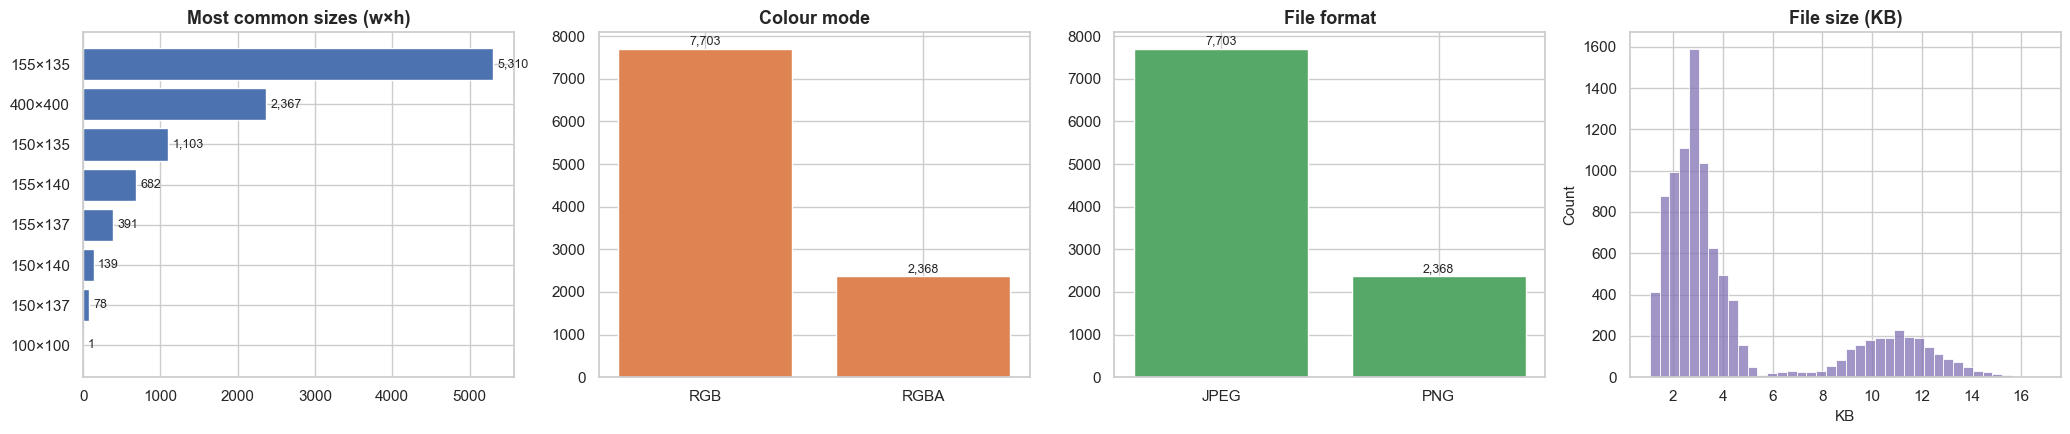

In [22]:
sym_sample = cap_per_group(sym_idx, "cls", MAX_SYMBOL_IMAGES_PER_CLASS)
meta = []
for p in tqdm(sym_sample.path, desc="Reading image headers"):
    try:
        with Image.open(p) as im: meta.append((im.width, im.height, im.mode, im.format))
    except Exception:
        meta.append((np.nan, np.nan, None, None))
sym_meta = pd.concat([sym_sample.reset_index(drop=True), pd.DataFrame(meta, columns=["w", "h", "mode", "fmt"])], axis=1)
sym_meta["size_str"] = sym_meta.w.astype("Int64").astype(str) + "×" + sym_meta.h.astype("Int64").astype(str)
corrupt = int(sym_meta.w.isna().sum())

fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
sm = sym_meta.size_str.value_counts().head(8).iloc[::-1]; axes[0].barh(sm.index, sm.values, color=PALETTE[0]); axes[0].set_title("Most common sizes (w×h)"); label_bars(axes[0])
md_ = sym_meta["mode"].value_counts(); axes[1].bar(md_.index.astype(str), md_.values, color=PALETTE[1]); axes[1].set_title("Colour mode"); label_bars(axes[1], horizontal=False)
ft = sym_meta["fmt"].value_counts(); axes[2].bar(ft.index.astype(str), ft.values, color=PALETTE[2]); axes[2].set_title("File format"); label_bars(axes[2], horizontal=False)
sns.histplot(sym_meta["size"] / 1024, bins=40, color=PALETTE[4], ax=axes[3]); axes[3].set_title("File size (KB)"); axes[3].set_xlabel("KB")
plt.tight_layout(); plt.show()

side = sym_meta[["w", "h"]].max(axis=1)
SYM_INPUT = int(np.clip(round(side.median() / 16) * 16, 32, 64))

#### 📌 Observation
- All **10,071 headers were readable (0 corrupt)**, but the images come from **two clearly different sources**: **7,703 JPEG / RGB images (76.5%) of about 155×135 px** (155×135: 5,310, 150×135: 1,103, 155×140: 682, 155×137: 391, 150×140: 139, 150×137: 78) and **2,368 PNG / RGBA images (23.5%)**, which are almost all **400×400** (2,367) plus a single 100×100 file.
- The file-size histogram is bimodal: JPEGs cluster at about 2-4 KB (median overall 3.04 KB) and the PNGs at about 8-14 KB (P95 12.25 KB).
- The median longest side is 155 px, so the 64×64 target is a large down-scaling for both sources (2.4× and 6.3×).

#### 💡 Pipeline / Engineering Decision
- The model input is **64×64 grayscale**. Every image is converted to single-channel `L` (RGBA composited on white), which also covers phone uploads in production.
- Because the two sources differ by 2.6× in size, symbols are ink-box-cropped and letter-boxed so both land at the same effective scale; the source (JPEG vs PNG) is stored as metadata, splits are stratified by class **and** source, and accuracy is reported per source.
- The single 100×100 file is inspected and removed if it is not a valid sample; headers are verified once at dataset-build time.

---
## Step 21 — Visual Inspection — Random Samples Per Class

### ❓ Why
A **class-by-class image grid** (8 random images per class) is the quickest way to spot mislabelled folders, inconsistent stroke thickness, polarity flips or cropping problems that no summary statistic would reveal.

### 💼 Business Insight
If the folder called `mul` contains `x` letters, no architecture can fix that. A two-minute visual audit protects weeks of training time and guards against shipping a calculator that confuses × and x.

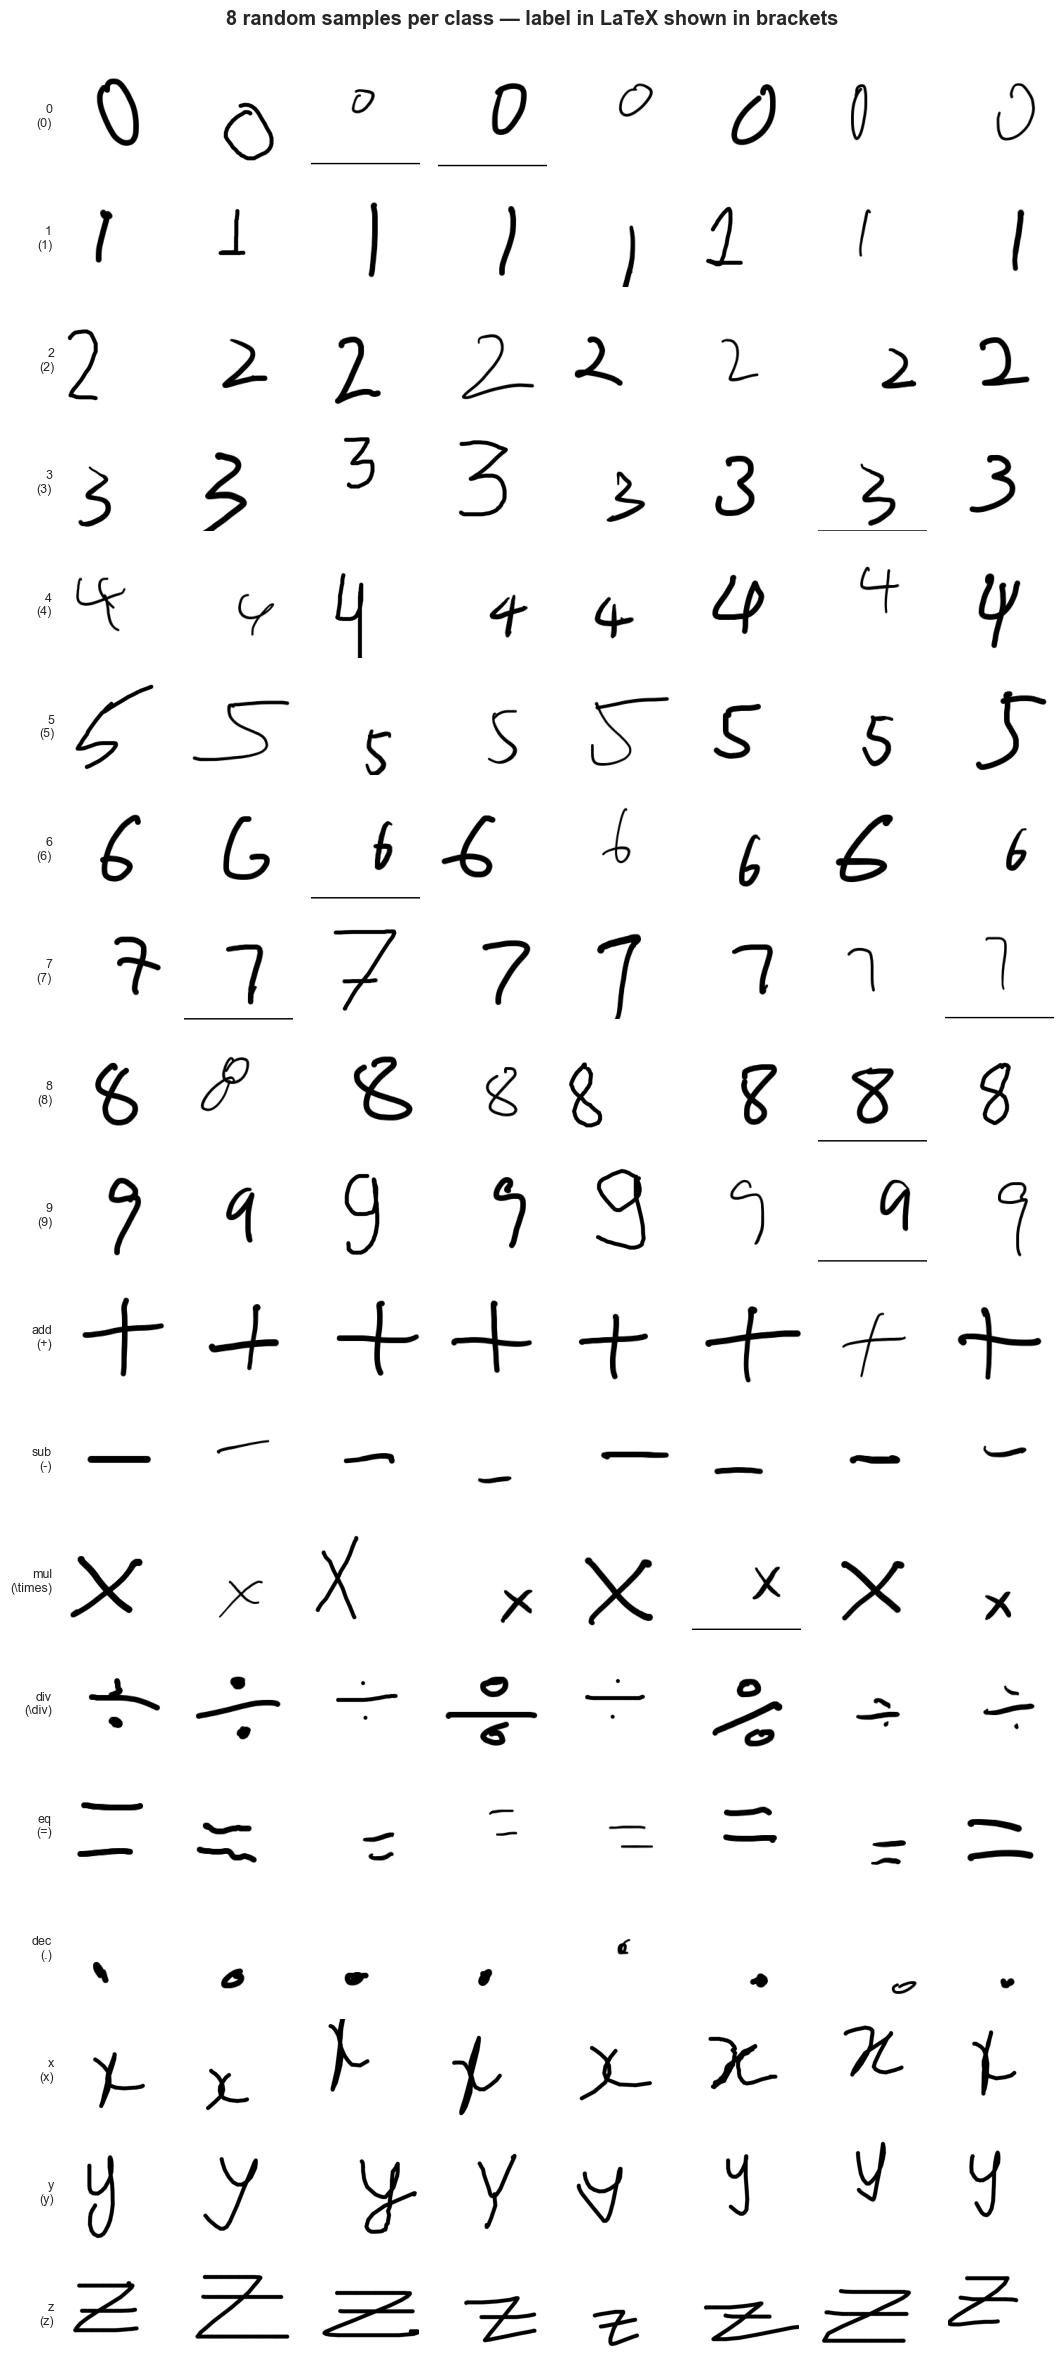

In [23]:
n_per = 8
fig, axes = plt.subplots(len(SYM_CLASSES), n_per, figsize=(1.35 * n_per, 1.25 * len(SYM_CLASSES)))
for i, c in enumerate(SYM_CLASSES):
    pool = sym_sample[sym_sample.cls == c]
    picks = pool.sample(min(n_per, len(pool)), random_state=SEED)
    for j in range(n_per):
        ax = axes[i, j]; ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if j < len(picks):
            arr, _ = load_gray(picks.path.iloc[j]); ax.imshow(arr, cmap="gray", vmin=0, vmax=1)
        if j == 0: ax.set_ylabel(f"{c}\n({SYMBOL_TO_LATEX.get(c, '?')})".replace("$", ""), rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("8 random samples per class — label in LaTeX shown in brackets", y=1.0, fontweight="bold")
plt.tight_layout(); plt.show()

#### 📌 Observation
- The 19 × 8 grid shows correctly labelled folders and no foreign-class contamination in the displayed samples, but it reveals an artefact: **about 9 of the 152 displayed images (~6%) have a thin horizontal ruled line under the symbol** (classes `0`, `3`, `6`, `7`, `8`, `9` and `mul`).
- Within-class variation is large. `dec` ranges from a tiny speck to a thick blob, `sub` is a short bar of varying length and tilt, `1` appears with a flag or a foot (one sample looks like `⊥`), `x` is written as a cursive loop while `mul` is a clean large X, and `div` has variants (÷ with dots, and one bar-with-two-circles sample that looks like `%`).
- Stroke thickness varies strongly between samples, from thin pen lines to thick marker strokes.

#### 💡 Pipeline / Engineering Decision
- A **ruled-line removal step** (morphological opening with a long thin horizontal kernel, or cropping at the ink bounding box) runs before resizing. An opposite augmentation that **adds random ruled lines** keeps the model robust to notebook paper in real photos.
- Augmentation: ±10° rotation, scale and stroke-thickness jitter, with **no flips** (they would turn `2`, `5`, `7` into other glyphs).
- The odd `div` sample (looks like `%`) and the `⊥`-like `1` go to a manual review list; the 19×8 grid is repeated on every dataset refresh to catch mislabelled folders.

---
## Step 22 — Pixel & Ink Statistics — Polarity, Ink Ratio & Class Prototypes

### ❓ Why
Per image we measure **background polarity** (dark-on-light vs light-on-dark), **ink coverage** and bounding box. Charts: a **stacked polarity bar per class** (is the dataset consistent?), a **box-plot of ink ratio per class**, and a **grid of per-class mean images (prototypes)** that shows the "average" look of each symbol.

### 💼 Business Insight
Mixed polarity is a classic silent failure: a model trained on black-on-white fails on white-on-black uploads. Ink ratio tells us how little signal tiny symbols (`dec`, `sub`) carry — the root cause of many real-world misreads.

Pixel statistics:   0%|          | 0/5612 [00:00<?, ?it/s]

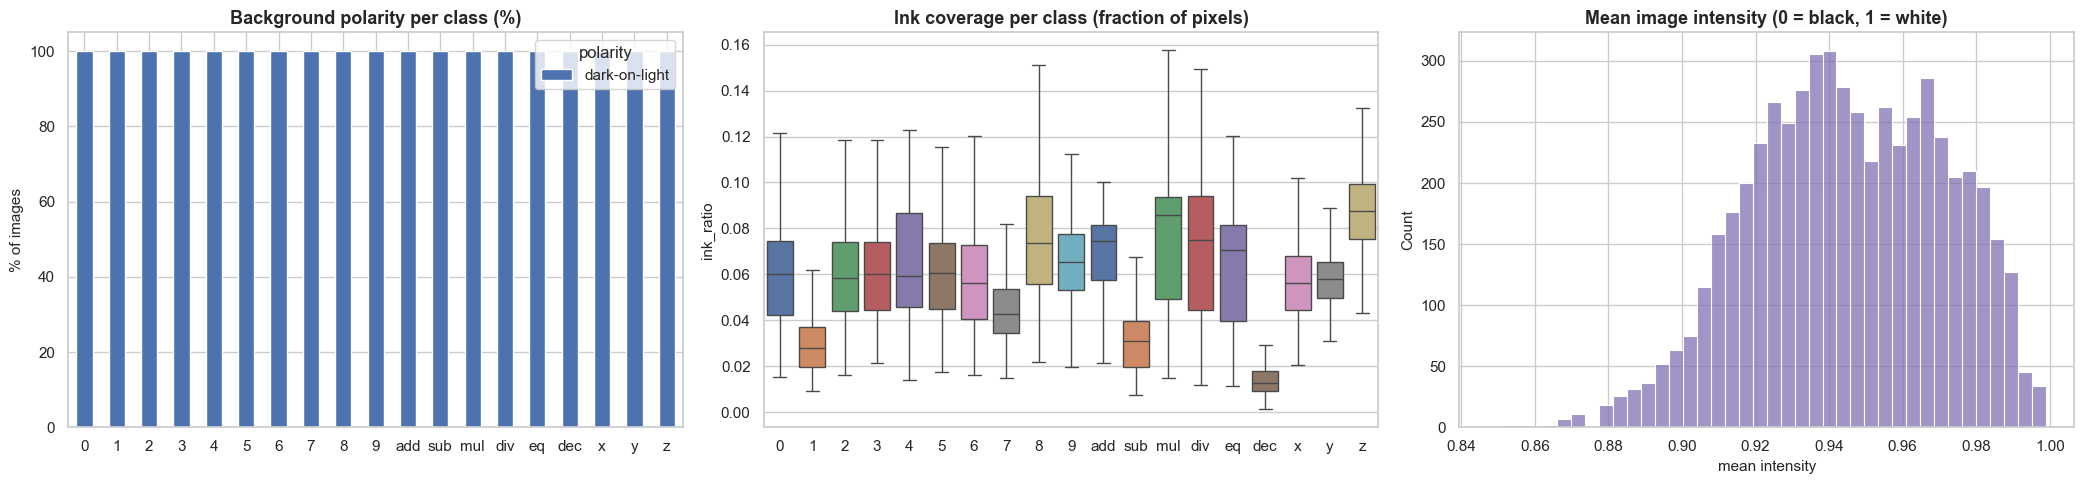

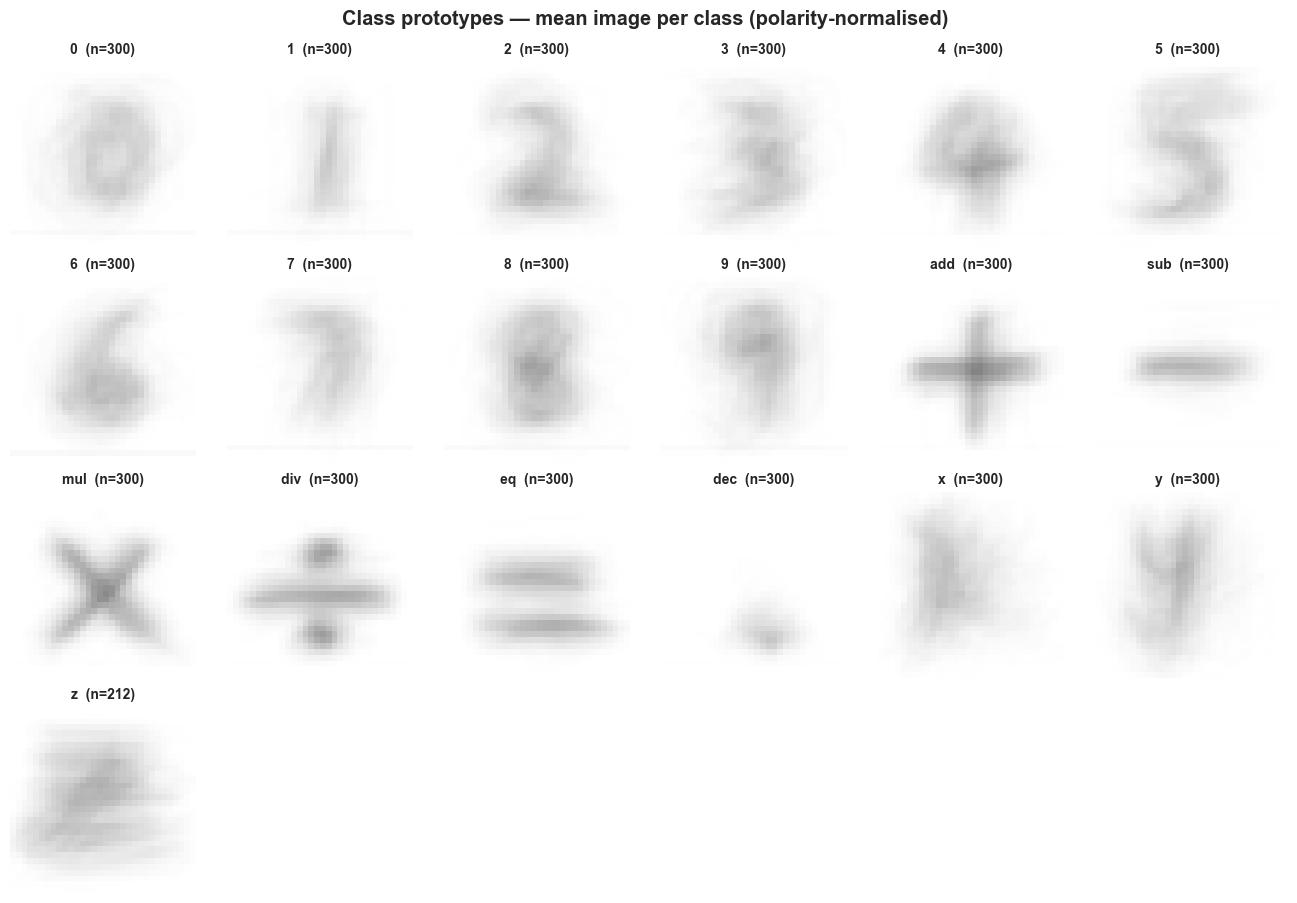

In [24]:
SYM_SIZE = (32, 32)
pix_df = cap_per_group(sym_idx, "cls", SYMBOL_PIXEL_SAMPLE)
rows, imgs = [], []
for r in tqdm(pix_df.itertuples(index=False), total=len(pix_df), desc="Pixel statistics"):
    try: arr, bg = load_gray(r.path)
    except Exception: continue
    bb, ink_ratio = ink_bbox(arr, bg)
    norm = arr if bg >= 0.5 else 1.0 - arr                     # force background = white, ink = dark
    h_img, w_img = arr.shape
    if bb is None: ink_h = ink_w = np.nan
    else: ink_h, ink_w = bb[1] - bb[0] + 1, bb[3] - bb[2] + 1
    rows.append(dict(cls=r.cls, path=r.path, bg=bg, polarity="dark-on-light" if bg >= 0.5 else "light-on-dark",
                     ink_ratio=ink_ratio, ink_h=ink_h, ink_w=ink_w, img_h=h_img, img_w=w_img,
                     mean_int=float(arr.mean())))
    imgs.append(to_square(norm, SYM_SIZE))
sym_stats = pd.DataFrame(rows)
X_sym = np.stack(imgs); y_sym = sym_stats.cls.values
sym_stats["ink_aspect"] = sym_stats.ink_w / sym_stats.ink_h
sym_stats["fill_h"] = sym_stats.ink_h / sym_stats.img_h
sym_stats["fill_w"] = sym_stats.ink_w / sym_stats.img_w

fig, axes = plt.subplots(1, 3, figsize=(21, 5))
pol = pd.crosstab(sym_stats.cls, sym_stats.polarity).reindex(SYM_CLASSES)
pol.div(pol.sum(1), axis=0).mul(100).plot(kind="bar", stacked=True, ax=axes[0], color=[PALETTE[0], PALETTE[1]][:pol.shape[1]], rot=0)
axes[0].set_title("Background polarity per class (%)"); axes[0].set_xlabel(""); axes[0].set_ylabel("% of images")
sns.boxplot(data=sym_stats, x="cls", y="ink_ratio", order=SYM_CLASSES, showfliers=False, ax=axes[1], palette="deep")
axes[1].set_title("Ink coverage per class (fraction of pixels)"); axes[1].set_xlabel("")
sns.histplot(sym_stats.mean_int, bins=40, color=PALETTE[4], ax=axes[2]); axes[2].set_title("Mean image intensity (0 = black, 1 = white)"); axes[2].set_xlabel("mean intensity")
plt.tight_layout(); plt.show()

ncols = 6; nrows = int(np.ceil(len(SYM_CLASSES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 2.3 * nrows))
for ax in np.ravel(axes): ax.axis("off")
for ax, c in zip(np.ravel(axes), SYM_CLASSES):
    ax.imshow(X_sym[y_sym == c].mean(0), cmap="gray", vmin=0, vmax=1); ax.set_title(f"{c}  (n={int((y_sym == c).sum())})", fontsize=10)
plt.suptitle("Class prototypes — mean image per class (polarity-normalised)", fontweight="bold"); plt.tight_layout(); plt.show()

#### 📌 Observation
- On 5,612 analysed images (300 per class, 212 for `z`) polarity is **100% dark-on-light** with no mixed class. Ink coverage has a median of **5.8%**; the lowest classes are `dec` (1.3%), `1` (~2.8%), `sub` (~3.1%) and `7` (~4.3%), the highest are `z` (8.7%) and `mul`, `div`, `8` (~7.5-8.6%). Mean intensity ranges from about 0.86 to 1.0 (average 0.94).
- In the prototype grid, `add`, `sub`, `mul`, `div`, `eq` and `dec` give sharp, well-centred prototypes (consistent shape and size), the digits are blurrier, and `x`, `y`, `z` are the most diffuse (highest within-class variation). Several digit prototypes (e.g. `0`, `6`, `7`, `8`, `9`) show a faint horizontal line at the bottom edge, which confirms the ruled-line artefact from Step 21.
- These statistics were computed on 32×32 letter-boxed images for speed; the training input is 64×64.

#### 💡 Pipeline / Engineering Decision
- Polarity is consistent, but the loader still inverts an image whose border median is dark, to protect against production uploads.
- `dec`, `1` and `sub` carry only 1-3% ink, so they get stroke-thickness augmentation (dilate / erode) to avoid dependence on a few pixels.
- Normalisation uses training-set mean and std only. Ruled-line removal (Step 21) is applied before the prototypes are recomputed, so the bottom-edge line disappears from them.

---
## Step 23 — Ink Bounding-Box Geometry — Aspect Ratio & Canvas Fill

### ❓ Why
Box-plots of the **ink aspect ratio (width/height)** and **canvas fill** per class show whether symbols are naturally wide (`sub`, `eq`), tall (`1`, `div`) or square, and whether writers fill the canvas. 
These are *shape* features: they tell us how much information is lost if every image is naively stretched to a square.

### 💼 Business Insight
Stretching a thin `-` into a square makes it look like a blob — and a fraction bar or minus sign is the cheapest symbol to get wrong. Shape statistics justify aspect-preserving preprocessing, which directly improves operator accuracy.

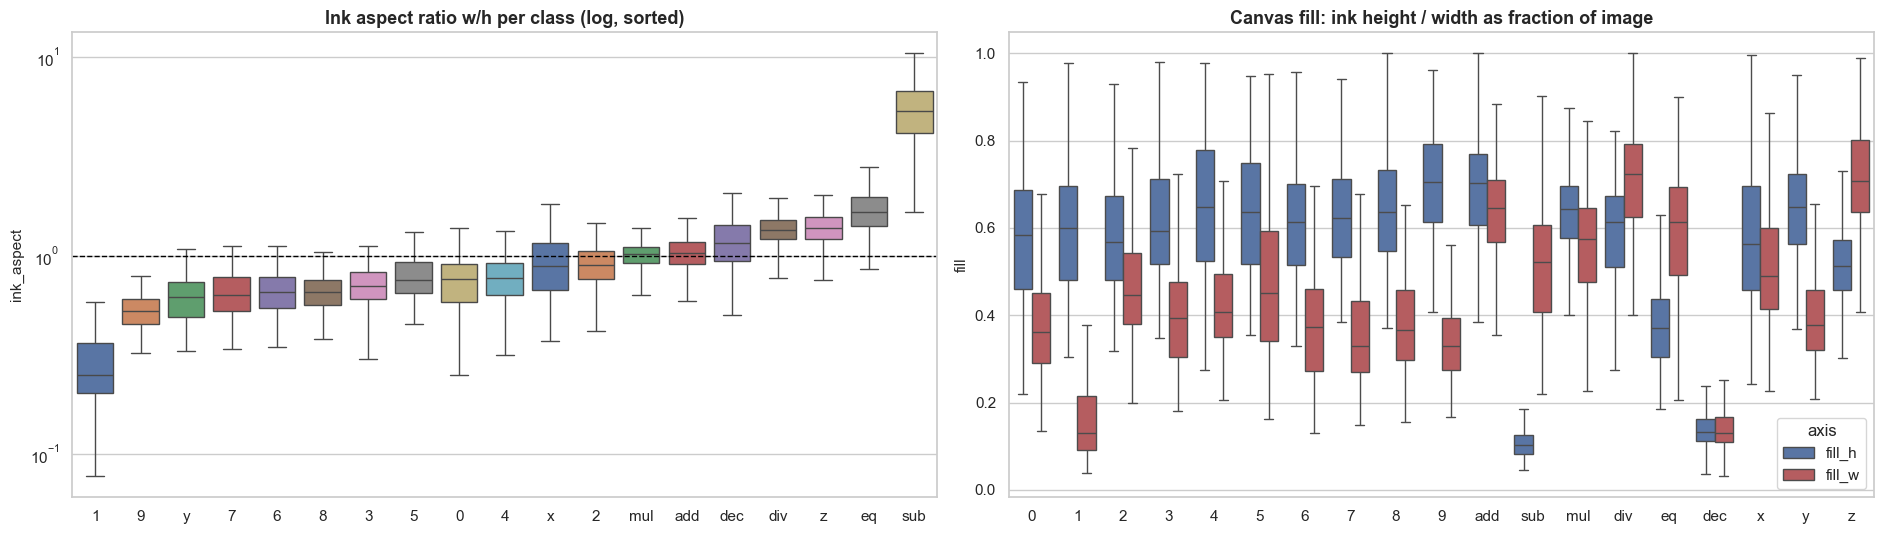

In [25]:
order_aspect = sym_stats.groupby("cls").ink_aspect.median().sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(19, 5.5))
sns.boxplot(data=sym_stats, x="cls", y="ink_aspect", order=order_aspect, showfliers=False, ax=axes[0], palette="deep")
axes[0].axhline(1, color="black", ls="--", lw=1); axes[0].set_yscale("log")
axes[0].set_title("Ink aspect ratio w/h per class (log, sorted)"); axes[0].set_xlabel("")
sns.boxplot(data=sym_stats.melt(id_vars="cls", value_vars=["fill_h", "fill_w"], var_name="axis", value_name="fill"),
            x="cls", y="fill", hue="axis", order=SYM_CLASSES, showfliers=False, ax=axes[1], palette=[PALETTE[0], PALETTE[3]])
axes[1].set_title("Canvas fill: ink height / width as fraction of image"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
asp = sym_stats.groupby("cls").ink_aspect.median()

#### 📌 Observation
- Median ink aspect ratio (width / height): `sub` **5.34** (most samples between about 4 and 7), `eq` 1.67, `z` 1.38, `div` about 1.35; the tallest classes are `1` **0.25**, `9` 0.52, `y` 0.62. Two classes are clearly wide (> 1.5) and six clearly tall (< 0.7).
- Canvas fill is small for some symbols: `sub` fills only about 10% of the image height, `dec` about 13% of both height and width, and `1` only about 13% of the width. The overall median fill is 58% of the height and 43% of the width, and the P5 of the larger side is only 23%, so some symbols are tiny inside the canvas.
- Upper whiskers of fill-width for several digits reach 0.7-0.8, which is consistent with the ruled-line artefact widening some ink boxes.

#### 💡 Pipeline / Engineering Decision
- Resizing never stretches: images are letter-boxed so `sub` stays a thin bar and `1` stays tall.
- At inference the symbol is **re-centred on its ink box but not rescaled to fill the canvas**, because absolute size is a real class cue (`dec` vs `0`, `sub` vs a long stroke); the ink-box size and aspect ratio are also passed as extra inputs to the expression decoder.
- Aspect ratio is computed after ruled-line removal, otherwise the underline distorts it for digits.

---
## Step 24 — Duplicate & Label-Conflict Detection (Symbols)

### ❓ Why
We hash image **bytes** (exact duplicates) and a **32×32 4-bit-quantised pixel fingerprint** (re-saved / re-encoded copies). A **bar of duplicate share per class** and a **count of cross-class conflicts** (same image under two labels) separate harmless redundancy from genuine label errors.

### 💼 Business Insight
Duplicates that land on both sides of a split silently inflate accuracy; cross-class duplicates are outright label noise that caps achievable accuracy. Both are cheap to remove and give an honest model score.

Hashing symbol files:   0%|          | 0/10071 [00:00<?, ?it/s]

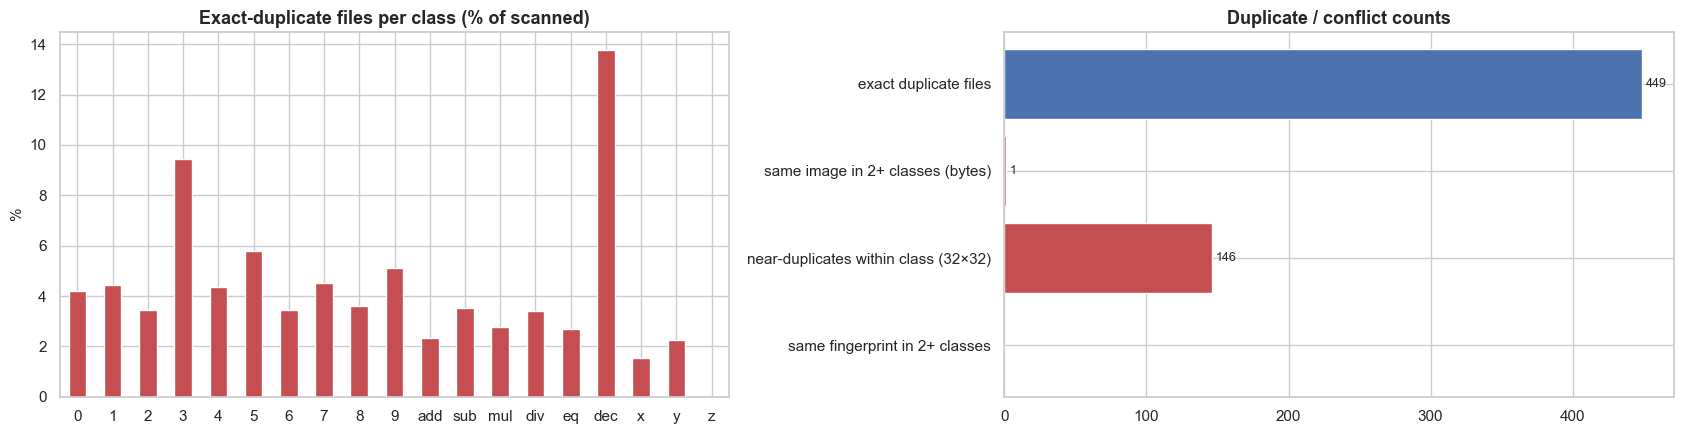

In [26]:
def file_md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f: h.update(f.read())
    return h.hexdigest()

sym_sample = sym_sample.copy()
sym_sample["md5"] = [file_md5(p) for p in tqdm(sym_sample.path, desc="Hashing symbol files")]
dup_mask = sym_sample.duplicated("md5", keep="first")
dup_by_cls = (sym_sample.assign(dup=dup_mask).groupby("cls").dup.mean() * 100).reindex(SYM_CLASSES)
conflict = sym_sample.groupby("md5").cls.nunique(); n_conflict_hash = int((conflict > 1).sum())

q_hash = pd.Series([hashlib.md5((x * 15).round().astype(np.uint8).tobytes()).hexdigest() for x in X_sym])
fp = pd.DataFrame({"cls": y_sym, "fp": q_hash.values})
fp_dup_mask = fp.duplicated(["cls", "fp"], keep="first")
fp_conflict = fp.groupby("fp").cls.nunique(); n_fp_conflict = int((fp_conflict > 1).sum())

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
dup_by_cls.plot(kind="bar", ax=axes[0], color=PALETTE[3], rot=0); axes[0].set_title("Exact-duplicate files per class (% of scanned)"); axes[0].set_xlabel(""); axes[0].set_ylabel("%")
summary = pd.Series({"exact duplicate files": int(dup_mask.sum()), "same image in 2+ classes (bytes)": n_conflict_hash,
                     "near-duplicates within class (32×32)": int(fp_dup_mask.sum()), "same fingerprint in 2+ classes": n_fp_conflict})
axes[1].barh(summary.index[::-1], summary.values[::-1], color=[PALETTE[1], PALETTE[3], PALETTE[3], PALETTE[0]]); axes[1].set_title("Duplicate / conflict counts"); label_bars(axes[1])
plt.tight_layout(); plt.show()

#### 📌 Observation
- **449 of 10,071 files (4.46%) are exact duplicates.** The per-class bars show `dec` at **13.8%**, `3` at about 9.4%, `5` about 5.8%, `9` about 5.1%, most other classes between 2% and 4.5%, and `z` at 0%.
- **1 file** appears under two different classes (identical bytes), and there are **146 near-duplicates inside the same class** (2.6% of the 5,612-image pixel sample) but **0 cross-class fingerprint conflicts**.
- These counts come from per-class samples capped at 2,000 (never reached here), so they describe the full dataset.

#### 💡 Pipeline / Engineering Decision
- Exact duplicates are removed before splitting (first copy kept); the cross-class duplicate is quarantined for manual review as label noise.
- Splits are built on **hash groups**, so exact and near-duplicate images (146 pairs) stay on one side of the split.
- The high duplicate rate of `dec` (13.8%) and `3` (9.4%) is logged in the data card, because it would inflate validation accuracy for exactly those classes.

---
## Step 25 — Class Confusability — Prototype Similarity & Nearest-Centroid Baseline

### ❓ Why
Two heatmaps answer *"which symbols will the model confuse?"*: the **correlation between class prototypes** (visual similarity) and the **normalised confusion matrix of a trivial nearest-centroid classifier** (empirical confusion with zero training). 
A deliberately weak baseline is the right tool here — whatever it already separates is easy, and its mistakes mark the genuinely hard pairs.

### 💼 Business Insight
The confusable pairs (e.g. `x`/`mul`, `1`/`div`, `sub`/`eq`) change the *meaning* of an equation. Knowing them early lets us add **context** (neighbouring symbols, grammar) where pixels alone cannot decide, which is how a calculator-grade product reaches user trust.

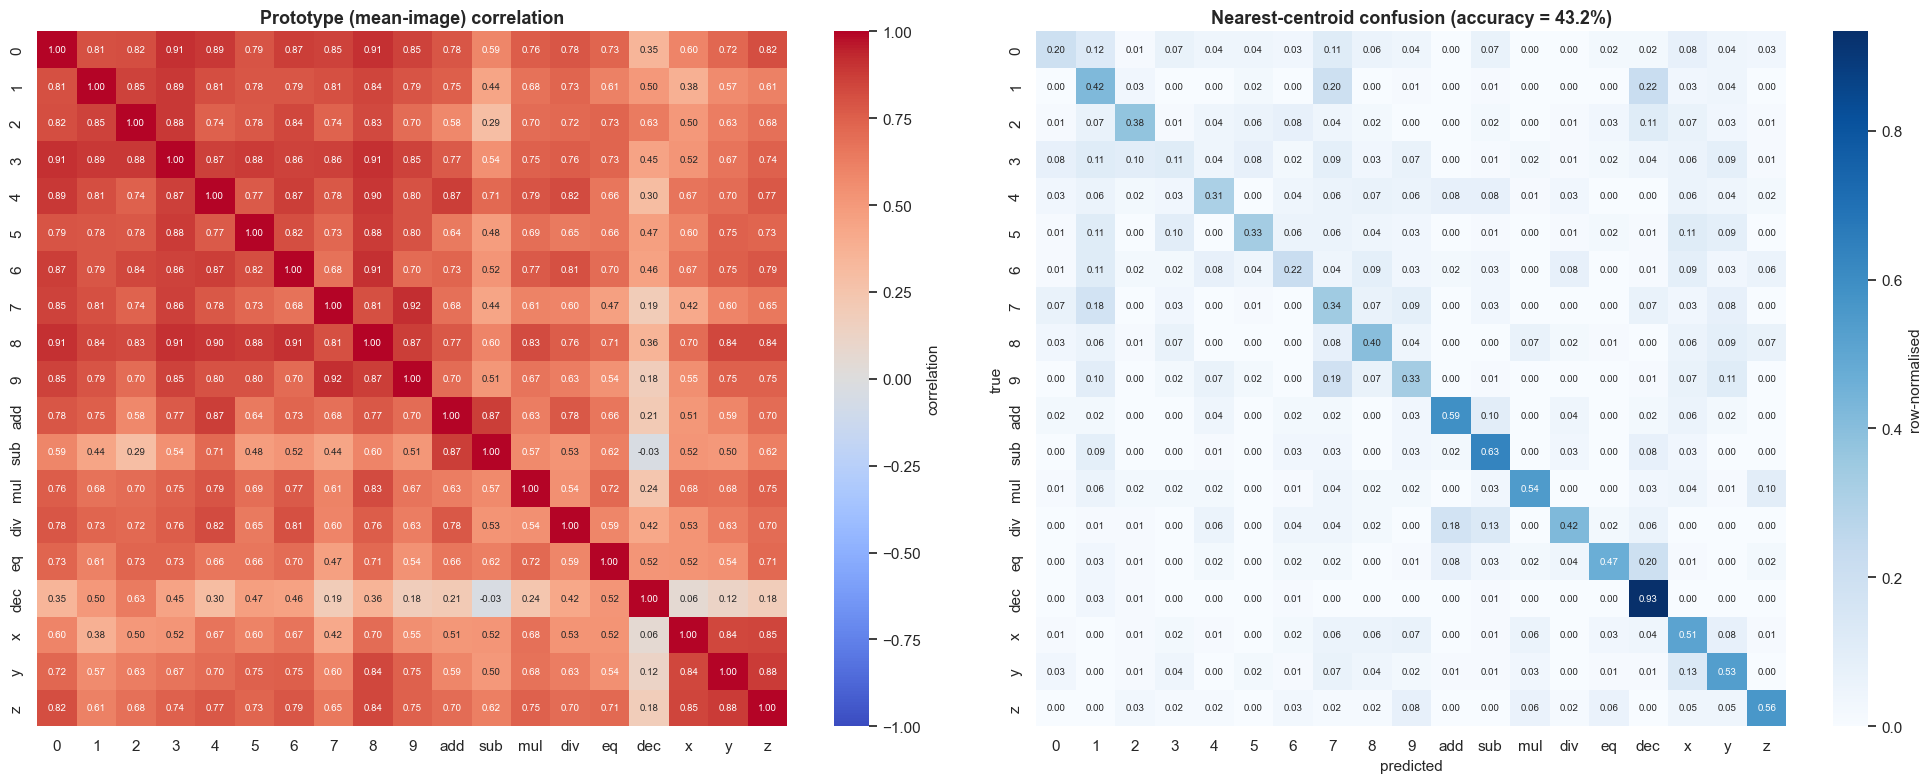

,class_a,class_b,mutual_confusion,proto_corr
23,1,7,0.378,0.808
106,7,9,0.278,0.916
31,1,dec,0.256,0.505
137,add,div,0.222,0.777
168,x,y,0.211,0.842
161,eq,dec,0.200,0.519
52,3,5,0.178,0.881
6,0,7,0.178,0.854


In [27]:
Xf = X_sym.reshape(len(X_sym), -1)
Xtr, Xte, ytr, yte = train_test_split(Xf, y_sym, test_size=0.3, stratify=y_sym, random_state=SEED)
nc = NearestCentroid().fit(Xtr, ytr)
pred = nc.predict(Xte)
base_acc = float((pred == yte).mean())
cm = confusion_matrix(yte, pred, labels=SYM_CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

protos = np.stack([X_sym[y_sym == c].mean(0).ravel() for c in SYM_CLASSES])
proto_corr = np.corrcoef(protos)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(proto_corr, xticklabels=SYM_CLASSES, yticklabels=SYM_CLASSES, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[0], cbar_kws={"label": "correlation"})
axes[0].set_title("Prototype (mean-image) correlation")
sns.heatmap(cm_norm, xticklabels=SYM_CLASSES, yticklabels=SYM_CLASSES, cmap="Blues", annot=True, fmt=".2f", annot_kws={"size": 7}, ax=axes[1], cbar_kws={"label": "row-normalised"})
axes[1].set_title(f"Nearest-centroid confusion (accuracy = {base_acc * 100:.1f}%)"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
plt.tight_layout(); plt.show()

pairs = []
for i in range(len(SYM_CLASSES)):
    for j in range(i + 1, len(SYM_CLASSES)):
        pairs.append((SYM_CLASSES[i], SYM_CLASSES[j], cm_norm[i, j] + cm_norm[j, i], proto_corr[i, j]))
pair_df = pd.DataFrame(pairs, columns=["class_a", "class_b", "mutual_confusion", "proto_corr"]).sort_values("mutual_confusion", ascending=False)
display(pair_df.head(8).round(3))
per_cls_acc = pd.Series(np.diag(cm_norm), index=SYM_CLASSES)
HARD_PAIRS = [(a, b) for a, b, m, _ in pair_df.head(5).itertuples(index=False) if m > 0]

#### 📌 Observation
- A nearest-centroid classifier reaches only **43.2% accuracy** on 1,684 hold-out images. Recall is high for `dec` (93%) and moderate for operators and variables (`sub` 63%, `add` 59%, `z` 56%, `mul` 54%, `y` 53%, `x` 51%, `eq` 47%, `div` 42%), but **digits are the hard group**: `1` 42%, `8` 40%, `2` 38%, `7` 34%, `9` 33%, `5` 33%, `4` 31%, `6` 22%, `0` 20% and **`3` only 11%**.
- Most confusable pairs (mutual confusion): `1`↔`7` **0.38**, `7`↔`9` 0.28, `1`↔`dec` 0.26, `add`↔`div` 0.22, `x`↔`y` 0.21, `eq`↔`dec` 0.20, `3`↔`5` 0.18, `0`↔`7` 0.18. Prototype correlations among digits are 0.7-0.92 (highest `7`↔`9` 0.92; `0`↔`3`, `3`↔`8`, `6`↔`8` ≈ 0.91), while `dec` is the least correlated class (as low as -0.03 with `sub`).
- The pair I expected to be worst, `x` vs `mul`, is **not** among the top confusions (about 0.06 each way).

#### 💡 Pipeline / Engineering Decision
- A CNN is required, with a target far above 43% and per-class recall tracked, especially for digits (`3`, `0`, `6`) and the pairs `1`/`7`, `7`/`9`, `3`/`5`, `0`/`7`.
- `1`↔`dec` and `eq`↔`dec` are size confusions at 32 px, so the 64×64 input and the absolute-size cue from Step 23 matter; `add`↔`div` is handled by context in the expression decoder (a bar with dots is `÷`).
- The hard-pair list (`HARD_PAIRS`) drives targeted augmentation and hard-negative mining. The 43.2% figure was measured at 32×32 raw pixels and is a floor, not a model estimate.

---
## Step 26 — Feature-Space Separability — PCA Variance & t-SNE Projection

### ❓ Why
A **PCA explained-variance curve** shows how many dimensions the pixel data really needs, and a **t-SNE scatter coloured by class** gives a picture of cluster structure (tight, well-separated blobs vs overlapping clouds). 
We also quote a **silhouette score** as a number, since t-SNE pictures alone can mislead.

### 💼 Business Insight
This tells us before training whether a **small, fast on-device CNN** will do (clean clusters) or whether we need a bigger network / more context (overlapping clusters). Model size is directly tied to app size, latency and battery use on student phones.

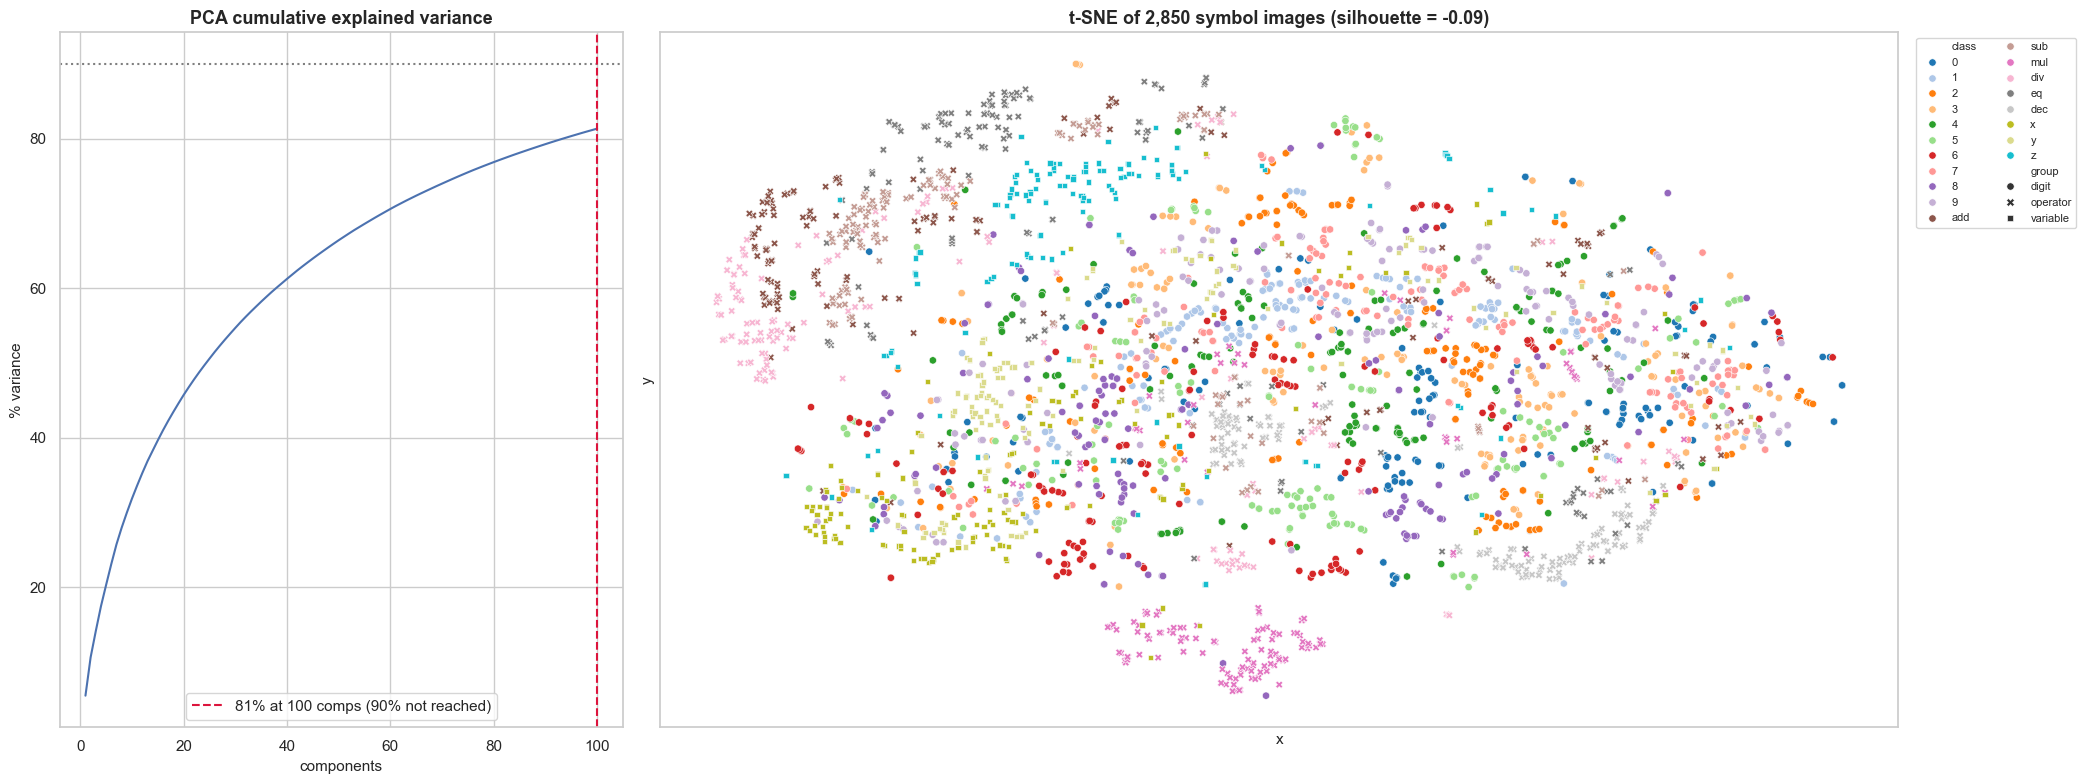

In [28]:
pca_full = PCA(n_components=min(100, Xf.shape[1], len(Xf) - 1), random_state=SEED).fit(Xf)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
reach = lambda t: (int(np.argmax(cum_var >= t)) + 1) if (cum_var >= t).any() else None
k90, k95 = reach(0.90), reach(0.95)

emb_df = cap_per_group(pd.DataFrame({"i": np.arange(len(y_sym)), "cls": y_sym}), "cls", TSNE_PER_CLASS)
Xe = Xf[emb_df.i.values]; ye = emb_df.cls.values
Xp = PCA(n_components=min(50, Xe.shape[1], len(Xe) - 1), random_state=SEED).fit_transform(Xe)
sil = float(silhouette_score(Xp, ye))
Z = TSNE(n_components=2, perplexity=min(30, max(5, len(Xe) // 10)), init="pca", learning_rate="auto", random_state=SEED).fit_transform(Xp)
emb = pd.DataFrame({"x": Z[:, 0], "y": Z[:, 1], "class": ye}); emb["group"] = emb["class"].map(lambda c: SYMBOL_GROUP.get(c, "other"))

fig, axes = plt.subplots(1, 2, figsize=(21, 8), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].plot(np.arange(1, len(cum_var) + 1), cum_var * 100, color=PALETTE[0])
axes[0].axhline(90, color="gray", ls=":")
if k90: axes[0].axvline(k90, color="crimson", ls="--", label=f"90% variance @ {k90} comps")
else:   axes[0].axvline(len(cum_var), color="crimson", ls="--", label=f"{cum_var[-1] * 100:.0f}% at {len(cum_var)} comps (90% not reached)")
axes[0].set_title("PCA cumulative explained variance"); axes[0].set_xlabel("components"); axes[0].set_ylabel("% variance"); axes[0].legend()
sns.scatterplot(data=emb, x="x", y="y", hue="class", style="group", hue_order=SYM_CLASSES, palette=sns.color_palette("tab20", len(SYM_CLASSES)), s=28, ax=axes[1])
axes[1].set_title(f"t-SNE of {len(emb):,} symbol images (silhouette = {sil:.2f})"); axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

#### 📌 Observation
- The PCA curve rises slowly: about **46% of the variance at 20 components, 61% at 40, 71% at 60 and only about 81% at 100**. The 90% line is never reached within 100 components (an earlier printed value of '1 component' was a code bug, fixed in this version).
- The silhouette score on the 50-component PCA space is **-0.09**, i.e. classes overlap heavily in raw pixel space.
- In the t-SNE map the operators form partly separate groups (approximately: `mul` at the bottom, `div` far left, `add` / `sub` upper left, `eq` at the top, `dec` bottom centre), `z` sits at the top centre and `x` at the lower left, while **the ten digits (and `y`) mix inside one large central blob**.

#### 💡 Pipeline / Engineering Decision
- Raw pixels are not compressible and not linearly separable, so there is **no PCA / low-dimensional shortcut and no linear or template classifier**; a CNN with augmentation is the baseline.
- Model size for mobile comes from architecture and quantisation (small CNN, int8), not from a PCA bottleneck.
- The same t-SNE is repeated on the learned embeddings after training; digits separating into clean clusters is the visual acceptance test.

# 🅲 PART C — IM2LaTeX-100k (Rendered Formula Images → LaTeX)
~100k formula images rendered from real arXiv LaTeX, with a **normalised (tokenised) LaTeX ground truth** and an official train / validate / test split. 
It is the large-scale, clean-label dataset of the project — ideal for **pre-training** the image-to-LaTeX decoder before fine-tuning on the small handwritten CROHME data.

---
## Step 27 — Load, Schema Detection & Split Sizes (IM2LaTeX)

### ❓ Why
The CSV layout can differ between mirrors of this dataset, so we **detect the columns programmatically** (image id, formula index, formula text) and stitch the formula table to the split tables. 
A **bar chart of rows per split** with its share shows whether the official split is healthy before we trust it.

### 💼 Business Insight
A correct join between *image → formula* is the foundation of the whole supervised signal; a silent off-by-one in the formula index would train the model on wrong labels at 100k-sample scale. We verify it here rather than discover it through unexplained low accuracy.

Detected columns per split: {'train': ['formula', 'image'], 'val': ['formula', 'image'], 'test': ['formula', 'image']}
Formula table rows: 102,863 | split rows: 94,000 | image files indexed: 103,536


,image,split,formula_idx,formula,stem,path
0,66667cee5b.png,train,NaN,\widetilde \gamma _ { \mathrm { h o p f } } \s...,66667cee5b,D:\Data_Science_Capstone_Datasets\mathvision-a...
1,1cbb05a562.png,train,NaN,"( { \cal L } _ { a } g ) _ { i j } = 0 , \ \ \...",1cbb05a562,D:\Data_Science_Capstone_Datasets\mathvision-a...
2,ed164cc822.png,train,NaN,S _ { s t a t } = 2 \pi \sqrt { N _ { 5 } ^ { ...,ed164cc822,D:\Data_Science_Capstone_Datasets\mathvision-a...
3,e265f9dc6b.png,train,NaN,\hat { N } _ { 3 } = \sum \sp f _ { j = 1 } a ...,e265f9dc6b,D:\Data_Science_Capstone_Datasets\mathvision-a...
4,242a58bc3a.png,train,NaN,"\, ^ { * } d \, ^ { * } H = \kappa \, ^ { * } ...",242a58bc3a,D:\Data_Science_Capstone_Datasets\mathvision-a...


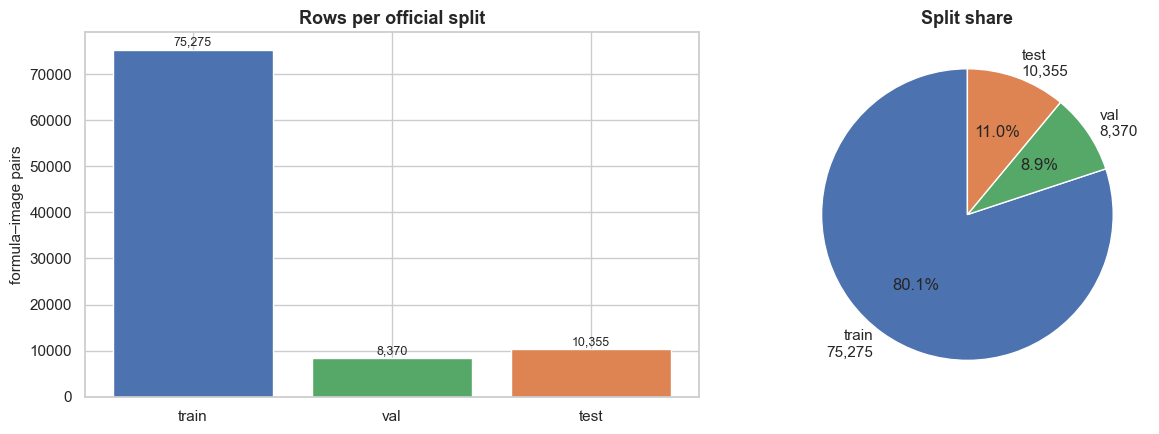

In [29]:
def find_file(patterns):
    for pat in patterns:
        hits = sorted(BASE_DIR.glob(pat))
        if hits: return hits[0]
    return None

F_FORMULAS = find_file(["im2latex_formulas.norm*", "im2latex_formulas*"])
F_SPLITS   = {"train": find_file(["im2latex_train*"]), "val": find_file(["im2latex_validate*", "im2latex_val*"]), "test": find_file(["im2latex_test*"])}
assert F_FORMULAS is not None and all(F_SPLITS.values()), f"IM2LaTeX tables not found in {BASE_DIR}: {F_FORMULAS}, {F_SPLITS}"

def read_formulas(path):
    d = pd.read_csv(path, dtype=str, keep_default_na=False, on_bad_lines="skip", encoding_errors="replace")
    lower = {str(c).lower(): c for c in d.columns}
    if "formula" in lower: return d[lower["formula"]].tolist()
    cand = [c for c in d.columns if any(k in str(c).lower() for k in ("formula", "latex", "text"))]
    if cand: return d[max(cand, key=lambda c: d[c].str.len().mean())].tolist()
    with open(path, encoding="utf-8", errors="replace") as f:       # headerless plain text, one formula per line
        return f.read().splitlines()

def load_split(path, name):
    d = pd.read_csv(path, dtype=str, keep_default_na=False, on_bad_lines="skip", encoding_errors="replace")
    cols = {str(c).lower(): c for c in d.columns}
    img_c = next((cols[c] for c in cols if any(k in c for k in ("image", "img", "file", "name"))), None)
    idx_c = next((cols[c] for c in cols if "idx" in c or c in ("index", "formula_id", "id")), None)
    frm_c = next((cols[c] for c in cols if c in ("formula", "latex", "formula_norm")), None)
    if img_c is None: raise ValueError(f"Cannot find an image column in {path.name}: columns = {list(d.columns)}")
    out = pd.DataFrame({"image": d[img_c], "split": name})
    out["formula_idx"] = pd.to_numeric(d[idx_c], errors="coerce") if idx_c else np.nan
    if frm_c: out["formula"] = d[frm_c]
    return out, list(d.columns)

formulas = read_formulas(F_FORMULAS)
parts, schema = [], {}
for name, path in F_SPLITS.items():
    df_, cols_ = load_split(path, name); parts.append(df_); schema[name] = cols_
im_df = pd.concat(parts, ignore_index=True)
if "formula" not in im_df.columns: im_df["formula"] = ""
im_df["formula"] = im_df["formula"].astype(object)
need = im_df.formula.isna() | (im_df.formula.fillna("") == "")
valid_idx = im_df.formula_idx.notna() & (im_df.formula_idx >= 0) & (im_df.formula_idx < len(formulas))
im_df.loc[need & valid_idx, "formula"] = im_df.loc[need & valid_idx, "formula_idx"].astype(int).map(lambda i: formulas[i])

img_lookup = {}
if IM2LATEX_IMG_DIR.exists():
    with os.scandir(IM2LATEX_IMG_DIR) as it:
        for e in it:
            if e.is_file(): img_lookup[os.path.splitext(e.name)[0]] = e.path
im_df["stem"] = im_df.image.map(lambda s: os.path.splitext(str(s))[0])
im_df["path"] = im_df.stem.map(img_lookup)

print("Detected columns per split:", schema)
print(f"Formula table rows: {len(formulas):,} | split rows: {len(im_df):,} | image files indexed: {len(img_lookup):,}")
display(im_df.head(5).assign(formula=lambda d: d.formula.fillna("").str.slice(0, 70)))

split_ct = im_df.split.value_counts().reindex(["train", "val", "test"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(split_ct.index, split_ct.values, color=[PALETTE[0], PALETTE[2], PALETTE[1]]); axes[0].set_title("Rows per official split"); axes[0].set_ylabel("formula–image pairs"); label_bars(axes[0], horizontal=False)
axes[1].pie(split_ct.values, labels=[f"{k}\n{v:,}" for k, v in split_ct.items()], autopct="%1.1f%%", colors=[PALETTE[0], PALETTE[2], PALETTE[1]], startangle=90); axes[1].set_title("Split share")
plt.tight_layout(); plt.show()

#### 📌 Observation
- All three split tables contain only the two columns `['formula', 'image']`, so the formula text is stored **directly in each split file**; `formula_idx` is empty and the 102,863-row formulas table is only a fallback join. The split tables hold **94,000 labelled rows**: train 75,275 (80.1%), val 8,370 (8.9%), test 10,355 (11.0%).
- The image folder holds **103,536 files**, more than the 94,000 rows; **100% of rows match an image file**. **71 rows have an empty formula.**
- The head of the table shows physics-style formulas (e.g. `\widetilde \gamma _ { \mathrm { h o p f } }`, `\hat { N } _ { 3 } = \sum ...`) in space-separated normalised LaTeX.

#### 💡 Pipeline / Engineering Decision
- The loader uses the `formula` column directly, asserts it is non-empty, and drops the 71 empty rows.
- Images are indexed by file stem, and the official train / val / test split is kept for headline numbers.
- The data card records that this copy is smaller than the full image folder (94,000 rows vs 103,536 images), so published IM2LaTeX numbers are not directly comparable.

---
## Step 28 — LaTeX Sequence Length — Distribution, ECDF & Percentiles

### ❓ Why
A **density histogram per split** checks that train / val / test are drawn from the same distribution, an **ECDF with P50–P99 markers** gives exact cut-offs for a maximum decoding length, and a **box-plot per split** compares spread. 
The ECDF (not just a histogram) is the right chart for choosing a length cap because it reads directly as "what fraction of data do we keep".

### 💼 Business Insight
Sequence length is the **main driver of inference cost** (autoregressive decoding is linear in length) and of training memory. Choosing the cap from the ECDF rather than the maximum trades <1 % of rare monsters for a large cut in latency and GPU bill.

Tokenising IM2LaTeX:   0%|          | 0/94000 [00:00<?, ?it/s]

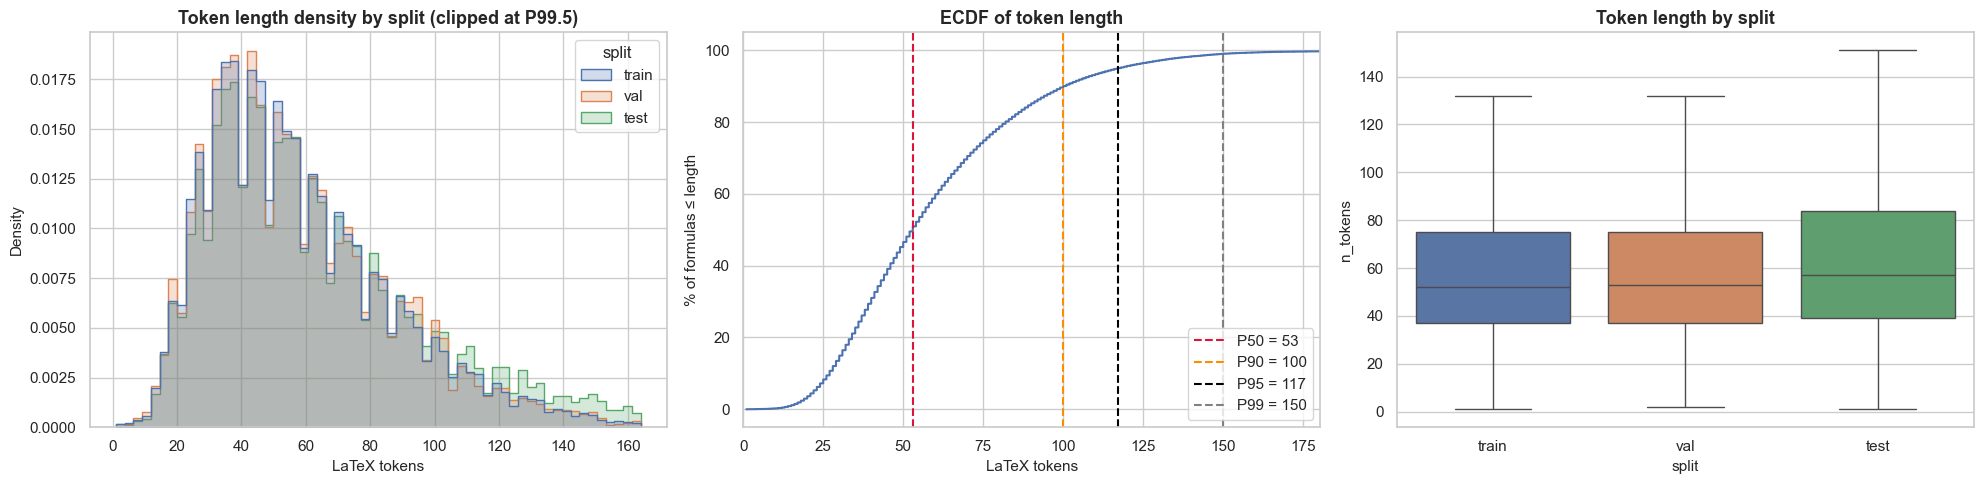

In [30]:
im_df["formula"] = im_df.formula.fillna("").astype(str)
im_df["tokens"] = [tokenize(s) for s in tqdm(im_df.formula, desc="Tokenising IM2LaTeX")]
im_df["n_tokens"] = im_df.tokens.map(len)
im_df["n_chars"] = im_df.formula.str.len()
lab = im_df[im_df.n_tokens > 0]
qs = lab.n_tokens.quantile([.5, .9, .95, .99])
clip_hi = lab.n_tokens.quantile(.995)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(data=lab[lab.n_tokens <= clip_hi], x="n_tokens", hue="split", hue_order=["train", "val", "test"], stat="density", common_norm=False, element="step", bins=60, ax=axes[0])
axes[0].set_title("Token length density by split (clipped at P99.5)"); axes[0].set_xlabel("LaTeX tokens")
x = np.sort(lab.n_tokens.values); y = np.arange(1, len(x) + 1) / len(x)
axes[1].plot(x, y * 100, color=PALETTE[0])
for (k, v), c in zip(qs.items(), ["crimson", "darkorange", "black", "gray"]):
    axes[1].axvline(v, color=c, ls="--", label=f"P{int(k * 100)} = {v:.0f}")
axes[1].set_xlim(0, clip_hi * 1.1); axes[1].set_title("ECDF of token length"); axes[1].set_xlabel("LaTeX tokens"); axes[1].set_ylabel("% of formulas ≤ length"); axes[1].legend(loc="lower right")
sns.boxplot(data=lab, x="split", y="n_tokens", order=["train", "val", "test"], showfliers=False, ax=axes[2], palette="deep"); axes[2].set_title("Token length by split")
plt.tight_layout(); plt.show()

MAX_LEN_IM2LATEX = int(np.ceil(lab.n_tokens.quantile(.99))) + 2
ks = stats.ks_2samp(lab[lab.split == "train"].n_tokens, lab[lab.split == "test"].n_tokens)

#### 📌 Observation
- Token length: median **53**, P90 100, P95 117, P99 **150**, max **662** (mean 59.4); **913 formulas** exceed P99 and 71 are empty after tokenisation. The ECDF shows 90% of formulas at 100 tokens or fewer.
- Train and validation overlap almost exactly (median about 52-53), but the **test set has a heavier right tail** (median about 57 and a visible bump of 100-160-token formulas). The train-vs-test KS statistic is **D = 0.071** (p ≈ 2e-40): significant because of the sample size, but a small shift.
- IM2LaTeX formulas are 3.3× longer than CROHME expressions (median 53 vs 16 tokens).

#### 💡 Pipeline / Engineering Decision
- Training cap `MAX_LEN_IM2LATEX = 152` (P99 + special tokens), with length-bucketed batching. For evaluation the cap is raised so **no test formula is truncated**, since the test tail goes beyond 150.
- Because test is longer than validation, validation scores are expected to be slightly optimistic; results are reported per length bucket and on the test set, not tuned on validation alone.
- The 71 empty rows and the extreme outliers (see Step 32) are dropped from training, and a short-to-long curriculum is used in the first epochs.

---
## Step 29 — IM2LaTeX Vocabulary, Zipf Behaviour & Out-of-Vocabulary Risk

### ❓ Why
The same trio as for CROHME — **Top-30 bar, Zipf plot, coverage curve** — plus a **bar of OOV rates for validation and test** against a vocabulary built from *training data only*. 
OOV rate is the number that tells us how many symbols the model will be asked to emit that it never learned.

### 💼 Business Insight
Every OOV token is a guaranteed error in the user's equation. The OOV rate converts "vocabulary size" from an abstract parameter into a **predictable accuracy loss**, and informs whether to invest in a character/sub-token fallback.

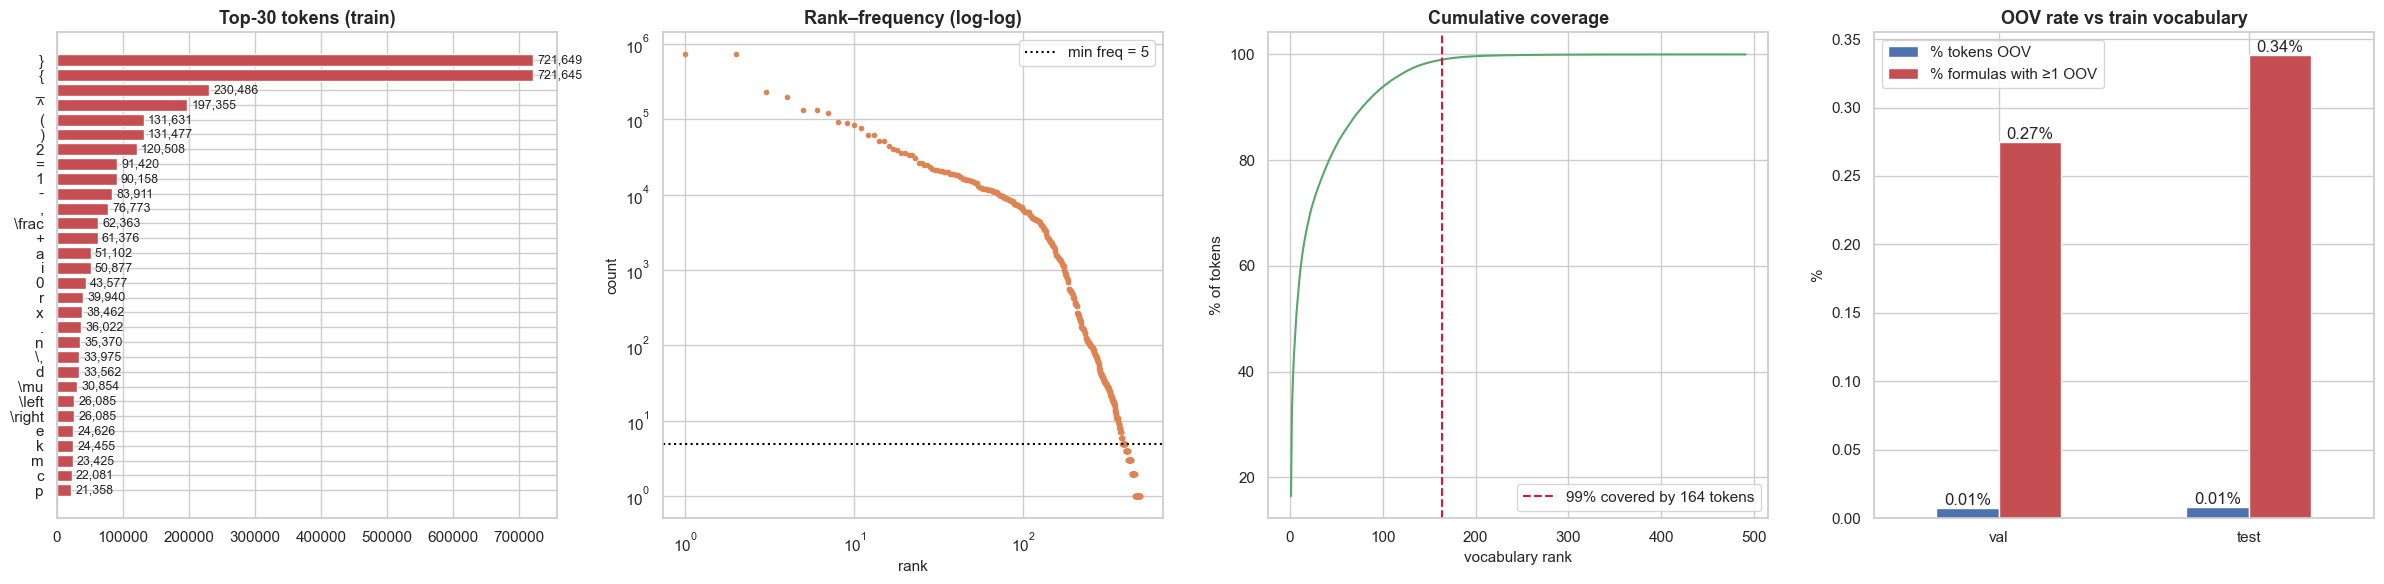

In [31]:
train_tokens = im_df.loc[im_df.split == "train", "tokens"]
im_counter = Counter(t for toks in train_tokens for t in toks)
im_vocab_df = pd.DataFrame(im_counter.most_common(), columns=["token", "count"])
im_vocab_df["rank"] = np.arange(1, len(im_vocab_df) + 1)
im_vocab_df["cum_share"] = im_vocab_df["count"].cumsum() / im_vocab_df["count"].sum()
IM_VOCAB = ["<pad>", "<sos>", "<eos>", "<unk>"] + im_vocab_df[im_vocab_df["count"] >= MIN_TOKEN_FREQ].token.tolist()
vocab_set = set(IM_VOCAB)

oov = {}
for s in ["val", "test"]:
    toks = im_df.loc[im_df.split == s, "tokens"]
    tot = sum(len(t) for t in toks); miss = sum(1 for t in toks for x in t if x not in vocab_set)
    oov[s] = dict(token_oov_pct=pct(miss, tot), formula_oov_pct=pct(sum(any(x not in vocab_set for x in t) for t in toks), len(toks)))
oov_df = pd.DataFrame(oov).T

fig, axes = plt.subplots(1, 4, figsize=(24, 6))
top = im_vocab_df.head(30).iloc[::-1]; axes[0].barh(top.token, top["count"], color=PALETTE[3]); axes[0].set_title("Top-30 tokens (train)"); label_bars(axes[0])
axes[1].loglog(im_vocab_df["rank"], im_vocab_df["count"], ".", color=PALETTE[1]); axes[1].axhline(MIN_TOKEN_FREQ, color="black", ls=":", label=f"min freq = {MIN_TOKEN_FREQ}")
axes[1].set_title("Rank–frequency (log-log)"); axes[1].set_xlabel("rank"); axes[1].set_ylabel("count"); axes[1].legend()
axes[2].plot(im_vocab_df["rank"], im_vocab_df.cum_share * 100, color=PALETTE[2])
im99 = int((im_vocab_df.cum_share >= .99).idxmax()) + 1
axes[2].axvline(im99, color="crimson", ls="--", label=f"99% covered by {im99} tokens"); axes[2].set_title("Cumulative coverage"); axes[2].set_xlabel("vocabulary rank"); axes[2].set_ylabel("% of tokens"); axes[2].legend(loc="lower right")
oov_df[["token_oov_pct", "formula_oov_pct"]].rename(columns={"token_oov_pct": "% tokens OOV", "formula_oov_pct": "% formulas with ≥1 OOV"}).plot(kind="bar", ax=axes[3], rot=0, color=[PALETTE[0], PALETTE[3]])
axes[3].set_title("OOV rate vs train vocabulary"); axes[3].set_ylabel("%"); axes[3].set_xlabel("")
for c in axes[3].containers: axes[3].bar_label(c, fmt="%.2f%%")
plt.tight_layout(); plt.show()
im_rare = im_vocab_df[im_vocab_df["count"] < MIN_TOKEN_FREQ]

#### 📌 Observation
- The training vocabulary has **491 distinct tokens** over 4,392,526 occurrences. `}` (721,649) and `{` (721,645) dominate, followed by `_` (230,486), `^` (197,355), `(` and `)` (~131k each), `2`, `=`, `1`, `-`. **164 tokens cover 99%** of the text. Domain bias is visible: `\mu` (30,854), `\left` and `\right` (26,085 each) are in the top 30.
- With the minimum frequency of 5, the vocabulary is **406 tokens** and **89 rare tokens (18.1% of types)** fall to `<unk>`.
- **OOV rate is tiny: 0.008% of tokens in both val and test**, but 0.27% of validation formulas and **0.34% of test formulas** contain at least one OOV token. The vocabulary is 3.2× the CROHME vocabulary.

#### 💡 Pipeline / Engineering Decision
- `IM_VOCAB` has 406 entries and is built from the **training split only**, so val and test never influence it.
- The 0.34% of test formulas with an OOV token (about 35 formulas) is an unreachable ceiling, reported next to exact-match accuracy.
- The physics bias (`\mu`, `\nu`, subscripted indices) is corrected during CROHME fine-tuning (Step 36), and rare tokens are not specially oversampled because the OOV impact is negligible.

---
## Step 30 — Structural Complexity — IM2LaTeX vs CROHME

### ❓ Why
Reusing the same structure detectors, a **grouped bar chart (IM2LaTeX vs CROHME)** shows how often each 2-D construct appears in each dataset, and an **overlay histogram of nesting depth** compares structural depth. 
Side-by-side comparison on identical definitions is what makes the two datasets comparable.

### 💼 Business Insight
IM2LaTeX comes from published papers; CROHME comes from classroom-style exercises. The gap between them tells us **what the pre-training data can and cannot teach** about the maths students actually write.

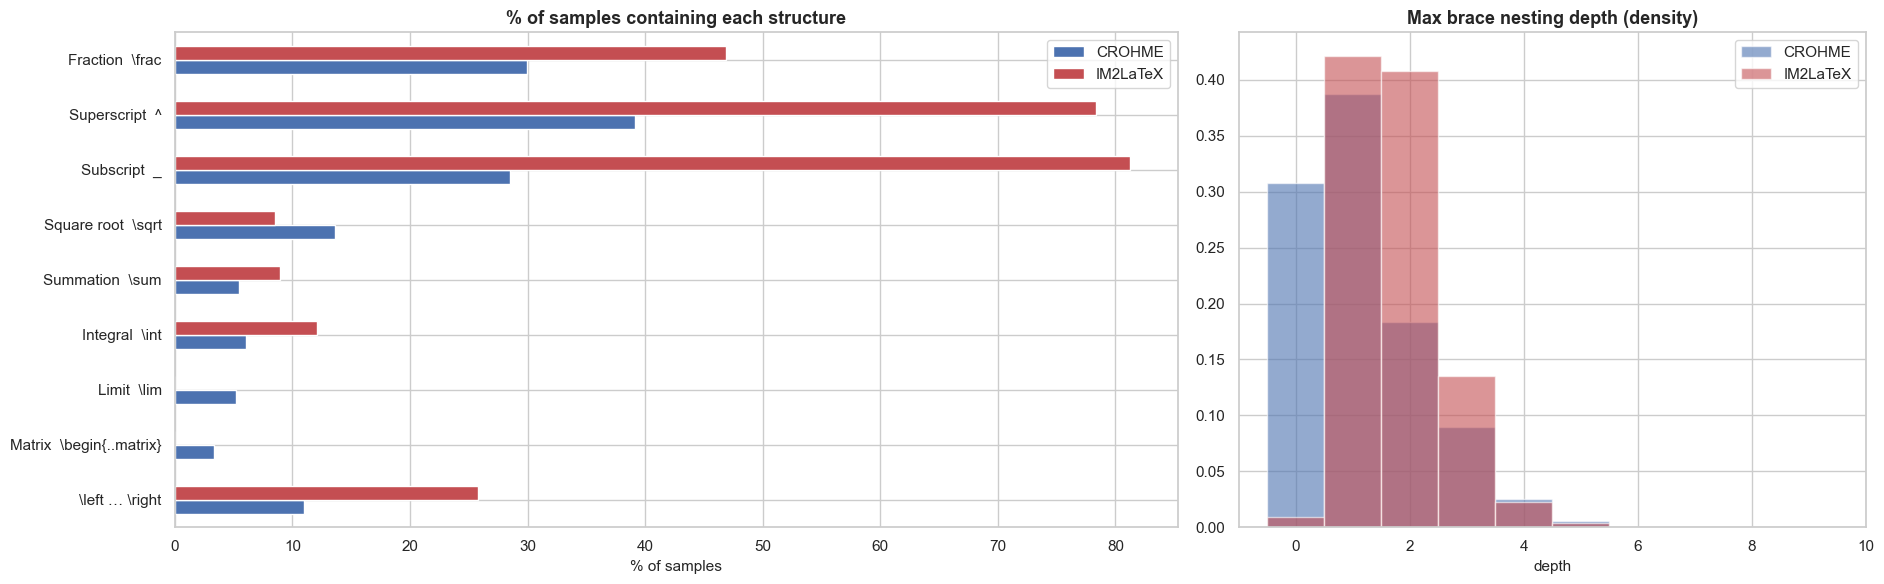

In [32]:
im_lab = im_df[im_df.n_tokens > 0]
im_struct = pd.DataFrame({k: im_lab.formula.str.contains(rx, regex=True) for k, rx in STRUCT_PATTERNS.items()})
im_overall = im_struct.mean() * 100
im_lab_depth = im_lab.formula.map(lambda s: max_brace_depth(s))

cmp = pd.DataFrame({"CROHME": overall, "IM2LaTeX": im_overall})
fig, axes = plt.subplots(1, 2, figsize=(19, 6), gridspec_kw={"width_ratios": [1.6, 1]})
cmp.iloc[::-1].plot(kind="barh", ax=axes[0], color=[PALETTE[0], PALETTE[3]]); axes[0].set_title("% of samples containing each structure"); axes[0].set_xlabel("% of samples")
bins = np.arange(0, int(max(crohme.brace_depth.max(), im_lab_depth.quantile(.999))) + 2) - 0.5
axes[1].hist(crohme.brace_depth, bins=bins, density=True, alpha=.6, color=PALETTE[0], label="CROHME")
axes[1].hist(im_lab_depth.clip(upper=bins[-1]), bins=bins, density=True, alpha=.6, color=PALETTE[3], label="IM2LaTeX")
axes[1].set_title("Max brace nesting depth (density)"); axes[1].set_xlabel("depth"); axes[1].legend()
plt.tight_layout(); plt.show()

#### 📌 Observation
- **97.1%** of IM2LaTeX formulas contain a 2-D construct vs **71.3%** in CROHME. Largest gaps: subscripts about 81% vs 28.6% (+52.7 pp), superscripts about 78% vs 39.1% (+39.2 pp), fractions about 47% vs 30.0% (+16.9 pp); `\left...\right` is about 26% vs 11.0%, integrals about 12% vs 6.0%, sums about 9% vs 5.4%.
- CROHME is richer where the pre-training data is poor: square roots 13.6% vs about 8.5%, **limits 5.2% vs about 0%** and **matrices 3.3% vs 0%** in IM2LaTeX.
- Nesting: IM2LaTeX almost never has depth 0 (about 1%) and concentrates at depths 1-2 (median 2), while **31% of CROHME expressions have depth 0** (median 1); P95 is 3 for both.

#### 💡 Pipeline / Engineering Decision
- IM2LaTeX pre-trains the structural decoder (scripts, fractions, nesting); CROHME fine-tunes it on handwriting, with the structures that IM2LaTeX lacks (`\lim`, matrices, `\sqrt`) up-weighted in fine-tuning.
- Matrix tokens and `\lim` get new embedding rows because pre-training never sees them.
- A shared structural-token inventory (`\frac ^ _ \sqrt { }`) is enforced across both datasets so decoder weights transfer without remapping.

---
## Step 31 — Image Dimensions & Their Link to Formula Length

### ❓ Why
A **hexbin of width vs height**, **width / height histograms**, and a **hexbin of token count vs image width (with Spearman ρ)** show whether images come in a few fixed sizes (easy to batch) or a continuum, and whether wider images really mean longer formulas. 
Hexbin is used because 100k points would overplot into a solid block.

### 💼 Business Insight
Image size drives **GPU memory and cost per image**. If width predicts length, we can batch by width to waste almost no compute; it also tells us the maximum resolution a phone upload must be resized to without losing small superscripts.

Reading IM2LaTeX headers:   0%|          | 0/3000 [00:00<?, ?it/s]

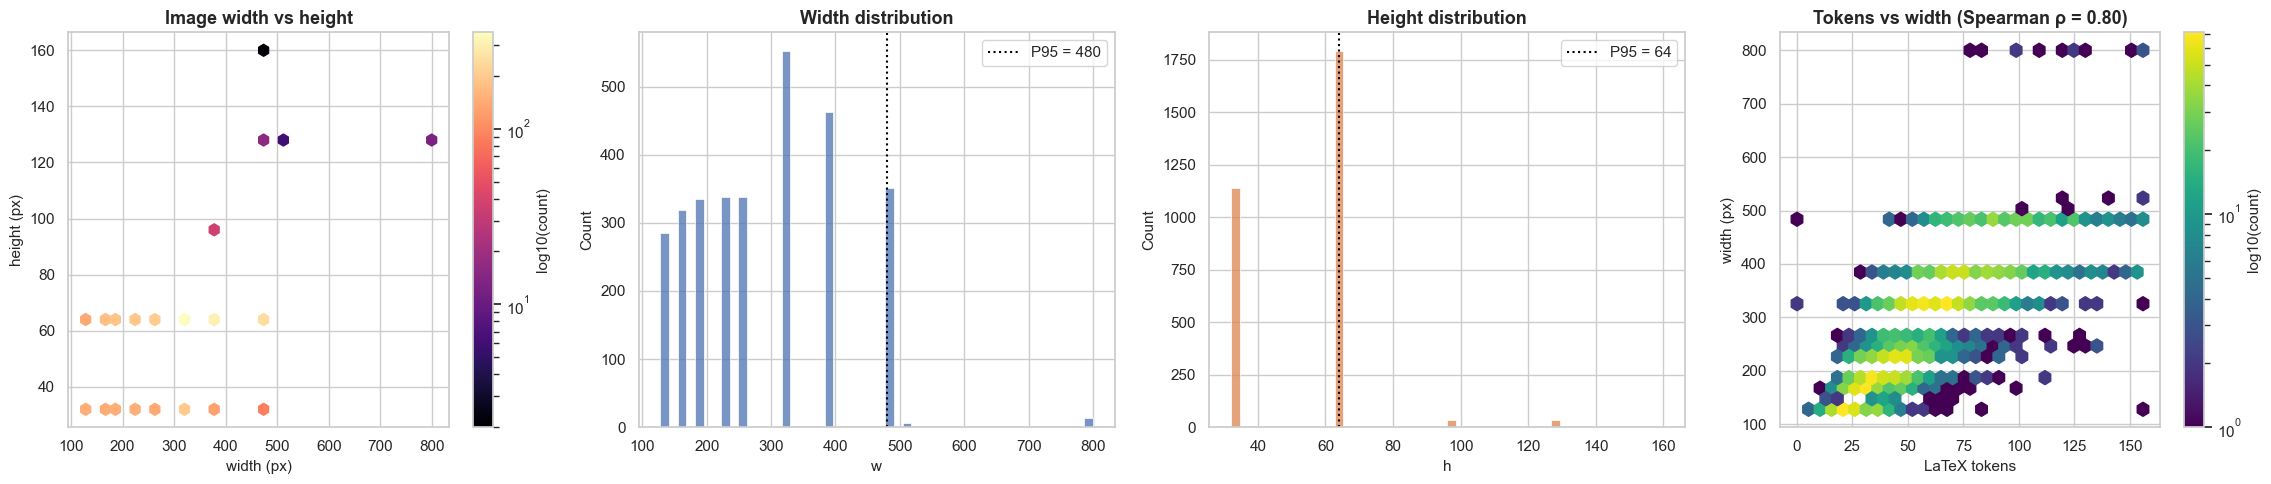

In [33]:
avail = im_df[im_df.path.notna()]
img_sample = avail.sample(min(IM2LATEX_IMAGE_SAMPLE, len(avail)), random_state=SEED).copy()
wh = []
for p in tqdm(img_sample.path, desc="Reading IM2LaTeX headers"):
    try:
        with Image.open(p) as im: wh.append((im.width, im.height, im.mode))
    except Exception: wh.append((np.nan, np.nan, None))
img_sample[["w", "h", "mode"]] = pd.DataFrame(wh, index=img_sample.index)
img_ok = img_sample.dropna(subset=["w", "h"]).copy()
img_ok["aspect"] = img_ok.w / img_ok.h

fig, axes = plt.subplots(1, 4, figsize=(23, 5))
hb = axes[0].hexbin(img_ok.w, img_ok.h, gridsize=35, cmap="magma", bins="log", mincnt=1); plt.colorbar(hb, ax=axes[0], label="log10(count)")
axes[0].set_title("Image width vs height"); axes[0].set_xlabel("width (px)"); axes[0].set_ylabel("height (px)")
sns.histplot(img_ok.w, bins=50, color=PALETTE[0], ax=axes[1]); axes[1].axvline(img_ok.w.quantile(.95), color="black", ls=":", label=f"P95 = {img_ok.w.quantile(.95):.0f}"); axes[1].legend(); axes[1].set_title("Width distribution")
sns.histplot(img_ok.h, bins=50, color=PALETTE[1], ax=axes[2]); axes[2].axvline(img_ok.h.quantile(.95), color="black", ls=":", label=f"P95 = {img_ok.h.quantile(.95):.0f}"); axes[2].legend(); axes[2].set_title("Height distribution")
hb2 = axes[3].hexbin(img_ok.n_tokens.clip(upper=img_ok.n_tokens.quantile(.995)), img_ok.w, gridsize=30, cmap="viridis", bins="log", mincnt=1); plt.colorbar(hb2, ax=axes[3], label="log10(count)")
rho_w, _ = stats.spearmanr(img_ok.n_tokens, img_ok.w)
axes[3].set_title(f"Tokens vs width (Spearman ρ = {rho_w:.2f})"); axes[3].set_xlabel("LaTeX tokens"); axes[3].set_ylabel("width (px)")
plt.tight_layout(); plt.show()

IM_IMG_H = int(math.ceil(img_ok.h.quantile(.95) / 32) * 32)
IM_IMG_W = int(math.ceil(img_ok.w.quantile(.95) / 32) * 32)
n_sizes = img_ok.groupby(["w", "h"]).ngroups

#### 📌 Observation
- On 3,000 sampled headers (0 unreadable) the images are **pre-bucketed, not continuous**: about **59% are 64 px high and 38% are 32 px high**, with only a few at 96, 128 and 160 px; widths take a few discrete values (roughly 128-256 in steps, then 320, 384, 480 and a rare 800). There are only **21 distinct (w×h) sizes**. Median width is 256, P95 480, max 800; height median and P95 are both 64.
- Tokens vs width has Spearman ρ = **0.80**; the hexbin shows it as horizontal bands because widths are discrete.
- All images are stored as RGB (100%) although the content is grayscale.

#### 💡 Pipeline / Engineering Decision
- The existing buckets are kept: batches are formed per (height, width) bucket with a cap of **64×480**; the rare 96-160 px and 800 px images are separate buckets or excluded from early epochs.
- Width is a good proxy for formula length, so batching by width bucket gives near-zero padding.
- Images are converted to single-channel grayscale. The 32-px-high images have half the resolution, so scale / blur augmentation is applied so the model sees both 32 px and 64 px text.

---
## Step 32 — Visual Inspection — IM2LaTeX Images With Their Ground Truth

### ❓ Why
Six samples (random, shortest and longest formula) are shown **with their LaTeX label as the title**. 
Eyeballing image ↔ label pairs is the only way to catch a broken join, cropped formulas or wrong rendering — problems that aggregate statistics cannot detect.

### 💼 Business Insight
This is the "does the data make sense?" check a client or reviewer will ask for. It also shows what a *clean, printed* formula looks like compared with the messy handwriting the product will face in the field — the domain gap we must close.

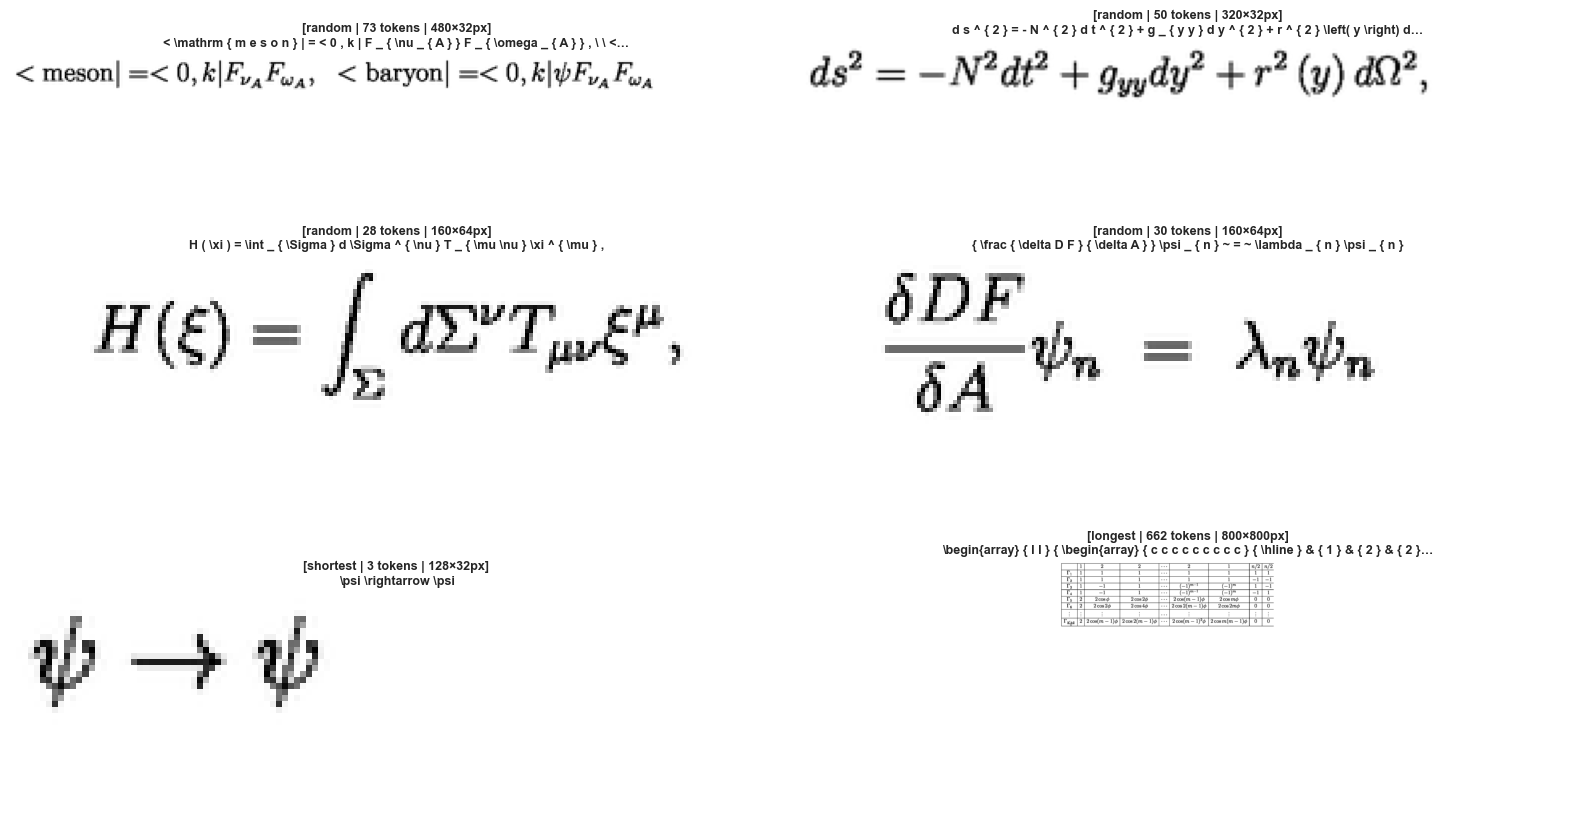

In [34]:
pool = avail[avail.n_tokens > 2]
picks = pd.concat([pool.sample(4, random_state=SEED).assign(tag="random"),
                   pool.nsmallest(1, "n_tokens").assign(tag="shortest"),
                   pool.nlargest(1, "n_tokens").assign(tag="longest")], ignore_index=True)
fig, axes = plt.subplots(3, 2, figsize=(16, 9))
for ax, (_, r) in zip(axes.ravel(), picks.iterrows()):
    arr, _ = load_gray(r.path); ax.imshow(arr, cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"[{r.tag} | {r.n_tokens} tokens | {arr.shape[1]}×{arr.shape[0]}px]\n{safe_title(r.formula, 95)}", fontsize=9)
plt.tight_layout(); plt.show()

#### 📌 Observation
- The six pairs show **low-resolution, anti-aliased renders** of physics-paper formulas (`ds^2 = -N^2 dt^2 + g_{yy} dy^2 + ...`, `< meson| = < 0, k | F_{\nu_A} ...`). Text is spelled letter by letter in the label (`\mathrm { m e s o n }`) and trailing commas are part of the label.
- The shortest sample is 3 tokens (`\psi \rightarrow \psi` at 128×32 px, only a few pixels per stroke). The **longest, 662 tokens, is a large `\begin{array}` table rendered at 800×800 px where the text is not readable**: it is a table, not a formula.
- Labels match the visible formulas, which confirms the image-to-formula join from Step 27.

#### 💡 Pipeline / Engineering Decision
- Table-like samples (`\begin{array}` with very long sequences, e.g. the 662-token one) and other extreme lengths are removed from training, because they cannot be read at that resolution.
- Trailing punctuation is kept as part of the target, and the letter-spelled `\mathrm { ... }` words are learned as letters.
- Handwriting-style augmentation (elastic warp, stroke thickness, blur) narrows the gap to CROHME. The six-sample panel is reused as a per-epoch qualitative check.

---
## Step 33 — IM2LaTeX Pixel Statistics — Polarity, Ink Ratio & Margins

### ❓ Why
Polarity bars, an **ink-ratio histogram** and **margin box-plots (left/right/top/bottom)** verify that the images are uniformly preprocessed and tell us how much of each image is real signal versus empty padding.

### 💼 Business Insight
Large empty margins waste compute and shift the formula position, which the model can wrongly learn as a cue. Uniform polarity and tight margins mean the pre-trained model sees *consistent* inputs — important when later transferring to user photos with arbitrary framing.

IM2LaTeX pixel stats:   0%|          | 0/1500 [00:00<?, ?it/s]

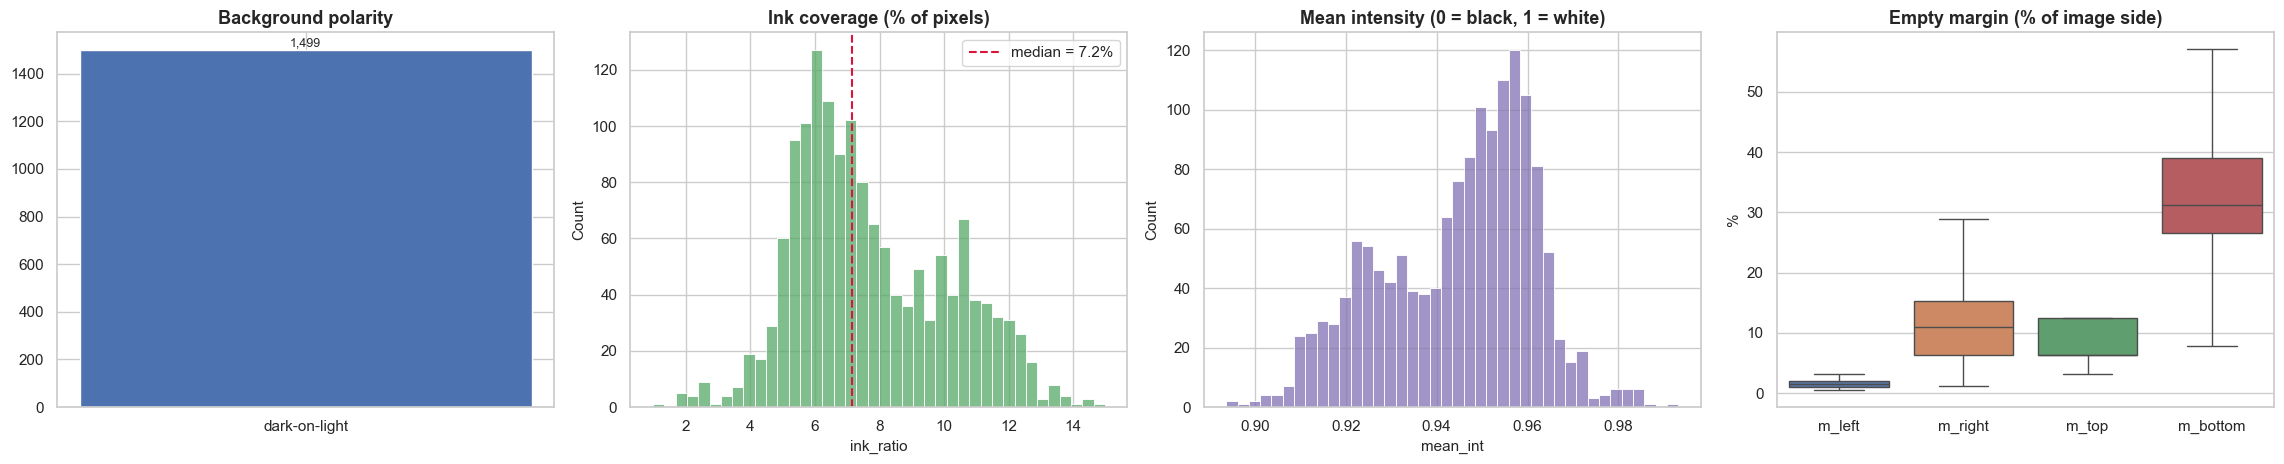

In [35]:
pix_sample = avail.sample(min(IM2LATEX_PIXEL_SAMPLE, len(avail)), random_state=SEED + 1)
rows = []
for p in tqdm(pix_sample.path, desc="IM2LaTeX pixel stats"):
    try: arr, bg = load_gray(p)
    except Exception: continue
    bb, ink_ratio = ink_bbox(arr, bg)
    h, w = arr.shape
    if bb is None: continue
    rows.append(dict(bg=bg, polarity="dark-on-light" if bg >= .5 else "light-on-dark", ink_ratio=ink_ratio, mean_int=float(arr.mean()),
                     m_left=bb[2] / w, m_right=(w - 1 - bb[3]) / w, m_top=bb[0] / h, m_bottom=(h - 1 - bb[1]) / h))
im_pix = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 4, figsize=(23, 4.8))
pc = im_pix.polarity.value_counts(); axes[0].bar(pc.index, pc.values, color=PALETTE[:len(pc)]); axes[0].set_title("Background polarity"); label_bars(axes[0], horizontal=False)
sns.histplot(im_pix.ink_ratio * 100, bins=40, color=PALETTE[2], ax=axes[1]); axes[1].axvline(im_pix.ink_ratio.median() * 100, color="crimson", ls="--", label=f"median = {im_pix.ink_ratio.median() * 100:.1f}%"); axes[1].legend(); axes[1].set_title("Ink coverage (% of pixels)")
sns.histplot(im_pix.mean_int, bins=40, color=PALETTE[4], ax=axes[2]); axes[2].set_title("Mean intensity (0 = black, 1 = white)")
sns.boxplot(data=im_pix[["m_left", "m_right", "m_top", "m_bottom"]].mul(100).melt(var_name="margin", value_name="pct"), x="margin", y="pct", showfliers=False, ax=axes[3], palette="deep")
axes[3].set_title("Empty margin (% of image side)"); axes[3].set_xlabel(""); axes[3].set_ylabel("%")
plt.tight_layout(); plt.show()

#### 📌 Observation
- On 1,499 images: polarity is **100% dark-on-light**, median ink coverage is **7.2%** (P5 4.6%, P95 12.1%) and the histogram is **bimodal (peaks near 6% and 10-11%)**, matching the two height buckets. Mean intensity is about 0.945, also bimodal (around 0.925 and 0.96).
- Margins show strong anchoring: left **1.6%**, top **6.2%**, right **10.9%** (IQR about 6-15%) and **bottom 31.2%** (IQR about 27-39%, whiskers 8-57%). Formulas sit at the top-left of each bucket canvas and the rest is white padding.
- Ink is sparse: more than 92% of the pixels are background.

#### 💡 Pipeline / Engineering Decision
- The top-left anchoring and the ~31% bottom padding are dataset artefacts, so random shift / pad augmentation is used to avoid learning a fixed-position cue that fails on user photos.
- Images are cropped to the ink box plus a small margin and re-bucketed (multiples of 16), which removes about a third of the pixels and speeds up training.
- Inputs are normalised with a fixed mean of about 0.945 computed on the training set, not per-image contrast stretching; the loss is token-level cross-entropy.

---
## Step 34 — IM2LaTeX Integrity & Leakage — Missing Files, Orphans & Formula Overlap

### ❓ Why
A **bar of integrity counts** (rows without an image, images without a row, empty formulas, duplicate ids) and a **bar of formula overlap between splits** quantify join quality and train/test leakage. 
IM2LaTeX is known to contain the *same formula rendered several times*, so leakage must be measured, not assumed away.

### 💼 Business Insight
If many test formulas also exist in training, the headline accuracy is partly memorisation. Reporting both **overall** and **unseen-formula** accuracy gives a clean, defensible performance claim for customers.

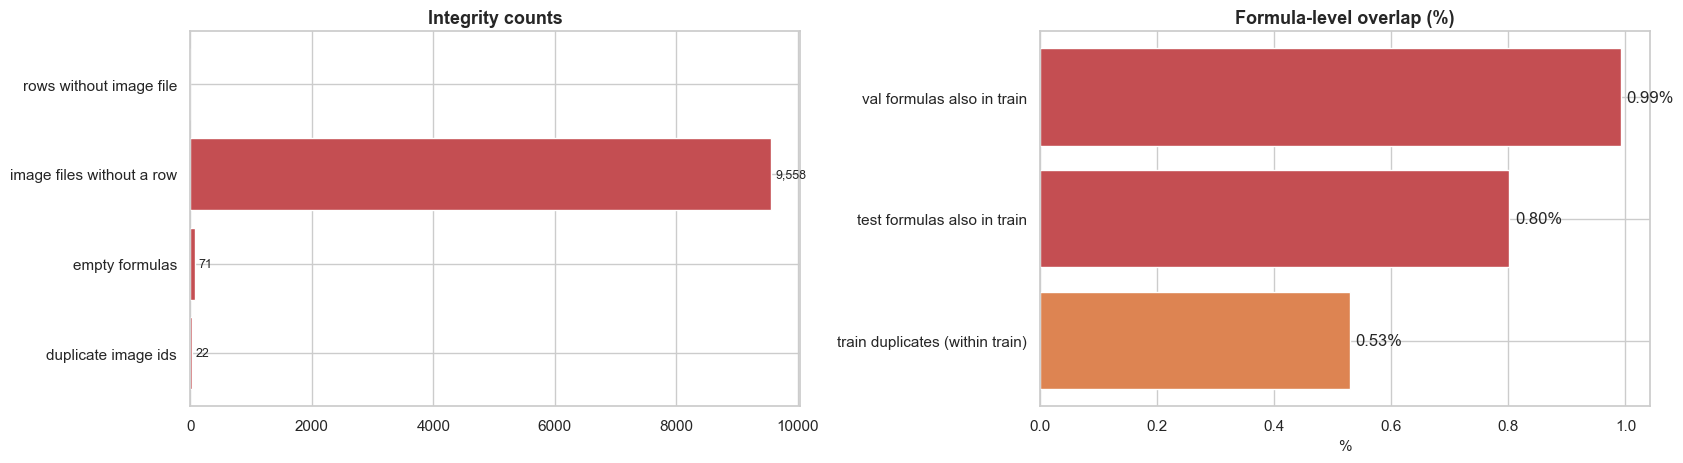

In [36]:
rows_missing_img = int(im_df.path.isna().sum())
csv_stems = set(im_df.stem)
orphans = [s for s in img_lookup if s not in csv_stems]
empty_formula = int((im_df.n_tokens == 0).sum())
dup_ids = int(im_df.stem.duplicated().sum())

norm_f = im_df.formula.str.replace(" ", "", regex=False)
train_f = set(norm_f[im_df.split == "train"])
leak = {s: norm_f[im_df.split == s].isin(train_f) for s in ["val", "test"]}
leak_pct = {s: float(v.mean() * 100) for s, v in leak.items()}
leak_n = {s: int(v.sum()) for s, v in leak.items()}
train_dup = float(norm_f[im_df.split == "train"].duplicated().mean() * 100)
stem_overlap = len(set(im_df.stem[im_df.split == "train"]) & set(im_df.stem[im_df.split == "test"]))

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
integ = pd.Series({"rows without image file": rows_missing_img, "image files without a row": len(orphans), "empty formulas": empty_formula, "duplicate image ids": dup_ids})
axes[0].barh(integ.index[::-1], integ.values[::-1], color=[PALETTE[3] if v else PALETTE[2] for v in integ.values[::-1]]); axes[0].set_title("Integrity counts"); label_bars(axes[0])
lk = pd.Series({"val formulas also in train": leak_pct["val"], "test formulas also in train": leak_pct["test"], "train duplicates (within train)": train_dup})
axes[1].barh(lk.index[::-1], lk.values[::-1], color=[PALETTE[1], PALETTE[3], PALETTE[3]]); axes[1].set_title("Formula-level overlap (%)"); axes[1].set_xlabel("%")
for i, v in enumerate(lk.values[::-1]): axes[1].annotate(f"{v:.2f}%", (v, i), xytext=(4, 0), textcoords="offset points", va="center")
plt.tight_layout(); plt.show()

#### 📌 Observation
- Integrity: **0 rows without an image**, **9,558 image files not referenced by any row** (103,536 files minus the 93,978 unique stems used), **71 empty formulas** and **22 duplicated image ids** (4 shared between train and test).
- Leakage: **0.80% of test formulas (83) and 0.99% of validation formulas (83) also appear verbatim in train**, and 0.53% of train rows repeat an earlier formula.
- The orphan count is exactly the part of the image folder that the split tables dropped; the formulas themselves cannot be recovered for them because the split tables have no index column.

#### 💡 Pipeline / Engineering Decision
- The 71 empty rows are dropped and the 22 duplicated ids are de-duplicated (first kept; the 4 train/test shared ids are removed from train). The 9,558 orphan images are ignored by the loader.
- Since 99.2% of test formulas are unseen, a single headline number stays valid, but evaluation also reports accuracy on the unseen-formula subset.
- All exclusions are written to a data-quality log in the pipeline, with counts compared against this audit on every refresh.

# 🅳 PART D — Cross-Dataset Synthesis
The three datasets are only useful **together**. This part measures how well they cover each other's vocabulary, compares them on one scale, and converts every finding of the notebook into a single **pipeline blueprint**.

---
## Step 35 — Cross-Dataset Vocabulary Coverage — Can We Pre-Train and Transfer?

### ❓ Why
Bars show **what fraction of CROHME's token mass is covered** by (a) the IM2LaTeX vocabulary and (b) the 19 symbol classes, a stacked bar splits tokens into *shared / CROHME-only / IM2LaTeX-only*, and a **Top-15 uncovered-token list** names the exact gaps. 
Coverage is measured by token *frequency mass*, not by type count, because missing a rare token matters far less than missing `\frac`.

### 💼 Business Insight
This is the core data-strategy question: *can the huge printed dataset teach the model symbols that the small handwritten dataset barely contains?* High coverage means pre-training transfers; the uncovered list tells us exactly which symbols still need dedicated handwritten data collection.

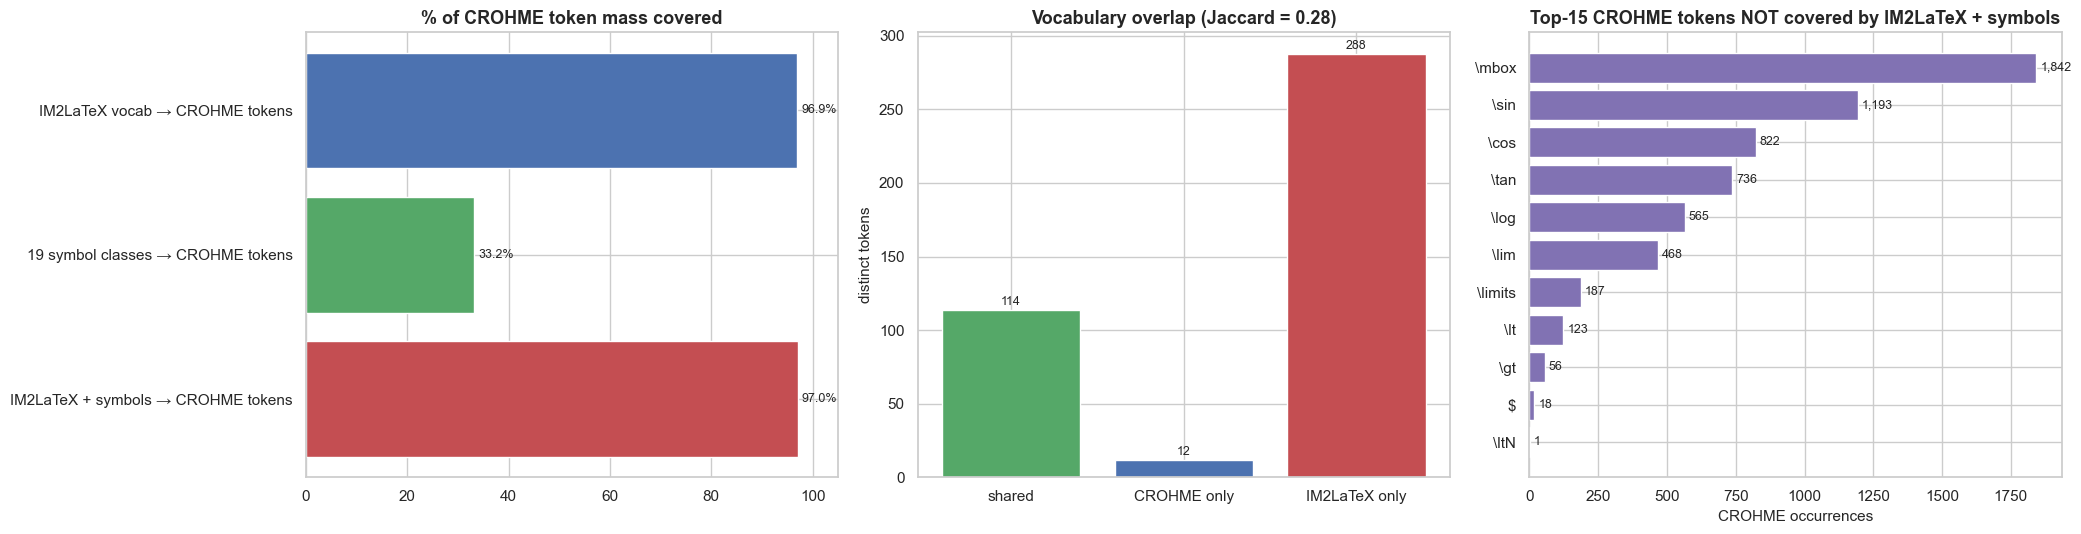

In [37]:
sym_tokens = set(SYMBOL_TO_LATEX.get(c, c) for c in SYM_CLASSES)
cro_tokens = set(tok_counter)
im_tokens_set = set(t for t, c in im_counter.items() if c >= MIN_TOKEN_FREQ)
cro_total = sum(tok_counter.values())

def mass_covered(vocab):
    return 100.0 * sum(c for t, c in tok_counter.items() if t in vocab) / cro_total

cov = pd.Series({"IM2LaTeX vocab → CROHME tokens": mass_covered(im_tokens_set),
                 f"{len(SYM_CLASSES)} symbol classes → CROHME tokens": mass_covered(sym_tokens),
                 "IM2LaTeX + symbols → CROHME tokens": mass_covered(im_tokens_set | sym_tokens)})
shared = cro_tokens & im_tokens_set
venn = pd.Series({"shared": len(shared), "CROHME only": len(cro_tokens - im_tokens_set), "IM2LaTeX only": len(im_tokens_set - cro_tokens)})
jaccard = len(shared) / len(cro_tokens | im_tokens_set)
uncovered = pd.Series({t: c for t, c in tok_counter.items() if t not in (im_tokens_set | sym_tokens)}).sort_values(ascending=False)
not_in_symbols = pd.Series({t: c for t, c in tok_counter.items() if t not in sym_tokens}).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
axes[0].barh(cov.index[::-1], cov.values[::-1], color=[PALETTE[3], PALETTE[2], PALETTE[0]]); axes[0].set_xlim(0, 105); axes[0].set_title("% of CROHME token mass covered"); label_bars(axes[0], fmt="{:.1f}%")
axes[1].bar(venn.index, venn.values, color=[PALETTE[2], PALETTE[0], PALETTE[3]]); axes[1].set_title(f"Vocabulary overlap (Jaccard = {jaccard:.2f})"); axes[1].set_ylabel("distinct tokens"); label_bars(axes[1], horizontal=False)
show = (uncovered.head(15) if len(uncovered) else not_in_symbols.head(15)).iloc[::-1]
axes[2].barh(show.index, show.values, color=PALETTE[4])
axes[2].set_title("Top-15 CROHME tokens NOT covered by IM2LaTeX + symbols" if len(uncovered) else "Top-15 CROHME tokens not among the 16 symbol classes"); axes[2].set_xlabel("CROHME occurrences"); label_bars(axes[2])
plt.tight_layout(); plt.show()

# unified vocabulary for the handwritten model: CROHME tokens + frequent IM2LaTeX tokens (CROHME order first)
UNIFIED_VOCAB = list(dict.fromkeys(CROHME_VOCAB + IM_VOCAB))

#### 📌 Observation
- The IM2LaTeX vocabulary covers **96.94%** of CROHME's token mass, the 19 symbol classes alone cover **33.2%**, and the union **97.05%**. Types: **114 shared, 12 CROHME-only, 288 IM2LaTeX-only** (Jaccard 0.28).
- The uncovered CROHME tokens are about 3% of its mass and are **spelling conventions, not missing mathematics**: `\mbox` 1,842, `\sin` 1,193, `\cos` 822, `\tan` 736, `\log` 565, `\lim` 468, `\limits` 187, `\lt` 123, `\gt` 56, `$` 18, `\ltN` 1.
- The symbol dataset contains none of the structural tokens that dominate CROHME (`{`, `}`, `^`, `_`, `\frac`), so it is only a symbol-level resource.

#### 💡 Pipeline / Engineering Decision
- Before pre-training, a **spelling map** is built between the two conventions: check how IM2LaTeX writes `sin / cos / tan / log / lim` (likely wrapped in `\mathrm`), then map CROHME to that form; `\lt`, `\gt` become `<`, `>` (Step 16), `\mbox{...}` becomes `\mathrm{...}`, and `$` / `\ltN` (19 occurrences) are removed as noise. After this, coverage is expected to be close to 100%.
- The unified vocabulary has **417 tokens** (CROHME 127 ∪ IM2LaTeX 406), so decoder weights transfer to fine-tuning.
- Math Symbols is used for encoder warm-up and an auxiliary symbol head only.

---
## Step 36 — Dataset Comparison Dashboard — Scale, Length & Modality

### ❓ Why
One **summary table** and two comparison plots (**sample counts on a log axis** and **token-length distributions on a log axis**) put all three datasets on the same scale. 
Side-by-side comparison exposes the real asymmetry: orders of magnitude in size and a large gap in expression length.

### 💼 Business Insight
This is the slide an executive reads: *how much data do we have, in which form, and where is it thin?* It frames the investment case — e.g. collecting more handwritten long-expression data is worth more than another million printed formulas.

,dataset,modality,samples,vocab,median_tokens,p95_tokens,input,label_source
0,CROHME (strokes),online pen strokes → raster,"11,471",127,16,39,64×512 px (est.),LaTeX (human)
1,Math Symbols,offline symbol image,"10,071",19,1,1,64×64 px,class folder
2,IM2LaTeX-100k,offline formula image,"94,000",406,53,117,≤64×480 px,LaTeX (rendered)


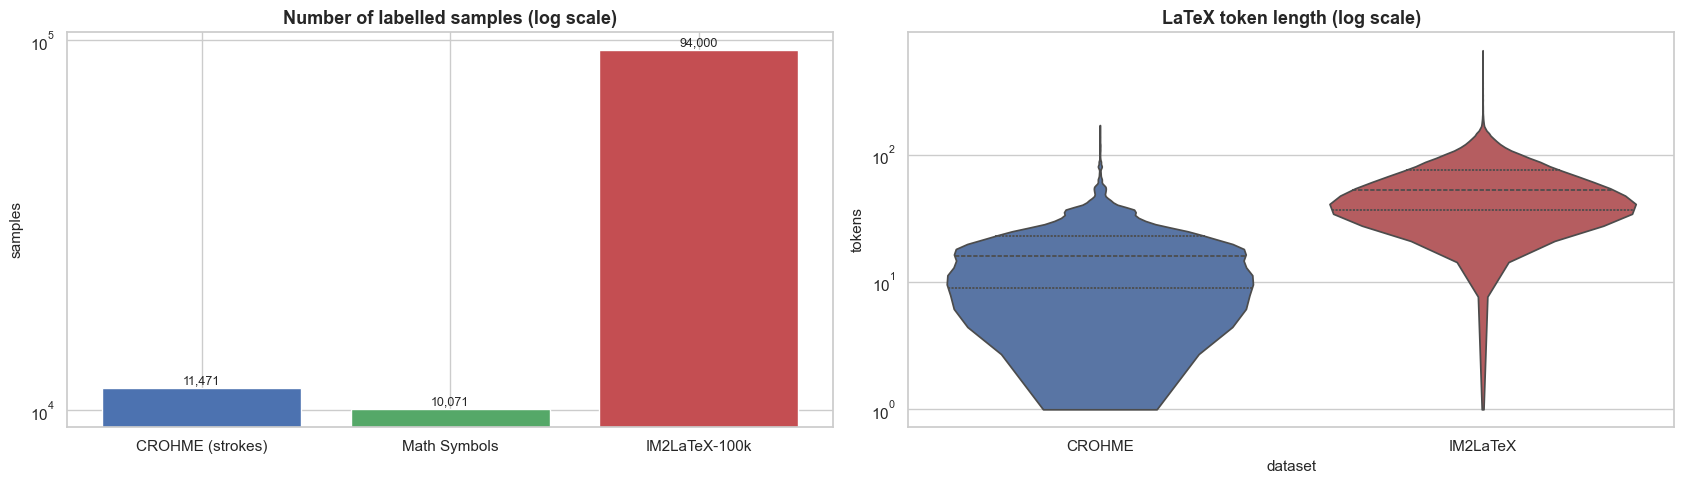

In [38]:
cmp_tbl = pd.DataFrame([
    dict(dataset="CROHME (strokes)",   modality="online pen strokes → raster", samples=len(crohme),   vocab=len(CROHME_VOCAB),
         median_tokens=crohme.n_tokens.median(), p95_tokens=crohme.n_tokens.quantile(.95), input="64×%d px (est.)" % CROHME_IMG_W, label_source="LaTeX (human)"),
    dict(dataset="Math Symbols",       modality="offline symbol image",        samples=len(sym_idx),  vocab=len(SYM_CLASSES),
         median_tokens=1, p95_tokens=1, input=f"{SYM_INPUT}×{SYM_INPUT} px", label_source="class folder"),
    dict(dataset="IM2LaTeX-100k",      modality="offline formula image",       samples=len(im_df),    vocab=len(IM_VOCAB),
         median_tokens=lab.n_tokens.median(), p95_tokens=lab.n_tokens.quantile(.95), input=f"≤{IM_IMG_H}×{IM_IMG_W} px", label_source="LaTeX (rendered)"),
])
display(cmp_tbl.style.format({"samples": "{:,.0f}", "vocab": "{:,.0f}", "median_tokens": "{:.0f}", "p95_tokens": "{:.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
cols = [PALETTE[0], PALETTE[2], PALETTE[3]]
axes[0].bar(cmp_tbl.dataset, cmp_tbl.samples, color=cols); axes[0].set_yscale("log"); axes[0].set_title("Number of labelled samples (log scale)"); axes[0].set_ylabel("samples")
label_bars(axes[0], horizontal=False)
len_df = pd.concat([crohme[["n_tokens"]].assign(dataset="CROHME"), lab[["n_tokens"]].assign(dataset="IM2LaTeX")], ignore_index=True)
sns.violinplot(data=len_df, x="dataset", y="n_tokens", hue="dataset", palette=[PALETTE[0], PALETTE[3]], cut=0, inner="quartile", ax=axes[1], legend=False)
axes[1].set_yscale("log"); axes[1].set_title("LaTeX token length (log scale)"); axes[1].set_ylabel("tokens")
plt.tight_layout(); plt.show()

#### 📌 Observation
- Scale: IM2LaTeX has **94,000** labelled samples, CROHME 11,471 (about 10,282 unique after Step 17) and Math Symbols 10,071, so IM2LaTeX is **8.2×** larger than CROHME (about 9× after de-duplication).
- Length: median 53 vs 16 tokens and P95 117 vs 39. In the violin plot CROHME is concentrated between 1 and about 40 tokens with a thin tail to 171, while IM2LaTeX sits at about 30-100 with a tail to 662. Vocabulary sizes: 406 vs 127 vs 19.
- Each dataset lacks one ingredient: CROHME has real handwriting with full labels but is small, Math Symbols has handwriting without context, and IM2LaTeX has context and scale but only printed text.

#### 💡 Pipeline / Engineering Decision
- Roles: **IM2LaTeX for pre-training, CROHME for fine-tuning and the handwritten benchmark, Math Symbols for encoder warm-up and symbol checks.**
- Fine-tuning batches use explicit mixing ratios; the starting point is 60% CROHME-raster, 30% IM2LaTeX, 10% symbols, tuned on validation, so IM2LaTeX cannot drown the small handwritten set but still prevents forgetting.
- The first data-collection priority is **long, structured handwritten expressions** (the thinnest slice: CROHME is short and IM2LaTeX has no handwriting); the 1,507 unlabelled test expressions are the cheapest source to label.

---
## Step 37 — Final Pipeline Blueprint — From Findings to Engineering Decisions

### ❓ Why
EDA only pays off if it ends in **concrete parameters**. This step gathers every number decided above into one blueprint table (image sizes, sequence limits, vocabularies, split strategy, augmentation, curriculum) and prints the complete decision log, step by step.

### 💼 Business Insight
This is the hand-off artefact between data analysis and model engineering: each row is traceable to a plot in this notebook, which makes every modelling choice **auditable** and cheap to revisit when new data arrives.

In [39]:
blueprint = pd.DataFrame([
    ("Input · CROHME",          f"strokes → normalise (translate + scale longest side) → raster H={CROHME_IMG_H}, W≤{CROHME_IMG_W}", "Step 11, 15"),
    ("Input · Math Symbols",    f"grayscale, polarity-normalised, letter-boxed to {SYM_INPUT}×{SYM_INPUT}", "Step 20, 22, 23"),
    ("Input · IM2LaTeX",        f"grayscale, width/height buckets (multiples of 32), cap {IM_IMG_H}×{IM_IMG_W}", "Step 31, 33"),
    ("Max decode length",       f"CROHME {MAX_LEN_CROHME} · IM2LaTeX {MAX_LEN_IM2LATEX} (P99 + <sos>/<eos>)", "Step 8, 28"),
    ("Vocabulary",              f"unified {len(UNIFIED_VOCAB):,} tokens (CROHME {len(CROHME_VOCAB):,} ∪ IM2LaTeX {len(IM_VOCAB):,}), min-freq {MIN_TOKEN_FREQ}", "Step 9, 29, 35"),
    ("Label cleaning",          "canonical synonyms, drop unbalanced-brace / non-ASCII labels, group duplicate formulas", "Step 16"),
    ("Splitting strategy",      "dedupe by content hash; writer/source-grouped split for CROHME; stratified for symbols; official split for IM2LaTeX", "Step 13, 17, 19, 24, 34"),
    ("Class / sample balance",  f"symbols imbalance {imb_ratio:.2f}× → {'weighted loss' if imb_ratio >= 1.5 else 'no re-weighting'}; oversample matrices & rare tokens", "Step 9, 18, 19"),
    ("Augmentation",            "stroke jitter/slant/thickness (online), small rotation/scale, NO flips, handwriting-style warp on IM2LaTeX, random margins", "Step 15, 21, 32, 33"),
    ("Decoding constraints",    "bracket-balance guard; `&`/`\\\\` only inside matrix environments", "Step 10, 18"),
    ("Training curriculum",     "symbols encoder warm-up → IM2LaTeX pre-training (short→long) → CROHME fine-tuning with explicit dataset ratios", "Step 30, 35, 36"),
    ("Evaluation",              "expression rate + token edit distance, per edition, per length bucket, 2-D vs linear, matrix & rare-token recall, seen vs unseen formulas", "Step 8, 10, 17, 34"),
], columns=["Component", "Decision", "Evidence"])
pd.set_option("display.max_colwidth", None)
display(blueprint.style.hide(axis="index").set_properties(**{"text-align": "left"}))


Component,Decision,Evidence
Input · CROHME,"strokes → normalise (translate + scale longest side) → raster H=64, W≤512","Step 11, 15"
Input · Math Symbols,"grayscale, polarity-normalised, letter-boxed to 64×64","Step 20, 22, 23"
Input · IM2LaTeX,"grayscale, width/height buckets (multiples of 32), cap 64×480","Step 31, 33"
Max decode length,CROHME 67 · IM2LaTeX 152 (P99 + /),"Step 8, 28"
Vocabulary,"unified 417 tokens (CROHME 127 ∪ IM2LaTeX 406), min-freq 5","Step 9, 29, 35"
Label cleaning,"canonical synonyms, drop unbalanced-brace / non-ASCII labels, group duplicate formulas",Step 16
Splitting strategy,dedupe by content hash; writer/source-grouped split for CROHME; stratified for symbols; official split for IM2LaTeX,"Step 13, 17, 19, 24, 34"
Class / sample balance,symbols imbalance 3.09× → weighted loss; oversample matrices & rare tokens,"Step 9, 18, 19"
Augmentation,"stroke jitter/slant/thickness (online), small rotation/scale, NO flips, handwriting-style warp on IM2LaTeX, random margins","Step 15, 21, 32, 33"
Decoding constraints,bracket-balance guard; `&`/`\\` only inside matrix environments,"Step 10, 18"


#### 📌 Observation
- The notebook covered 37 steps. Headline numbers: **CROHME** 11,471 labelled expressions (about 10,282 unique), 127-token vocabulary, max length 67; **Math Symbols** 10,071 images in 19 classes, 43.2% nearest-centroid baseline; **IM2LaTeX** 94,000 pairs, 406-token vocabulary, max length 152; unified vocabulary 417.
- Real-data risks found: no labelled official test for 2011-2013 (1,507 unlabelled files), 18.3% duplicate CROHME files, tokenizer artefacts, two image sources and a ruled-line artefact in the symbols, digits as the hard class group, pre-bucketed and padded IM2LaTeX images with an 800×800 table outlier, and spelling mismatches (`\sin`, `\lim`, `\mbox`).
- The blueprint table printed above holds the first-pass values; the revisions below are what the real outputs changed.

#### 💡 Pipeline / Engineering Decision
**Revised blueprint (the table below overrides the code table where they differ):**

| Component | Revised decision | Evidence |
|---|---|---|
| Evaluation | Own grouped 80/10/10 split from labelled folders; `MatricesTest2014` only as a matrix benchmark | Steps 5, 6 |
| De-duplication | Hash-dedupe CROHME (about 10,282 unique) and symbols (449 duplicates); group splits by hash | Steps 17, 24 |
| Tokenizer | v2: `\begin{..}`, `\end{..}`, `\mbox{..}` atomic; spelling map to IM2LaTeX conventions | Steps 9, 18, 35 |
| Label cleaning | `\rightarrow→\to`, `\lt/\gt→</>`, `\ldots/\cdots` merged; per-label cap (ten labels occur 81×) | Step 16 |
| CROHME input | Per-sample normalisation, arc-length resampling, raster 64×≤512 (7.2% at cap) | Steps 11, 12, 15 |
| Symbols input | 64×64, ruled-line removal, ink-box re-centre without rescale, split stratified by class and source | Steps 20-23 |
| Symbols model | CNN with weighted loss (`z` weight 2.5), hard-pair mining for digits | Steps 19, 25, 26 |
| IM2LaTeX input | Keep (h, w) buckets, cap 64×480, crop bottom padding, random shift, drop table / outlier samples | Steps 31-33 |
| Evaluation of IM2LaTeX | No truncation on test; report per length bucket and on unseen formulas | Steps 28, 34 |
| Curriculum | Symbols warm-up → IM2LaTeX pre-training → CROHME fine-tuning (60/30/10 start mix) | Steps 30, 36 |


Next milestone: implement `src/` (config, validators, tokenizer v2, preprocessing) from this table, then train the symbol CNN baseline and the encoder-decoder on the curriculum.

---
## ✅ Summary & Next Steps

| Area | Key takeaway |
|---|---|
| **CROHME** | Real handwriting with full LaTeX labels — small, multi-source, multi-scale, with cross-edition duplicates; needs per-sample normalisation, hash de-duplication and writer/source-grouped splits |
| **Math Symbols** | Clean, small, near-balanced classes; confusable pairs (`x`/`mul`, `1`/`div`, `sub`/`eq`) require expression-level context, not a bigger symbol CNN |
| **IM2LaTeX** | Large, clean, printed — ideal for pre-training structure and long sequences; must be measured for formula leakage and the printed→handwritten domain gap |
| **Together** | Three-stage curriculum (symbols → IM2LaTeX → CROHME) with a unified vocabulary and explicit dataset sampling ratios |

**Recommended next steps**
1. Implement `src/` modules (config, data loaders, preprocessing, tokenizer, leakage check) using the blueprint above.
2. Train the symbol CNN baseline and beat the nearest-centroid score from Step 25.
3. Train the image→LaTeX encoder–decoder with the three-stage curriculum and evaluate per edition / length bucket.
4. Add champion–challenger gates, a monitoring dashboard (vocabulary / length / polarity drift) and an API for serving.